# Project 6 — Part 1: Data Preparation, Cleaning, Feature Engineering & EDA
### Sales Forecasting Across Multiple Retail Stores (Rossmann Pharmaceuticals)

**Business problem.** Rossmann wants to forecast the daily sales of its stores about **six weeks ahead**. Today store managers rely on experience and judgement. Sales are influenced by promotions, competition, school and state holidays, seasonality, locality, customer behaviour and store characteristics.

**Goal of this notebook (Part 1).** Data → Cleaning → EDA → Feature-engineering foundation. No model is trained here; the notebook produces the clean data and the reusable feature code that Part 2 (ML + LSTM) will use.

| Section | Content |
|---|---|
| 1 | Setup, data loading and initial inspection |
| 2 | Data-quality and **missing-value** analysis |
| 3 | Cleaning pipeline and **outlier** analysis |
| 4 | Date processing and feature-engineering foundation (leakage-safe) |
| 5 | Univariate, bivariate and multivariate analysis, correlations and interactions |
| 6 | **The 11 required business questions** (Q1–Q11) |
| 7 | Key findings, business insights, modelling implications |

#### Data definitions (kept exactly as in the project brief)

| Field | Meaning |
|---|---|
| `Sales` | Daily turnover — the **target** |
| `Customers` | Number of customers that day (only in train → not available at prediction time) |
| `Open` | `0` = closed, `1` = open |
| `StateHoliday` | `a` = public holiday, `b` = Easter holiday, `c` = Christmas, `0` = no state holiday |
| `SchoolHoliday` | Store/date was affected by closure of public schools |
| `StoreType` | four store models: `a`, `b`, `c`, `d` |
| `Assortment` | `a` = basic, `b` = extra, `c` = extended |
| `CompetitionDistance` | distance in metres to the nearest competitor |
| `CompetitionOpenSince[Month/Year]` | approximate month / year the nearest competitor opened |
| `Promo` | store runs a promotion on that day |
| `Promo2` | continuing promotion: `0` = not participating, `1` = participating |
| `Promo2Since[Year/Week]` | calendar year / week when the store started Promo2 |
| `PromoInterval` | months in which Promo2 restarts, e.g. `Feb,May,Aug,Nov` |

## 1. Setup, data loading and initial inspection

In [2]:
import sys, logging, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# make the project importable no matter where Jupyter was started
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.utils.config import load_config, get_dir
from src.utils.logger import setup_logging
from src.utils.constants import (STATE_HOLIDAY_LABELS, ASSORTMENT_LABELS, DAY_NAMES,
                                 MONTH_NAMES, PROMO2_LABELS, OPEN_LABELS)
from src.data.loader import load_raw_data
from src.data.inspection import data_quality_summary, basic_inspection
from src.data.make_dataset import run_pipeline
from src.data.outliers import handle_outliers
from src.features.history_features import compute_store_history_stats, add_store_history_features
from src.visualization.plotting import (COLORS, PALETTE, set_plot_style, thousands, percent,
                                        label_bars, save_figure)

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
setup_logging(cfg)                      # console + logs/project.log
log = logging.getLogger("src.eda")
set_plot_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
SEED = cfg["project"]["random_seed"]
np.random.seed(SEED)
log.info("EDA notebook started (project root: %s)", ROOT)

2026-11-15 21:58:00,785 | INFO     | src.eda | EDA notebook started (project root: c:\Users\karan\OneDrive\Desktop\Intelligent Retail Sales Forecasting Using Machine Learning and Deep Learning\project_6)


In [4]:

import sys
from pathlib import Path

# Find the project root automatically
current = Path.cwd().resolve()

project_root = next(
    (
        p for p in [current, *current.parents]
        if (p / "src" / "data" / "loader.py").is_file()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Project root not found. Could not locate src/data/loader.py"
    )

# Add project root to Python path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("Project path added successfully!")


Project root: C:\Users\karan\OneDrive\Desktop\Intelligent Retail Sales Forecasting Using Machine Learning and Deep Learning\project_6
Project path added successfully!


In [5]:

from src.utils.config import load_config

cfg = load_config()

print("Configuration loaded successfully!")
print("Project root:", cfg["_root"])
print("Raw directory:", cfg["paths"]["raw_dir"])


Configuration loaded successfully!
Project root: C:\Users\karan\OneDrive\Desktop\Intelligent Retail Sales Forecasting Using Machine Learning and Deep Learning\project_6
Raw directory: data/raw


In [6]:

from IPython.display import display, Markdown

print("Markdown imported successfully!")


Markdown imported successfully!


In [7]:

from src.data.loader import load_raw_data

print("load_raw_data imported successfully!")


load_raw_data imported successfully!


In [8]:
from src.utils.config import load_config

cfg = load_config()

print("Configuration loaded successfully!")
print(cfg)

Configuration loaded successfully!
{'project': {'name': 'rossmann_sales_forecasting', 'random_seed': 42}, 'paths': {'raw_dir': 'data/raw', 'processed_dir': 'data/processed', 'figures_dir': 'reports/figures', 'logs_dir': 'logs'}, 'raw_files': {'train': 'train.csv', 'test': 'test.csv', 'store': 'store.csv', 'sample_submission': 'sample_submission.csv'}, 'processed_files': {'train': 'train_processed.parquet', 'test': 'test_processed.parquet', 'store': 'store_processed.csv', 'holiday_calendar': 'holiday_calendar.csv', 'manifest': 'feature_manifest.json', 'cleaning_report': 'cleaning_report.json'}, 'cleaning': {'outlier': {'method': 'mad', 'threshold': 5.0, 'group_cols': ['Store', 'DayOfWeek', 'Promo'], 'action': 'flag'}}, 'features': {'holiday': {'cap_days': 30, 'window_days': 3, 'national_share': 0.95}, 'history': {'validation_days': 42}}, 'logging': {'level': 'INFO', 'file': 'project.log', 'format': '%(asctime)s | %(levelname)-8s | %(name)s | %(message)s'}, '_root': 'C:\\Users\\karan\\On

In [9]:

import logging

# Configure logging
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s"
)

log = logging.getLogger(__name__)

print("Logger initialized successfully!")


Logger initialized successfully!


In [10]:
log.info("Section 1: loading raw data")
raw = load_raw_data(cfg, include_sample_submission=True)   # raises a clear error if a file is missing
for name in ["train", "test", "store"]:
    df = raw[name]
    display(Markdown(f"#### `{name}` — {df.shape[0]:,} rows × {df.shape[1]} columns"))
    display(df.head(3)); display(df.tail(2))
print("sample_submission:", raw["sample_submission"].shape, "| same Ids as test:",
      bool((raw["sample_submission"]["Id"].values == raw["test"]["Id"].values).all()))

2026-11-15 21:58:26,668 | INFO | __main__ | Section 1: loading raw data


2026-11-15 21:58:27,778 | INFO     | src.data.loader | Loaded train             from train.csv -> 1017209 rows x 9 cols
2026-11-15 21:58:27,849 | INFO     | src.data.loader | Loaded test              from test.csv -> 41088 rows x 8 cols
2026-11-15 21:58:27,866 | INFO     | src.data.loader | Loaded store             from store.csv -> 1115 rows x 10 cols
2026-11-15 21:58:27,887 | INFO     | src.data.loader | Loaded sample_submission from sample_submission.csv -> 41088 rows x 2 cols


#### `train` — 1,017,209 rows × 9 columns

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
1017207,1114,2,2013-01-01,0,0,0,0,a,1
1017208,1115,2,2013-01-01,0,0,0,0,a,1


#### `test` — 41,088 rows × 8 columns

... (2 outputs left out)

#### `store` — 1,115 rows × 10 columns

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,"1,270.000",9.000,"2,008.000",0,NaN,NaN,NaN
1,2,a,a,570.000,11.000,"2,007.000",1,13.000,"2,010.000","Jan,Apr,Jul,Oct"
2,3,a,a,"14,130.000",12.000,"2,006.000",1,14.000,"2,011.000","Jan,Apr,Jul,Oct"


,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
1113,1114,a,c,870.000,NaN,NaN,0,NaN,NaN,NaN
1114,1115,d,c,"5,350.000",NaN,NaN,1,22.000,"2,012.000","Mar,Jun,Sept,Dec"


sample_submission: (41088, 2) | same Ids as test: True


In [ ]:
# Data types, unique values, duplicates and descriptive statistics
info = pd.DataFrame([basic_inspection(raw["train"], "train", ["Store", "Date"]),
                     basic_inspection(raw["test"], "test", ["Store", "Date"]),
                     basic_inspection(raw["store"], "store", ["Store"])]).set_index("name")
display(Markdown("**Shape, duplicates (full-row and key duplicates) and memory**")); display(info)

display(Markdown("**Column types and unique values — train**")); display(data_quality_summary(raw["train"]))
display(Markdown("**Descriptive statistics — train (numeric)**")); display(raw["train"].describe().T)
display(Markdown("**Descriptive statistics — store (numeric)**")); display(raw["store"].describe().T)

print("Unique StateHoliday (train):", sorted(raw["train"]["StateHoliday"].astype(str).unique()))
print("Unique StateHoliday (test) :", sorted(raw["test"]["StateHoliday"].astype(str).unique()))
print("Unique StoreType           :", sorted(raw["store"]["StoreType"].unique()))
print("Unique Assortment          :", sorted(raw["store"]["Assortment"].unique()))
print("Unique PromoInterval       :", raw["store"]["PromoInterval"].dropna().unique().tolist())
for n in ["train", "test"]:
    d = pd.to_datetime(raw[n]["Date"])
    print(f"{n}: {d.min().date()} -> {d.max().date()}  ({d.nunique()} distinct days, {raw[n]['Store'].nunique()} stores)")

2026-10-30 07:00:24,747 | INFO     | src.data.inspection | Inspection train: {'name': 'train', 'rows': 1017209, 'columns': 9, 'full_row_duplicates': 0, 'memory_mb': np.float64(84.4), 'key_duplicates': 0}


2026-10-30 07:00:24,770 | INFO     | src.data.inspection | Inspection test: {'name': 'test', 'rows': 41088, 'columns': 8, 'full_row_duplicates': 0, 'memory_mb': np.float64(3.1), 'key_duplicates': 0}


2026-10-30 07:00:24,781 | INFO     | src.data.inspection | Inspection store: {'name': 'store', 'rows': 1115, 'columns': 10, 'full_row_duplicates': 0, 'memory_mb': np.float64(0.1), 'key_duplicates': 0}


**Shape, duplicates (full-row and key duplicates) and memory**

,rows,columns,full_row_duplicates,memory_mb,key_duplicates
name,,,,,
train,1017209,9,0,84.400,0
test,41088,8,0,3.100,0
store,1115,10,0,0.100,0


**Column types and unique values — train**

... (3 outputs left out)

**Descriptive statistics — store (numeric)**

,count,mean,std,min,25%,50%,75%,max
Store,"1,115.000",558.000,322.017,1.000,279.500,558.000,836.500,"1,115.000"
CompetitionDistance,"1,112.000","5,404.901","7,663.175",20.000,717.500,"2,325.000","6,882.500","75,860.000"
CompetitionOpenSinceMonth,761.000,7.225,3.212,1.000,4.000,8.000,10.000,12.000
CompetitionOpenSinceYear,761.000,"2,008.669",6.196,"1,900.000","2,006.000","2,010.000","2,013.000","2,015.000"
Promo2,"1,115.000",0.512,0.500,0.000,0.000,1.000,1.000,1.000
Promo2SinceWeek,571.000,23.595,14.142,1.000,13.000,22.000,37.000,50.000
Promo2SinceYear,571.000,"2,011.764",1.675,"2,009.000","2,011.000","2,012.000","2,013.000","2,015.000"


Unique StateHoliday (train): ['0', 'a', 'b', 'c']
Unique StateHoliday (test) : ['0', 'a']
Unique StoreType           : ['a', 'b', 'c', 'd']
Unique Assortment          : ['a', 'b', 'c']
Unique PromoInterval       : ['Jan,Apr,Jul,Oct', 'Feb,May,Aug,Nov', 'Mar,Jun,Sept,Dec']


train: 2013-01-01 -> 2015-07-31  (942 distinct days, 1115 stores)
test: 2015-08-01 -> 2015-09-17  (48 distinct days, 856 stores)


**What the inspection tells us**

* `train` has ~1.02 M store-days (1,115 stores, 2013-01-01 → 2015-07-31); `test` has 41,088 rows for **856 stores**, 2015-08-01 → 2015-09-17, i.e. 48 days ≈ **6.9 weeks** — the six-week forecast horizon.
* There are **no duplicate rows** and no duplicate `(Store, Date)` keys.
* `StateHoliday` mixes the integer `0` with the letters `a/b/c` → it must be treated as a categorical text column (the loader forces it to text).
* `train` has no missing values; `test` misses 11 values of `Open`; `store` has structural and genuine gaps (next section).
* `Customers` exists only in `train` → it can never be a model input for the future (it is a possible *second* target).

## 2. Data-quality and missing-value analysis

2026-10-30 07:00:25,658 | INFO     | src.eda | Section 2: missing-value analysis


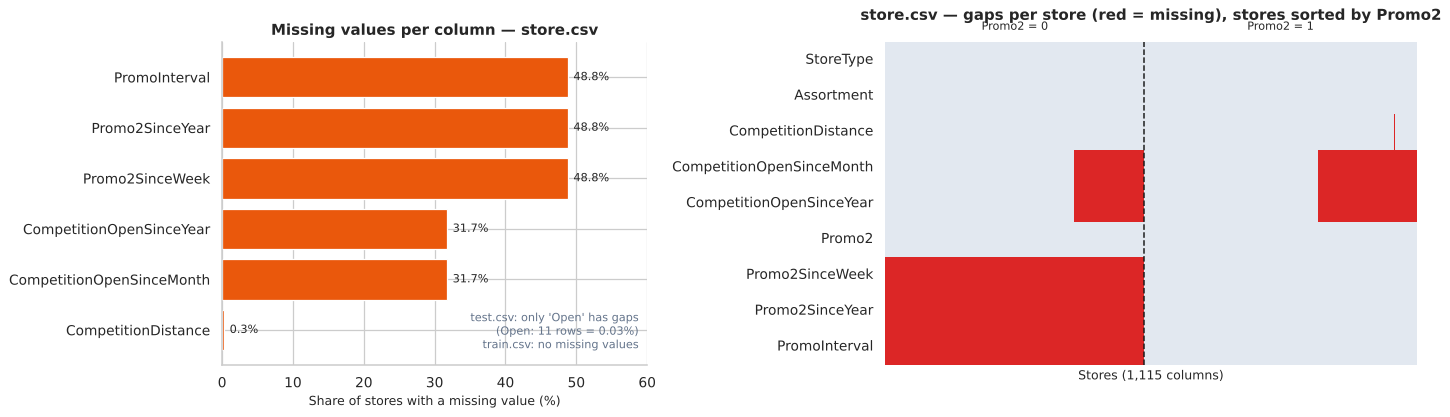

Promo2 stores with missing Promo2Since*/PromoInterval : 0
Non-Promo2 stores with missing Promo2Since*/PromoInterval: 544 of 544
Stores missing CompetitionDistance : [291, 622, 879]
... of those, also missing the opening date: 3
Stores with distance but NO opening date: 351
Test rows with missing Open → stores: [622]


In [ ]:
log.info("Section 2: missing-value analysis")
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1, 1.25]})
miss = (raw["store"].isna().mean() * 100).sort_values(); miss = miss[miss > 0]
axes[0].barh(miss.index, miss.values, color=COLORS["orange"])
for y, v in enumerate(miss.values): axes[0].text(v + 0.8, y, f"{v:.1f}%", va="center", fontsize=9)
axes[0].set_title("Missing values per column — store.csv"); axes[0].set_xlabel("Share of stores with a missing value (%)"); axes[0].set_xlim(0, 60)
test_miss = raw["test"].isna().sum(); test_miss = test_miss[test_miss > 0]
axes[0].text(0.98, 0.04, "test.csv: only 'Open' has gaps\n(" + ", ".join(f"{c}: {n} rows = {n / len(raw['test']):.2%}" for c, n in test_miss.items()) + ")\ntrain.csv: no missing values",
             transform=axes[0].transAxes, ha="right", va="bottom", fontsize=9, color=COLORS["grey"])

order_ = raw["store"].assign(k=raw["store"].CompetitionOpenSinceYear.isna()).sort_values(["Promo2", "k"]).drop(columns=["Store", "k"])
sns.heatmap(order_.isna().T, cbar=False, cmap=["#E2E8F0", COLORS["red"]], ax=axes[1], xticklabels=False)
n0 = int((raw["store"].Promo2 == 0).sum())
axes[1].axvline(n0, color="k", lw=1.2, ls="--")
axes[1].text(n0 / 2, -0.35, "Promo2 = 0", ha="center", fontsize=9); axes[1].text(n0 + (len(order_) - n0) / 2, -0.35, "Promo2 = 1", ha="center", fontsize=9)
axes[1].set_title("store.csv — gaps per store (red = missing), stores sorted by Promo2", pad=18); axes[1].set_xlabel("Stores (1,115 columns)")
plt.tight_layout(); plt.show()

s = raw["store"]
print("Promo2 stores with missing Promo2Since*/PromoInterval :", int(((s.Promo2 == 1) & s[["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().any(axis=1)).sum()))
print("Non-Promo2 stores with missing Promo2Since*/PromoInterval:", int(((s.Promo2 == 0) & s[["Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]].isna().all(axis=1)).sum()), "of", int((s.Promo2 == 0).sum()))
print("Stores missing CompetitionDistance :", s.loc[s.CompetitionDistance.isna(), "Store"].tolist())
print("... of those, also missing the opening date:", int(s.loc[s.CompetitionDistance.isna(), "CompetitionOpenSinceYear"].isna().sum()))
print("Stores with distance but NO opening date:", int((s.CompetitionDistance.notna() & s.CompetitionOpenSinceYear.isna()).sum()))
print("Test rows with missing Open → stores:", raw["test"].loc[raw["test"].Open.isna(), "Store"].unique().tolist())

**Missing-value findings and the decision for each**

| Column | Missing | Nature | Decision (and why) |
|---|---|---|---|
| `Promo2SinceWeek/Year`, `PromoInterval` | 544 stores (48.8 %) | **Structural** — exactly the 544 stores with `Promo2 = 0` (nothing to start, no interval). Not an error. | Fill week/year with `0`, interval with `"None"`; the *information* is already carried by `Promo2`. |
| `CompetitionOpenSinceMonth/Year` | 354 stores (31.8 %) | **Genuinely unknown date.** 351 of these stores *do* have a competition distance → a competitor exists but we do not know since when. | Keep `NaT`, add flag `CompetitionOpenDateKnown`; the competitor is assumed to be already open (`CompetitionActive = 1`). Not imputed with an invented date. |
| `CompetitionDistance` | 3 stores | Unknown distance (these stores also have no opening date → most likely no known competitor). | Impute the **median (2,325 m)** and keep flag `CompetitionDistanceMissing` — only 0.27 % of stores, so the choice has negligible influence; the flag lets a model discount it. |
| `Open` (test) | 11 rows (store 622) | Missing in the *test* file. | Impute from the store's own history: typical `Open` for that store on that weekday (non-holiday days) → flag `OpenImputed`. Wrongly assuming "closed" would force a forecast of 0. |

No row is deleted because of missing data.

## 3. Cleaning pipeline and outlier analysis

In [ ]:
log.info("Section 3: running the cleaning + feature pipeline (src/data/make_dataset.py)")
res = run_pipeline()                    # clean -> outliers -> features -> save to data/processed
train, test, store = res["train"], res["test"], res["store"]
report = res["report"]

cleaning = {k: v for k, v in report.items() if not isinstance(v, (dict, list))}
display(Markdown("**Cleaning report (all counts come from the pipeline)**"))
display(pd.Series(cleaning, name="value").to_frame())
print("train:", train.shape, "| test:", test.shape, "| store:", store.shape)

2026-10-30 07:00:26,248 | INFO     | src.eda | Section 3: running the cleaning + feature pipeline (src/data/make_dataset.py)


2026-10-30 07:00:26,254 | INFO     | src.data.make_dataset | === Part 1 pipeline started ===


2026-10-30 07:00:27,016 | INFO     | src.data.loader | Loaded train             from train.csv -> 1017209 rows x 9 cols


2026-10-30 07:00:27,043 | INFO     | src.data.loader | Loaded test              from test.csv -> 41088 rows x 8 cols


2026-10-30 07:00:27,049 | INFO     | src.data.loader | Loaded store             from store.csv -> 1115 rows x 10 cols


2026-10-30 07:00:27,324 | INFO     | src.data.inspection | Inspection train: {'name': 'train', 'rows': 1017209, 'columns': 9, 'full_row_duplicates': 0, 'memory_mb': np.float64(84.4), 'key_duplicates': 0}


... (20 outputs left out)

2026-10-30 07:00:33,471 | INFO     | src.data.make_dataset | === Part 1 pipeline finished: train (1017209, 50), test (41088, 46) ===


**Cleaning report (all counts come from the pipeline)**

,value
store_duplicates_removed,0.000
store_invalid_storetype,0.000
store_invalid_assortment,0.000
store_competition_distance_missing,3.000
store_competition_distance_fill_value,"2,325.000"
store_competition_open_date_unknown,354.000
store_promo2_structural_missing,544.000
store_promo2_unexpected_missing,0.000
train_invalid_dates_dropped,0.000
train_invalid_state_holiday,0.000


train: (1017209, 50) | test: (41088, 46) | store: (1115, 14)


**Cleaning decisions**

| Issue | Finding | Decision |
|---|---|---|
| Dates | all parsed; `DayOfWeek` agrees with `Date` on every row | `Date` → `datetime64`; `DayOfWeek` re-derived from the date (1 = Mon … 7 = Sun) |
| `StateHoliday` | integer `0` mixed with `a/b/c` | normalised to text `{0, a, b, c}`; invalid values would be set to `0` (none found) |
| Types | `Open`, `Promo`, `SchoolHoliday`, `Promo2` stored as 64-bit ints | down-cast to `int8` (halves memory) |
| Duplicates | none | check stays in the pipeline |
| Negative `Sales` / `Customers` | none | check stays in the pipeline |
| **Open but zero sales** | 54 rows | **kept and flagged** (`OpenZeroSales`) — unknown cause (stock-out, data error); modelling should train on `Open == 1 & Sales > 0` |
| Closed but sales > 0 | none | check stays in the pipeline |
| Closed days | 172,817 rows (17 %) with `Sales = 0` | **kept** — they are *real* information (the forecast for a closed day is exactly 0) |
| Missing data | see section 2 | structural → fill + keep information; unknown → flag, never invent |

2026-10-30 07:00:33,499 | INFO     | src.eda | Section 3b: outlier analysis


Method: MAD robust z-score, threshold 5.0, compared within ['Store', 'DayOfWeek', 'Promo'], action = 'flag'
Open-day rows analysed: 844,338 | Sales outliers: 11,094 (1.31% of open days) | Customers outliers: 11,829


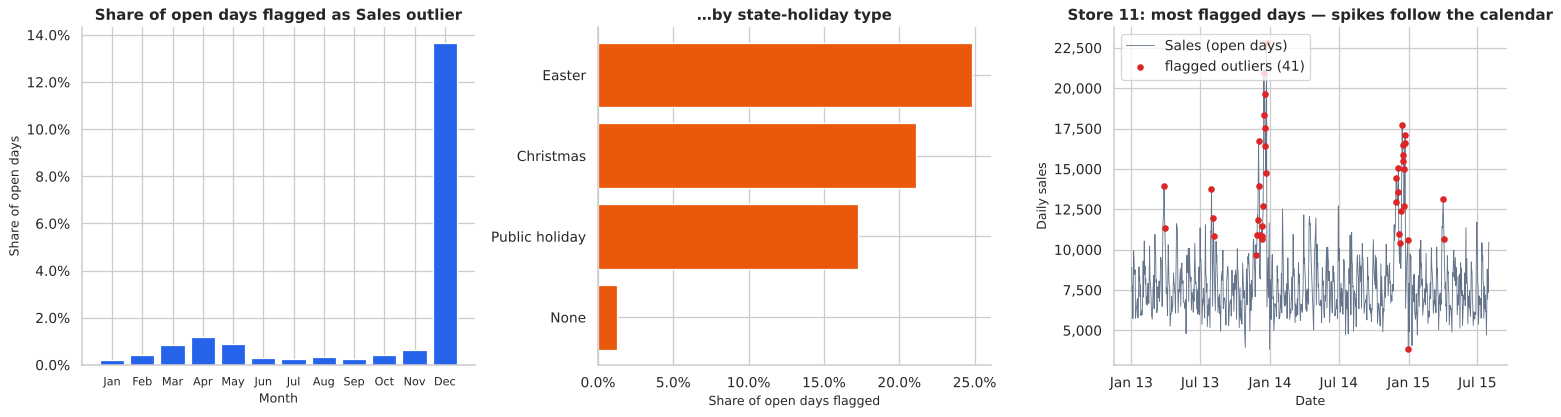


Sensitivity: mean Sales 6,956.0 → 6,937.2 after clipping; max Sales 41,551 → 38,025
Open-but-zero-sales days: 54 rows in 41 stores (first 2013-01-17, last 2015-05-15)


In [ ]:
log.info("Section 3b: outlier analysis")
oc = cfg["cleaning"]["outlier"]
print(f"Method: {oc['method'].upper()} robust z-score, threshold {oc['threshold']}, compared within {oc['group_cols']}, action = '{oc['action']}'")
open_days = train[(train.Open == 1) & (train.Sales > 0)]
print(f"Open-day rows analysed: {len(open_days):,} | Sales outliers: {int(train.SalesOutlier.sum()):,} "
      f"({train.SalesOutlier.sum() / len(open_days):.2%} of open days) | Customers outliers: {int(train.CustomersOutlier.sum()):,}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
# (1) when do outliers happen?
by_month = open_days.groupby("Month").SalesOutlier.mean()
axes[0].bar(by_month.index, by_month.values, color=COLORS["blue"])
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels([MONTH_NAMES[m] for m in range(1, 13)], fontsize=9)
percent(axes[0], decimals=1)
axes[0].set_title("Share of open days flagged as Sales outlier"); axes[0].set_xlabel("Month"); axes[0].set_ylabel("Share of open days")
# (2) by holiday status
by_h = open_days.groupby(open_days.StateHoliday.map(STATE_HOLIDAY_LABELS)).SalesOutlier.mean().sort_values()
axes[1].barh(by_h.index, by_h.values, color=COLORS["orange"]); percent(axes[1], axis="x", decimals=1)
axes[1].set_title("…by state-holiday type"); axes[1].set_xlabel("Share of open days flagged")
# (3) one store with its flagged days
sid = train.groupby("Store").SalesOutlier.sum().idxmax()
st_ts = train[(train.Store == sid) & (train.Open == 1)]
axes[2].plot(st_ts.Date, st_ts.Sales, color=COLORS["grey"], lw=0.7, label="Sales (open days)")
fl = st_ts[st_ts.SalesOutlier == 1]
axes[2].scatter(fl.Date, fl.Sales, color=COLORS["red"], s=18, zorder=3, label=f"flagged outliers ({len(fl)})")
thousands(axes[2]); axes[2].set_title(f"Store {sid}: most flagged days — spikes follow the calendar")
axes[2].xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7])); axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%b %y"))
axes[2].set_xlabel("Date"); axes[2].set_ylabel("Daily sales"); axes[2].legend(loc="upper left")
plt.tight_layout(); plt.show()

# What would the alternative handling strategies do? (demonstration on a copy)
demo = handle_outliers(open_days.copy(), "Sales", "SalesOutlier", oc["group_cols"], action="clip", threshold=oc["threshold"])
print(f"\nSensitivity: mean Sales {open_days.Sales.mean():,.1f} → {demo.SalesClipped.mean():,.1f} after clipping; "
      f"max Sales {open_days.Sales.max():,.0f} → {demo.SalesClipped.max():,.0f}")
zero = train[train.OpenZeroSales == 1]
print(f"Open-but-zero-sales days: {len(zero)} rows in {zero.Store.nunique()} stores "
      f"(first {zero.Date.min().date()}, last {zero.Date.max().date()})")

**Interpretation — outliers are mostly *real* peaks, not errors**
* Flagged days are **not random**: **13.6 %** of open December days are flagged against **0.5 %** in all other months, and 17–25 % of open holiday days against ≈ 1 % on normal days (store 11 shows the typical picture: clusters of spikes in the weeks before Christmas).
* Clipping the flagged values at ±5 MAD would change the average sales by only 0.3 % (6,956 → 6,937) but would cut the maximum from 41,551 to 38,025 — i.e. it would erase exactly the Christmas / holiday signal a forecast must reproduce.
* **Decision:** outliers are **flagged, never deleted** (`SalesOutlier`, `CustomersOutlier`); the strategy is configurable (`flag` / `clip` / `drop`) in `config.yaml`. Part 2 can compare "keep" vs "clip" with a validation set. The 54 *open-but-zero-sales* days (41 stores) are the only rows that look like genuine data errors; they are flagged (`OpenZeroSales`) and will be excluded from regressor training.
* Outlier flags are derived from the target → they are **diagnostic columns, never model inputs** (listed in `feature_manifest.json`).

## 4. Date processing and feature-engineering foundation

All features live in reusable modules (`src/features/`) so that Part 2 can import them directly. Every feature is built **only from information that is known in advance** (calendar, store master data, promo / holiday flags that are present in the test file) — never from `Sales` or `Customers` of the day being predicted.

| Module | Features |
|---|---|
| `date_features.py` | `Year, Month, Day, DayOfWeek, WeekOfYear, Quarter, DayOfYear, DaysInMonth, IsWeekend, IsMonthStart, IsMonthEnd, IsBeginOfMonth (day 1–10), IsMidOfMonth (11–20), IsEndOfMonth (21+), MonthPart` |
| `holiday_features.py` | `DaysToNextHoliday, DaysSinceLastHoliday, IsBeforeHoliday, IsAfterHoliday, DaysToChristmas` — **store-aware** calendar (see below) |
| `promo_features.py` | `Promo2Active` (Promo2 started + current month in `PromoInterval`), `Promo2WeeksRunning` |
| `competition_features.py` | `CompetitionDistanceLog, CompetitionOpenMonths, CompetitionActive` |
| `history_features.py` | store-history statistics (`StoreMeanSales`, `StoreMeanCustomers`, …) — computed **only from the past** and *not* stored in the processed files |

In [ ]:
log.info("Section 4: feature-engineering foundation")
manifest = res["manifest"]
print("Feature groups (data/processed/feature_manifest.json):")
for k in ["numeric_features", "binary_features", "categorical_features"]:
    print(f"\n{k} ({len(manifest[k])}):", ", ".join(manifest[k]))
print("\nTarget:", manifest["target"], "| auxiliary target (train only):", manifest["auxiliary_target_train_only"])
print("Never use as features:", manifest["never_use_as_features_leakage_or_diagnostic"])
display(train[["Store", "Date", "Sales", "DayOfWeek", "Year", "Month", "Day", "WeekOfYear", "IsWeekend", "MonthPart",
               "StateHoliday", "DaysToNextHoliday", "DaysSinceLastHoliday", "Promo", "Promo2Active",
               "CompetitionDistanceLog", "CompetitionOpenMonths", "CompetitionActive"]].sample(6, random_state=SEED))

2026-10-30 07:00:34,408 | INFO     | src.eda | Section 4: feature-engineering foundation


Feature groups (data/processed/feature_manifest.json):

numeric_features (16): Year, Month, Day, DayOfWeek, WeekOfYear, Quarter, DayOfYear, DaysInMonth, MonthPart, DaysToNextHoliday, DaysSinceLastHoliday, DaysToChristmas, CompetitionDistance, CompetitionDistanceLog, CompetitionOpenMonths, Promo2WeeksRunning

binary_features (16): Open, Promo, SchoolHoliday, IsWeekend, IsMonthStart, IsMonthEnd, IsBeginOfMonth, IsMidOfMonth, IsEndOfMonth, IsBeforeHoliday, IsAfterHoliday, Promo2, Promo2Active, CompetitionActive, CompetitionDistanceMissing, CompetitionOpenDateKnown

categorical_features (4): StoreType, Assortment, StateHoliday, PromoInterval

Target: Sales | auxiliary target (train only): Customers
Never use as features: ['Customers', 'OpenZeroSales', 'ClosedWithSales', 'SalesOutlier', 'CustomersOutlier', 'OpenImputed']


,Store,Date,Sales,DayOfWeek,Year,Month,Day,WeekOfYear,IsWeekend,MonthPart,StateHoliday,DaysToNextHoliday,DaysSinceLastHoliday,Promo,Promo2Active,CompetitionDistanceLog,CompetitionOpenMonths,CompetitionActive
76435,616,2015-05-24,0,7,2015,5,24,21,1,2,0,1,10,0,0,8.020,45,1
923026,592,2013-03-26,5548,2,2013,3,26,13,0,2,0,3,30,1,0,7.840,93,1
731180,526,2013-09-14,7467,6,2013,9,14,37,1,1,0,19,30,0,1,4.796,0,1
790350,601,2013-07-23,3360,2,2013,7,23,30,0,2,0,30,30,0,1,9.014,0,0
252134,953,2014-12-15,11414,1,2014,12,15,51,0,1,0,10,30,1,1,9.895,104,1
425310,166,2014-06-15,0,7,2014,6,15,24,1,1,0,4,6,0,0,4.615,2,1


In [ ]:
# Sanity checks of the engineered features (they must be logically correct, not just present)
chk = {}
chk["DayOfWeek 1..7 matches calendar"] = bool((train.DayOfWeek == train.Date.dt.dayofweek + 1).all())
chk["IsWeekend only for Sat/Sun"] = bool(set(train.loc[train.IsWeekend == 1, "DayOfWeek"]) == {6, 7})
chk["MonthPart: begin<=10 < mid<=20 < end"] = bool(train.groupby("MonthPart").Day.agg(["min", "max"]).values.tolist() == [[1, 10], [11, 20], [21, 31]])
chk["Features have no missing values"] = bool(train[manifest["numeric_features"] + manifest["binary_features"] + manifest["categorical_features"]].isna().sum().sum() == 0)
chk["Test has no leakage columns"] = not any(c in test.columns for c in manifest["never_use_as_features_leakage_or_diagnostic"] if c != "OpenImputed")
chk["Promo2Active only for Promo2 stores"] = bool(train.loc[train.Promo2Active == 1, "Promo2"].eq(1).all())
chk["Competition months >= 0"] = bool((train.CompetitionOpenMonths >= 0).all())
display(pd.Series(chk, name="passed").to_frame())

# Store-aware holidays: 2013-08-15 is a holiday for only part of the stores
local = train[train.Date == "2013-08-15"].groupby("StateHoliday").Store.nunique()
print("Stores on 2013-08-15 by StateHoliday:", local.to_dict())
s_hol = train[(train.Date == "2013-08-15") & (train.StateHoliday == "a")].Store.iloc[0]
s_no = train[(train.Date == "2013-08-15") & (train.StateHoliday == "0")].Store.iloc[0]
cols = ["Store", "Date", "StateHoliday", "DaysToNextHoliday", "DaysSinceLastHoliday", "IsBeforeHoliday", "IsAfterHoliday"]
display(train[(train.Store.isin([s_hol, s_no])) & train.Date.between("2013-08-13", "2013-08-17")][cols].sort_values(["Store", "Date"]))

,passed
DayOfWeek 1..7 matches calendar,True
IsWeekend only for Sat/Sun,True
MonthPart: begin<=10 < mid<=20 < end,True
Features have no missing values,True
Test has no leakage columns,True
Promo2Active only for Promo2 stores,True
Competition months >= 0,True


Stores on 2013-08-15 by StateHoliday: {'0': 935, 'a': 180}


,Store,Date,StateHoliday,DaysToNextHoliday,DaysSinceLastHoliday,IsBeforeHoliday,IsAfterHoliday
766335,1,2013-08-13,0,30,30,0,0
765220,1,2013-08-14,0,30,30,0,0
764105,1,2013-08-15,0,30,30,0,0
762990,1,2013-08-16,0,30,30,0,0
761875,1,2013-08-17,0,30,30,0,0
766347,13,2013-08-13,0,2,30,1,0
765232,13,2013-08-14,0,1,30,1,0
764117,13,2013-08-15,a,30,30,0,0
763002,13,2013-08-16,0,30,1,0,1
761887,13,2013-08-17,0,30,2,0,1


**Why the holiday calendar is per store.** `StateHoliday` is *regional*: on 2013-08-15 only 16 % of the stores (those in states where it is a holiday) carry `a`, while 1 January or Christmas hit every store. A single chain-wide calendar would tell a store that a holiday is "tomorrow" when it is not. The calendar therefore = national holidays (≥ 95 % of stores flagged) + each store's own flagged dates. It is built from the `StateHoliday` column of train **and** test (a public calendar known in advance → not leakage).

**Known limitation.** A holiday beyond the last supplied date cannot be seen, so distances are capped at 30 days and dates near the end of the data (the whole test period) mostly sit at the cap. Part 2 can refine this with an external holiday list if desired.

In [ ]:
# Leakage-safe use of Customers / past Sales: statistics are computed ONLY from days before a cutoff
# and applied to days on/after the cutoff -> exactly the situation of a real 6-week forecast.
cutoff = train.Date.max() - pd.Timedelta(days=41)            # last 42 days = 6-week validation window
stats_hist = compute_store_history_stats(train, cutoff)
valid = train[(train.Date >= cutoff) & (train.Open == 1) & (train.Sales > 0)]
valid = add_store_history_features(valid, stats_hist, cutoff)
print(f"History window: {train.Date.min().date()} → {(cutoff - pd.Timedelta(days=1)).date()} | validation window: {cutoff.date()} → {train.Date.max().date()} ({valid.Date.nunique()} days)")
print("Correlation of the pre-cutoff StoreMeanSales with validation Sales      :", round(valid[["StoreMeanSales", "Sales"]].corr().iloc[0, 1], 3))
print("Correlation of the pre-cutoff StoreMeanCustomers with validation Sales  :", round(valid[["StoreMeanCustomers", "Sales"]].corr().iloc[0, 1], 3))
_ = add_store_history_features(train[train.Date < cutoff].head(1000), stats_hist, cutoff)   # shows the leakage warning in the log

2026-10-30 07:00:34,853 | INFO     | src.features.history_features | Computed store history stats for 1115 stores using data before 2015-06-20


History window: 2013-01-01 → 2015-06-19 | validation window: 2015-06-20 → 2015-07-31 (42 days)
Correlation of the pre-cutoff StoreMeanSales with validation Sales      : 0.774
Correlation of the pre-cutoff StoreMeanCustomers with validation Sales  : 0.639
2026-10-30 07:00:35,007 | WARNING  | src.features.history_features | 1000 rows are before the cutoff 2015-06-20 -> statistics are in-sample for them (possible leakage)


Store-level history is a very strong, **legitimate** predictor for the future (it only uses the past) — but it must be recomputed for every validation split. The log line above shows the safeguard: applying the statistics to rows *before* the cutoff triggers a leakage warning.

## 5. Univariate, bivariate and multivariate analysis

2026-10-30 07:00:35,022 | INFO     | src.eda | Section 5: univariate / bivariate analysis


Open days with sales: 844,338 of 1,017,209 rows (83.0%)


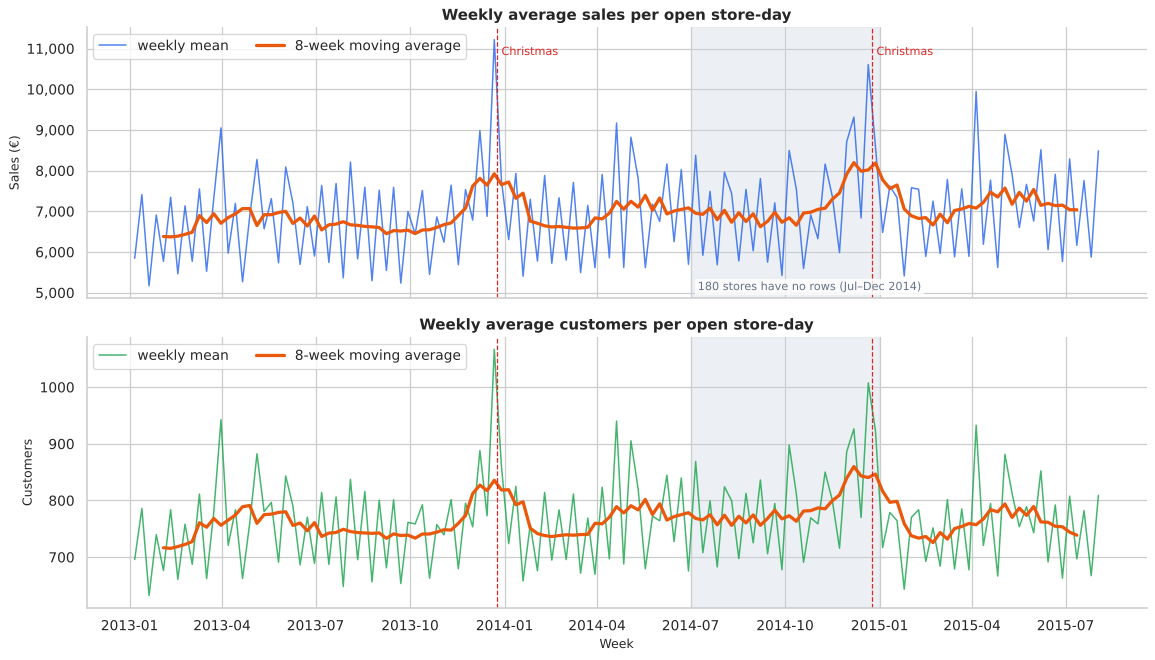

2026-10-30 07:00:36,422 | INFO     | src.visualization.plotting | Saved figure 01_time_series_overview.png


PosixPath('/home/claude/project_6/reports/figures/01_time_series_overview.png')

In [ ]:
log.info("Section 5: univariate / bivariate analysis")
op = train[(train.Open == 1) & (train.Sales > 0)].copy()          # open days with sales
op["SalesPerCustomer"] = op.Sales / op.Customers
store_lvl = (op.groupby("Store").agg(MeanSales=("Sales", "mean"), MeanCustomers=("Customers", "mean"),
                                     SalesPerCustomer=("SalesPerCustomer", "mean"), OpenDays=("Sales", "size"))
             .join(store.set_index("Store")))
print(f"Open days with sales: {len(op):,} of {len(train):,} rows ({len(op) / len(train):.1%})")

# --- time-series overview -------------------------------------------------
wk = op.set_index("Date").resample("W").agg({"Sales": "mean", "Customers": "mean"})
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
axes[0].plot(wk.index, wk.Sales, color=COLORS["blue"], lw=1.2, alpha=.8, label="weekly mean")
axes[0].plot(wk.index, wk.Sales.rolling(8, center=True).mean(), color=COLORS["orange"], lw=2.6, label="8-week moving average")
axes[1].plot(wk.index, wk.Customers, color=COLORS["green"], lw=1.2, alpha=.8, label="weekly mean")
axes[1].plot(wk.index, wk.Customers.rolling(8, center=True).mean(), color=COLORS["orange"], lw=2.6, label="8-week moving average")
for ax in axes:
    for y in [2013, 2014]:
        ax.axvline(pd.Timestamp(f"{y}-12-25"), color=COLORS["red"], ls="--", lw=1)
    ax.axvspan(pd.Timestamp("2014-07-01"), pd.Timestamp("2014-12-31"), color=COLORS["light"], alpha=0.35)
for y in [2013, 2014]:
    axes[0].text(pd.Timestamp(f"{y}-12-25") + pd.Timedelta(days=4), wk.Sales.max() * 0.985, "Christmas", color=COLORS["red"], fontsize=9, va="top")
axes[0].text(pd.Timestamp("2014-07-08"), 0.03, "180 stores have no rows (Jul–Dec 2014)", transform=axes[0].get_xaxis_transform(), fontsize=9, color=COLORS["grey"],
             bbox=dict(facecolor="white", edgecolor="none", alpha=.8, pad=2))
axes[0].set_title("Weekly average sales per open store-day"); axes[0].set_ylabel("Sales (€)"); thousands(axes[0]); axes[0].legend(loc="upper left", ncol=2)
axes[1].set_title("Weekly average customers per open store-day"); axes[1].set_ylabel("Customers"); axes[1].set_xlabel("Week"); axes[1].legend(loc="upper left", ncol=2)
plt.tight_layout(); fig_ts = fig; plt.show()
save_figure(fig_ts, "01_time_series_overview", cfg)

**Interpretation**
* The raw weekly mean zig-zags because **promotions alternate week by week** for the whole chain (promo weeks in 72 of 135 weeks; back-to-back promo weeks occurred only 11 times). The orange 8-week average removes this and shows a **slow upward trend**: mean sales per open day in Jan–Jun grew from 6,663 (2013) to 6,876 (2014) to 7,098 (2015), about **+3 % per year**.
* **Christmas** is the dominant seasonal peak (weekly average ≈ 11,200 sales and ≈ 1,070 customers per open store-day in 2013); **Easter** (Mar/Apr) is a smaller peak.
* **Data gap:** from July to December 2014, 180 stores have *no rows at all* (grey band). This is missing data, **not** `Open = 0`; it slightly changes the store mix of the weekly average and must be handled in the time-series part (Part 2 LSTM) — gaps must not be read as zero sales.
* Customers and sales move together almost one-to-one over time (see Q4).

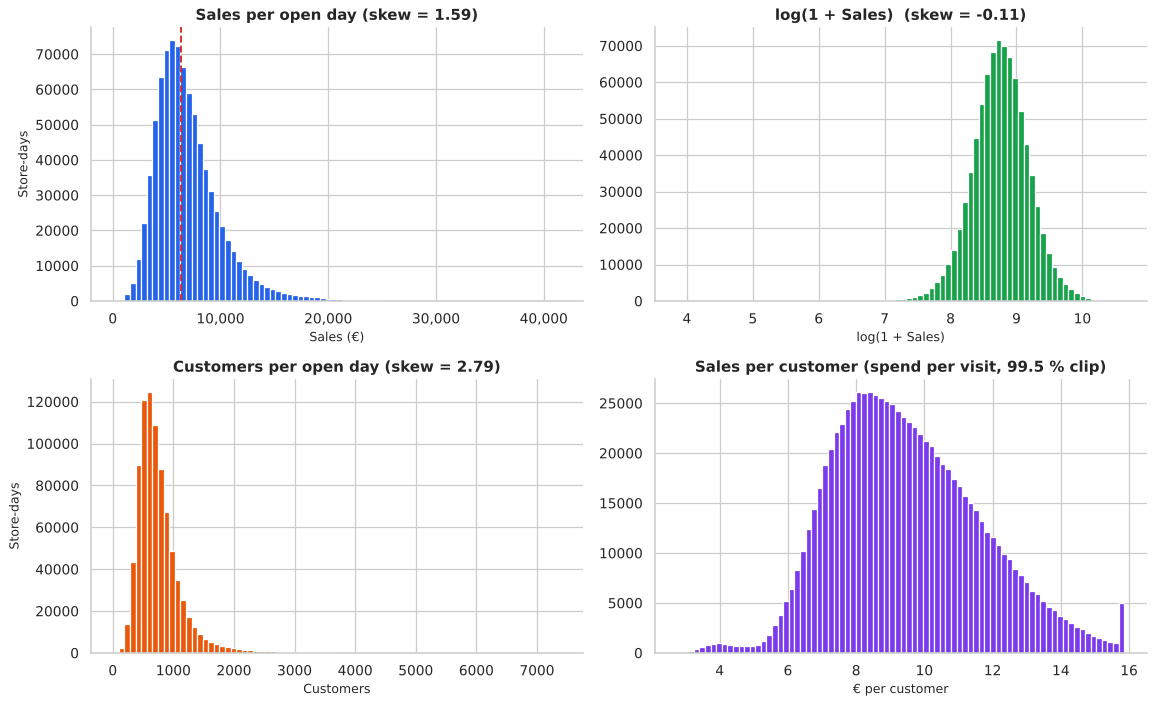

,count,mean,std,min,1%,25%,50%,75%,99%,max
Sales,"844,338.000","6,955.959","3,103.816",46.000,"2,188.000","4,859.000","6,369.000","8,360.000","17,789.000","41,551.000"
Customers,"844,338.000",762.777,401.194,8.000,251.000,519.000,676.000,893.000,"2,415.000","7,388.000"
SalesPerCustomer,"844,338.000",9.494,2.197,2.749,5.064,7.896,9.250,10.900,15.194,64.958


In [ ]:
# --- univariate: target and customers ---------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].hist(op.Sales, bins=80, color=COLORS["blue"]); axes[0, 0].axvline(op.Sales.median(), color=COLORS["red"], ls="--")
axes[0, 0].set_title(f"Sales per open day (skew = {op.Sales.skew():.2f})"); axes[0, 0].set_xlabel("Sales (€)"); axes[0, 0].set_ylabel("Store-days"); thousands(axes[0, 0], "x")
axes[0, 1].hist(np.log1p(op.Sales), bins=80, color=COLORS["green"])
axes[0, 1].set_title(f"log(1 + Sales)  (skew = {np.log1p(op.Sales).skew():.2f})"); axes[0, 1].set_xlabel("log(1 + Sales)")
axes[1, 0].hist(op.Customers, bins=80, color=COLORS["orange"]); axes[1, 0].set_title(f"Customers per open day (skew = {op.Customers.skew():.2f})")
axes[1, 0].set_xlabel("Customers"); axes[1, 0].set_ylabel("Store-days")
axes[1, 1].hist(op.SalesPerCustomer.clip(upper=op.SalesPerCustomer.quantile(0.995)), bins=80, color=COLORS["purple"])
axes[1, 1].set_title("Sales per customer (spend per visit, 99.5 % clip)"); axes[1, 1].set_xlabel("€ per customer")
plt.tight_layout(); plt.show()
display(op[["Sales", "Customers", "SalesPerCustomer"]].describe(percentiles=[.01, .25, .5, .75, .99]).T)

**Interpretation**
* `Sales` on open days is **right-skewed** (skew 1.59; median 6,369 vs mean 6,956; 99th percentile 17,789; maximum 41,551). After `log(1 + Sales)` the distribution is almost symmetric (skew −0.11) → a **log-transformed target** (or a relative-error metric such as RMSPE) is a natural choice for modelling.
* `Customers` is even more skewed (skew 2.79) — a few very large stores (StoreType b) create the long tail.
* Spend per customer is centred around **€9.3–9.5** (IQR 7.9–10.9); values up to ≈ €65 are rare and come from days with unusually few customers.
* The 17 % of rows with `Open = 0` (Sales = 0) are excluded from these plots; they are a separate, perfectly predictable group (forecast = 0).

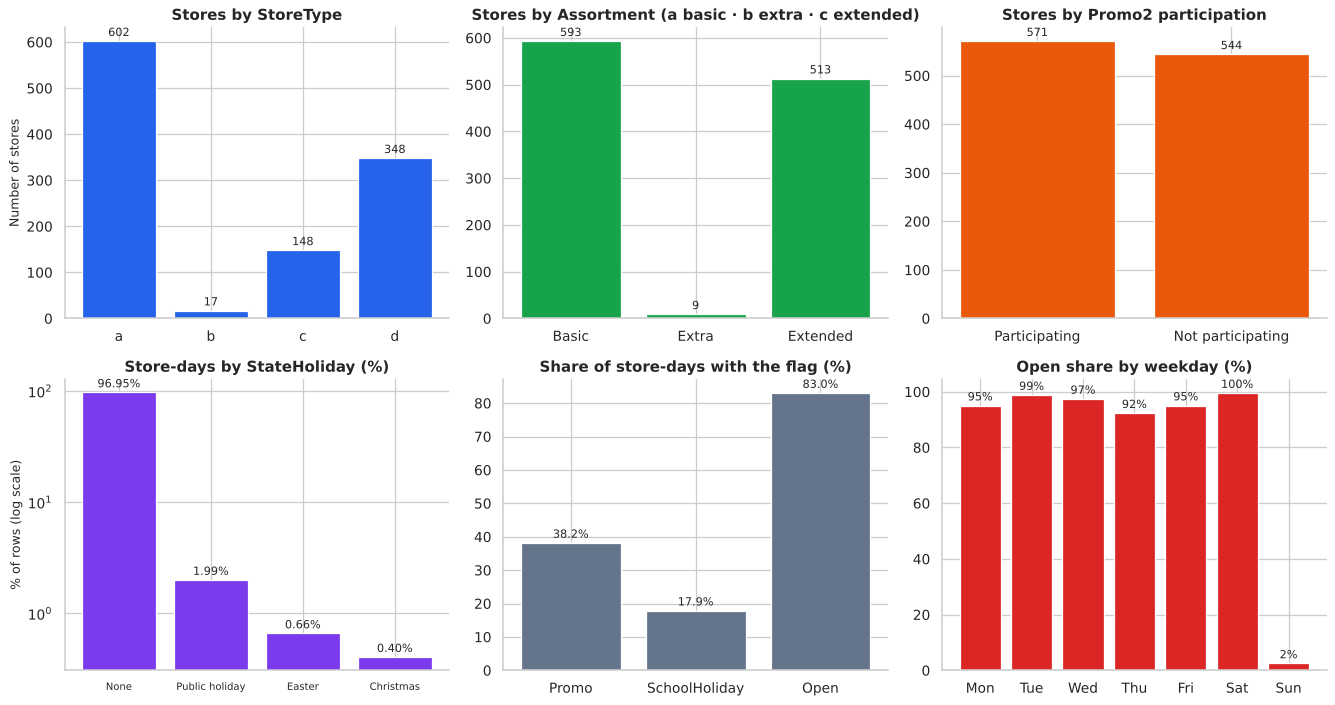

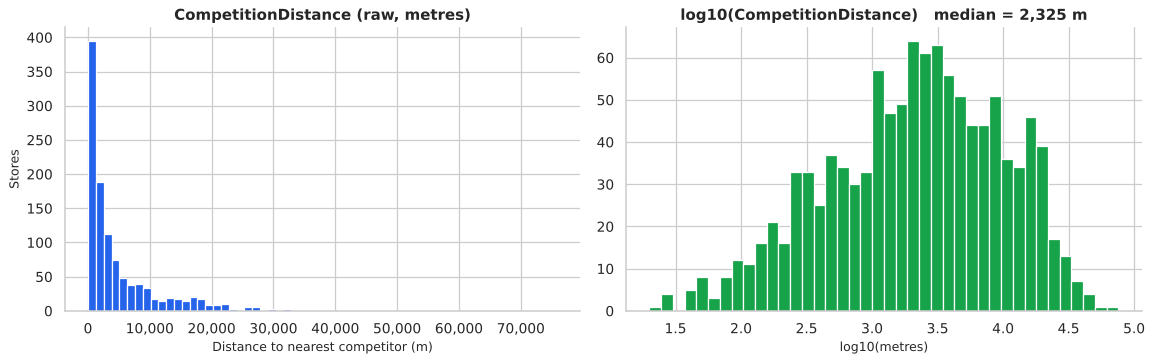

{'count': 1115.0, 'mean': 5397.0, 'std': 7655.0, 'min': 20.0, '10%': 250.0, '25%': 720.0, '50%': 2325.0, '75%': 6875.0, '90%': 15616.0, '99%': 35108.0, 'max': 75860.0}


In [ ]:
# --- univariate: categorical / binary features ---------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
stores_one = store.copy()
def bar(ax, s, title, color, fmt="{:,.0f}"):
    ax.bar(s.index.astype(str), s.values, color=color); label_bars(ax, fmt); ax.set_title(title)
bar(axes[0, 0], stores_one.StoreType.value_counts().sort_index(), "Stores by StoreType", COLORS["blue"]); axes[0, 0].set_ylabel("Number of stores")
a_cnt = stores_one.Assortment.map(ASSORTMENT_LABELS).value_counts().reindex(["Basic", "Extra", "Extended"])
bar(axes[0, 1], a_cnt, "Stores by Assortment (a basic · b extra · c extended)", COLORS["green"])
p2 = stores_one.Promo2.map(PROMO2_LABELS).value_counts()
bar(axes[0, 2], p2, "Stores by Promo2 participation", COLORS["orange"])
sh = train.StateHoliday.map(STATE_HOLIDAY_LABELS).value_counts(normalize=True).reindex(list(STATE_HOLIDAY_LABELS.values()))
bar(axes[1, 0], sh * 100, "Store-days by StateHoliday (%)", COLORS["purple"], "{:.2f}%")
axes[1, 0].set_yscale("log"); axes[1, 0].set_ylabel("% of rows (log scale)"); axes[1, 0].tick_params(axis="x", labelsize=8)
bar(axes[1, 1], pd.Series({"Promo": train.Promo.mean() * 100, "SchoolHoliday": train.SchoolHoliday.mean() * 100,
                           "Open": train.Open.mean() * 100}), "Share of store-days with the flag (%)", COLORS["grey"], "{:.1f}%")
bar(axes[1, 2], train.groupby("DayOfWeek").Open.mean().rename(DAY_NAMES) * 100, "Open share by weekday (%)", COLORS["red"], "{:.0f}%")
for ax in axes.ravel(): ax.set_xlabel("")
plt.tight_layout(); plt.show()

# competition distance: heavy right tail -> log scale
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(store.CompetitionDistance, bins=60, color=COLORS["blue"]); axes[0].set_title("CompetitionDistance (raw, metres)")
axes[0].set_xlabel("Distance to nearest competitor (m)"); axes[0].set_ylabel("Stores"); thousands(axes[0], "x")
axes[1].hist(np.log10(store.CompetitionDistance), bins=40, color=COLORS["green"])
axes[1].set_title(f"log10(CompetitionDistance)   median = {store.CompetitionDistance.median():,.0f} m"); axes[1].set_xlabel("log10(metres)")
plt.tight_layout(); plt.show()
print(store.CompetitionDistance.describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(0).to_dict())

**Interpretation**
* **Store base:** StoreType `a` (602 stores) and `d` (348) dominate, `c` has 148 and `b` only **17**. Assortment: basic (593) and extended (513) are common, **extra only 9 stores** — conclusions about StoreType `b` and extra assortment rest on very small samples. Promo2 splits the chain almost 50/50 (571 vs 544).
* **State holidays are rare** (3.1 % of store-days: public 1.99 %, Easter 0.66 %, Christmas 0.40 %) but, as shown later, have a very strong effect — rare + influential features need explicit handling.
* Stores are open on **83 %** of the store-days; almost all closures are **Sundays** (only 2 % of stores open) and state holidays. Competition distance is **heavily right-skewed** (median 2,325 m; 10 % of stores have a competitor closer than 250 m, 10 % farther than 15.6 km; maximum 75.9 km) → use a log scale / log feature.

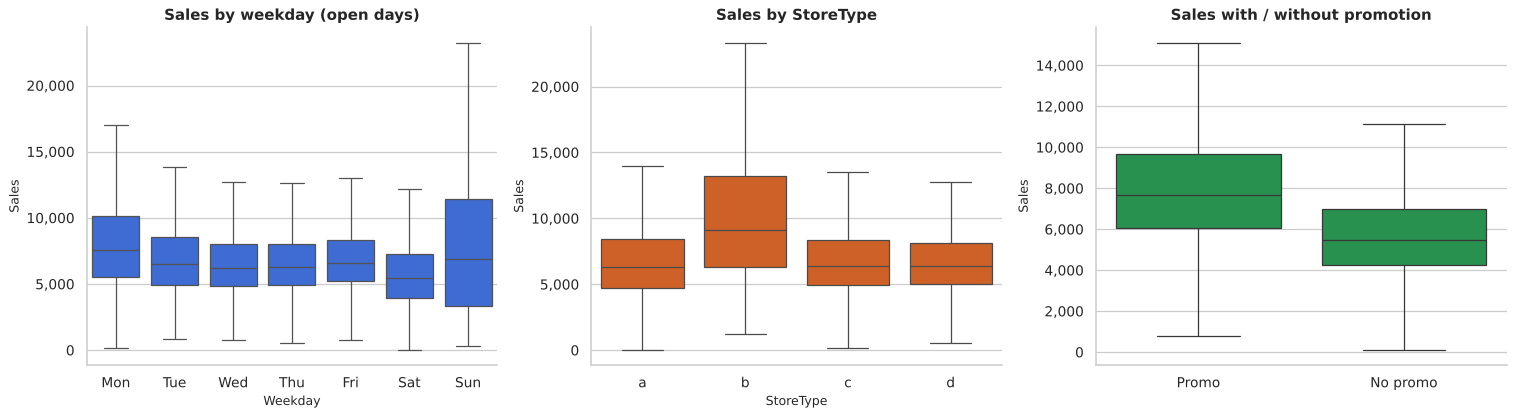

In [ ]:
# --- bivariate: target against the main categorical drivers ---------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
order = [1, 2, 3, 4, 5, 6, 7]
sns.boxplot(data=op, x="DayOfWeek", y="Sales", order=order, showfliers=False, color=COLORS["blue"], ax=axes[0])
axes[0].set_xticks(range(7)); axes[0].set_xticklabels([DAY_NAMES[d] for d in order]); axes[0].set_title("Sales by weekday (open days)"); axes[0].set_xlabel("Weekday"); thousands(axes[0])
sns.boxplot(data=op, x="StoreType", y="Sales", order=list("abcd"), showfliers=False, color=COLORS["orange"], ax=axes[1])
axes[1].set_title("Sales by StoreType"); axes[1].set_xlabel("StoreType"); thousands(axes[1])
sns.boxplot(data=op.assign(Promo=op.Promo.map({0: "No promo", 1: "Promo"})), x="Promo", y="Sales", showfliers=False, color=COLORS["green"], ax=axes[2])
axes[2].set_title("Sales with / without promotion"); axes[2].set_xlabel(""); thousands(axes[2])
plt.tight_layout(); plt.show()

**Interpretation**
* **Weekday:** Monday (8,216) is the strongest regular day, Saturday (5,875) the weakest; Tuesday–Friday sit at 6,700–7,100. Sunday (8,225) is high only because the 33 stores that open on Sundays are large stores (Q8).
* **StoreType:** type `b` stores are clearly the biggest (mean 10,233 vs 6,800–6,900 for `a`, `c`, `d`); the other three types differ only slightly in sales.
* **Promotion:** the promo box sits far above the no-promo box (on weekdays: **8,229 vs 5,930, +39 %**), — the single most important controllable driver.
* The three drivers are not independent (promo runs Mon–Fri only, StoreType b is special) → the interaction analysis below.

### 5.3 Correlations and interactions

2026-10-30 07:00:41,783 | INFO     | src.eda | Section 5: correlation analysis


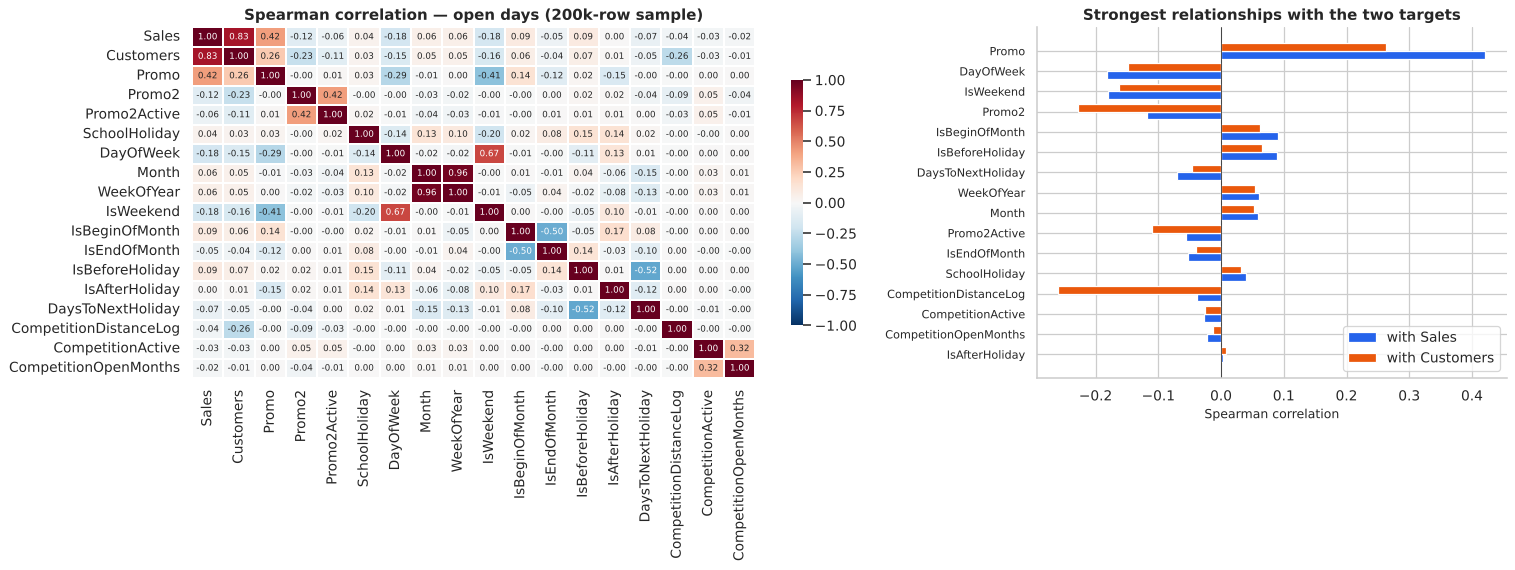

**Store-level Spearman correlations (1,115 stores)**

,MeanSales,MeanCustomers,SalesPerCustomer,Promo2,LogCompDist
MeanSales,1.000,0.800,0.070,-0.150,-0.030
MeanCustomers,0.800,1.000,-0.500,-0.270,-0.280
SalesPerCustomer,0.070,-0.500,1.000,0.240,0.480
Promo2,-0.150,-0.270,0.240,1.000,-0.100
LogCompDist,-0.030,-0.280,0.480,-0.100,1.000


In [ ]:
log.info("Section 5: correlation analysis")
corr_cols = ["Sales", "Customers", "Promo", "Promo2", "Promo2Active", "SchoolHoliday", "DayOfWeek", "Month", "WeekOfYear",
             "IsWeekend", "IsBeginOfMonth", "IsEndOfMonth", "IsBeforeHoliday", "IsAfterHoliday",
             "DaysToNextHoliday", "CompetitionDistanceLog", "CompetitionActive", "CompetitionOpenMonths"]
smp = op.sample(200_000, random_state=SEED)
cm = smp[corr_cols].corr(method="spearman")           # Spearman: robust to skew and to binary flags

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(cm, cmap="RdBu_r", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=.3, ax=axes[0], cbar_kws={"shrink": .7})
axes[0].set_title("Spearman correlation — open days (200k-row sample)")
both = cm[["Sales", "Customers"]].drop(["Sales", "Customers"])
both = both.reindex(both.Sales.abs().sort_values().index)
y = np.arange(len(both)); h = 0.38
axes[1].barh(y - h / 2, both.Sales, h, color=COLORS["blue"], label="with Sales")
axes[1].barh(y + h / 2, both.Customers, h, color=COLORS["orange"], label="with Customers")
axes[1].set_yticks(y); axes[1].set_yticklabels(both.index, fontsize=9); axes[1].axvline(0, color="k", lw=.6)
axes[1].set_title("Strongest relationships with the two targets"); axes[1].set_xlabel("Spearman correlation"); axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

# Correlations at STORE level (what separates stores, not days)
sl = store_lvl.copy()
sl["Promo2"] = sl.Promo2.astype(int); sl["LogCompDist"] = np.log1p(sl.CompetitionDistance)
sc = sl[["MeanSales", "MeanCustomers", "SalesPerCustomer", "Promo2", "LogCompDist"]].corr(method="spearman").round(2)
display(Markdown("**Store-level Spearman correlations (1,115 stores)**")); display(sc)

**Interpretation (Spearman, open days)**
* **Sales ↔ Customers is by far the strongest relationship (ρ = 0.83)**, followed by **Promo (0.42)**. Everything else is weak: weekend flag −0.17, beginning of month +0.09, day before a holiday +0.09, Promo2 −0.12, log competition distance −0.04.
* Customers behave differently: correlation with Promo2 −0.23 and with log competition distance **−0.26** — stores with a nearby competitor see more visitors (busy locations). The *store-level* table shows the mirror image: stores with many customers have **small baskets** (customers vs spend per customer ρ = −0.50), and spend per customer rises with competition distance (+0.48), while average **sales** are almost unrelated to distance (−0.03).
* Weak *linear/rank* correlations do not mean "unimportant": the calendar effects (holidays, Christmas, month part) act on specific days and in interaction with weekday, store type and promo — tree-based models will capture this better than a correlation matrix suggests.
* **Leakage warning:** `Customers` correlates 0.83 with `Sales` but is not known for future days → it cannot be a feature; it is a candidate for a *second target* (the web app has to show predicted customers).

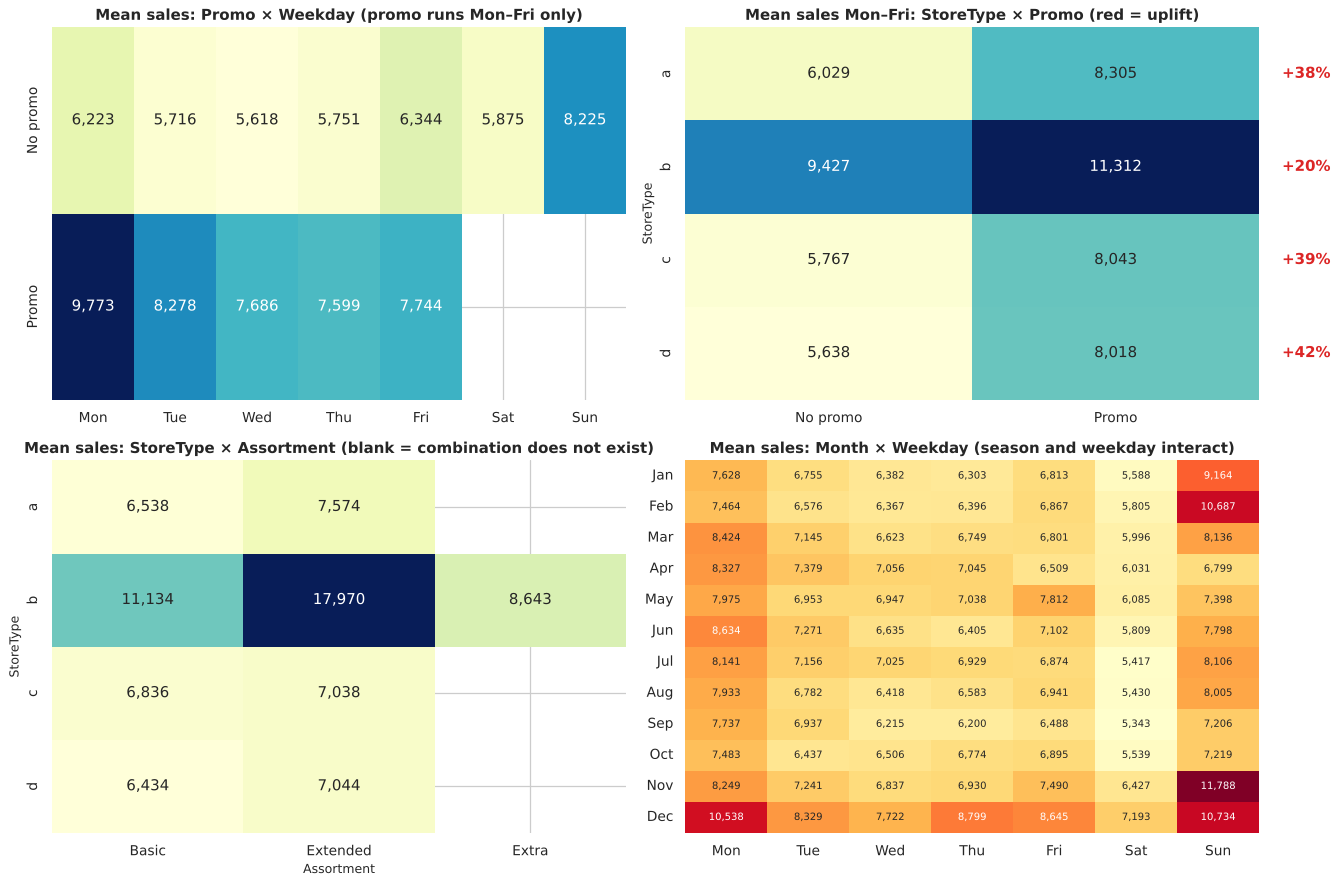

In [ ]:
# Interactions: the effect of one factor depends on another
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
t1 = op.groupby(["Promo", "DayOfWeek"]).Sales.mean().unstack()
t1.index = ["No promo", "Promo"]; t1.columns = [DAY_NAMES[c] for c in t1.columns]
sns.heatmap(t1, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0, 0], cbar=False)
axes[0, 0].set_title("Mean sales: Promo × Weekday (promo runs Mon–Fri only)"); axes[0, 0].set_ylabel("")

t2 = op[op.DayOfWeek <= 5].groupby(["StoreType", "Promo"]).Sales.mean().unstack(); t2.columns = ["No promo", "Promo"]
t2["Promo uplift"] = t2["Promo"] / t2["No promo"] - 1
sns.heatmap(t2[["No promo", "Promo"]], annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[0, 1], cbar=False)
for i, v in enumerate(t2["Promo uplift"]): axes[0, 1].text(2.08, i + .5, f"+{v:.0%}", va="center", color=COLORS["red"], fontweight="bold")
axes[0, 1].set_title("Mean sales Mon–Fri: StoreType × Promo (red = uplift)"); axes[0, 1].set_ylabel("StoreType")

t3 = op.assign(Assortment=op.Assortment.map(ASSORTMENT_LABELS)).groupby(["StoreType", "Assortment"]).Sales.mean().unstack()
sns.heatmap(t3, annot=True, fmt=",.0f", cmap="YlGnBu", ax=axes[1, 0], cbar=False)
axes[1, 0].set_title("Mean sales: StoreType × Assortment (blank = combination does not exist)"); axes[1, 0].set_ylabel("StoreType")

t4 = op.groupby(["Month", "DayOfWeek"]).Sales.mean().unstack(); t4.index = [MONTH_NAMES[m] for m in t4.index]; t4.columns = [DAY_NAMES[c] for c in t4.columns]
sns.heatmap(t4, annot=True, fmt=",.0f", cmap="YlOrRd", ax=axes[1, 1], cbar=False, annot_kws={"size": 8})
axes[1, 1].set_title("Mean sales: Month × Weekday (season and weekday interact)"); axes[1, 1].set_ylabel("")
plt.tight_layout(); plt.show()

**Interpretation**
* **Promo × Weekday:** the promotion uplift shrinks over the week — **Mon +57 %, Tue +45 %, Wed +37 %, Thu +32 %, Fri +22 %**. A Monday promotion is worth the most, a Friday promotion the least. (Promotions never run on Saturday/Sunday.)
* **StoreType × Promo (Mon–Fri):** uplift is +38 % (`a`), +40 % (`c`), +42 % (`d`) but only **+20 % for `b`** — these large stores are already busy, so promotions add less in relative terms.
* **StoreType × Assortment:** type `b` is the highest-selling type in every assortment; inside type `a` and `d`, extended stores sell more than basic ones (Q9). Empty cells show combinations that do not exist (no extra assortment outside `b`); the `b` × extended cell (17,970) is a **single store**, so it is not a reliable average.
* **Month × Weekday:** the weekday shape (Monday high, Saturday low) is stable in every month, while the *level* shifts with the season — December lifts every weekday (Saturday 7,193 in December vs 5,343 in September). The Sunday column is noisy (only 33 stores).
* Modelling consequence: promo, weekday, month and StoreType must be allowed to **interact** (trees do this automatically; a linear model would need explicit interaction terms).

### 5.4 Promotion deep-dive — `Promo2`, participation and `PromoInterval`
`Promo2` is the *continuing* promotion: a store joins at `Promo2Since[Year/Week]` and the promotion **restarts** in the months of its `PromoInterval` (`Jan,Apr,Jul,Oct` · `Feb,May,Aug,Nov` · `Mar,Jun,Sept,Dec`). Two questions: (1) do Promo2 stores differ from the others, and (2) does a restart month lift sales?
To compare months fairly we use the **sales index** (a day's sales ÷ the same store's normal sales on that weekday). For (2) we compare, **within the same calendar month**, Promo2 stores whose interval contains that month with Promo2 stores whose interval does not — so seasonality cancels out.

2026-10-30 07:00:44,840 | INFO     | src.eda | Section 5.4: Promo2 and PromoInterval


**Store averages by Promo2 participation** (571 participating vs 544 non-participating stores)

,MeanSales,MeanCustomers,SalesPerCustomer
Promo2,,,
Not participating,"7,337.667",836.846,9.055
Participating,"6,550.655",676.176,10.017


Mann-Whitney on store mean sales: p = 1.0e-06
Restart month vs other Promo2 stores in the SAME month: sales -0.8% (positive in 1 of 12 months), customers -0.6%


Share of Promo2 stores whose interval contains the month: 19%–59%


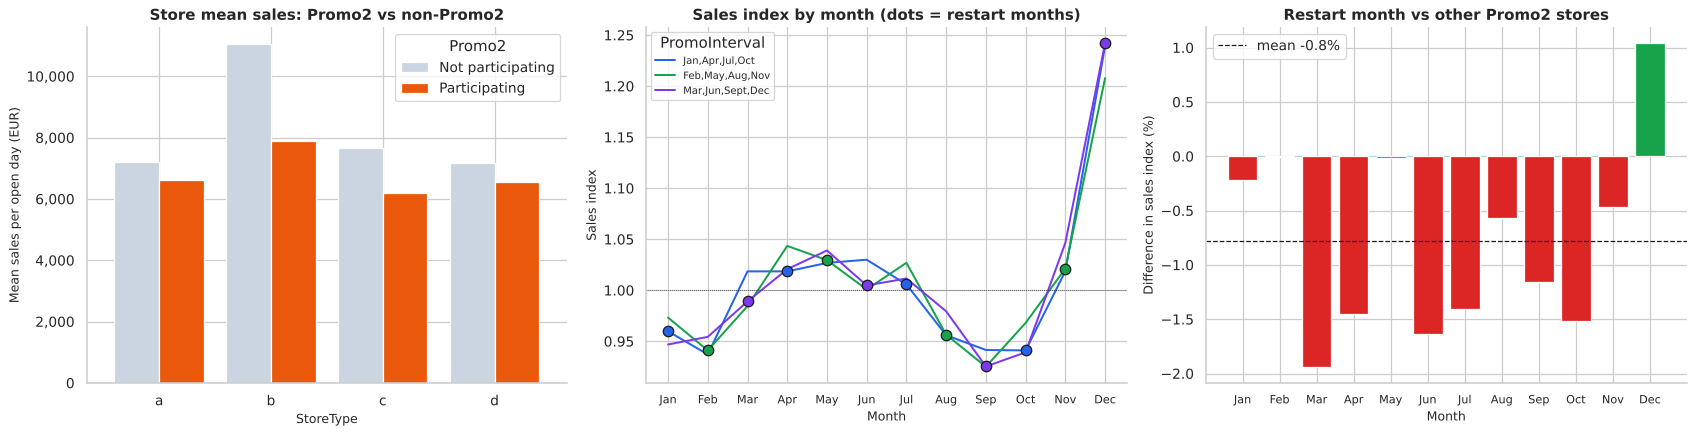

In [ ]:
log.info("Section 5.4: Promo2 and PromoInterval")
base_n = train[(train.Open == 1) & (train.Sales > 0) & (train.StateHoliday == "0")].groupby(["Store", "DayOfWeek"]).Sales.mean().rename("BaseSales").reset_index()
op_si = op.merge(base_n, on=["Store", "DayOfWeek"]); op_si["SalesIndex"] = op_si.Sales / op_si.BaseSales

sl = store_lvl.copy(); sl["Promo2"] = sl.Promo2.map(PROMO2_LABELS)
part = sl.groupby("Promo2")[["MeanSales", "MeanCustomers", "SalesPerCustomer"]].mean()
display(Markdown("**Store averages by Promo2 participation** (571 participating vs 544 non-participating stores)")); display(part)
print(f"Mann-Whitney on store mean sales: p = {stats.mannwhitneyu(sl[sl.Promo2 == 'Participating'].MeanSales, sl[sl.Promo2 != 'Participating'].MeanSales).pvalue:.1e}")

p2 = op_si[(op_si.Promo2 == 1) & (op_si.Date >= op_si.Promo2StartDate) & (op_si.DayOfWeek <= 5)]        # Promo2 stores AFTER they joined, Mon-Fri
m = p2.groupby(["Month", "Promo2Active"]).SalesIndex.mean().unstack(); did = m[1] / m[0] - 1
cm_ = p2.assign(c=p2.Customers / p2.groupby("Store").Customers.transform("mean")).groupby(["Month", "Promo2Active"]).c.mean().unstack(); did_c = cm_[1] / cm_[0] - 1
print(f"Restart month vs other Promo2 stores in the SAME month: sales {did.mean():+.1%} (positive in {int((did > 0).sum())} of 12 months), customers {did_c.mean():+.1%}")
print(f"Share of Promo2 stores whose interval contains the month: {p2.groupby('Month').Promo2Active.mean().min():.0%}–{p2.groupby('Month').Promo2Active.mean().max():.0%}")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
g = op.assign(Promo2=op.Promo2.map(PROMO2_LABELS)).groupby(["Store", "StoreType", "Promo2"]).Sales.mean().reset_index().groupby(["StoreType", "Promo2"]).Sales.mean().unstack()
g[["Not participating", "Participating"]].plot.bar(ax=axes[0], rot=0, color=[COLORS["light"], COLORS["orange"]], width=.8); thousands(axes[0])
axes[0].set_title("Store mean sales: Promo2 vs non-Promo2"); axes[0].set_xlabel("StoreType"); axes[0].set_ylabel("Mean sales per open day (EUR)"); axes[0].legend(title="Promo2")
colors3 = {"Jan,Apr,Jul,Oct": COLORS["blue"], "Feb,May,Aug,Nov": COLORS["green"], "Mar,Jun,Sept,Dec": COLORS["purple"]}
prof = p2.groupby(["PromoInterval", "Month"]).SalesIndex.mean().unstack(0)
for iv, c in colors3.items():
    axes[1].plot(prof.index, prof[iv], color=c, lw=1.6, label=iv)
    rm = [mo for mo in range(1, 13) if MONTH_NAMES[mo] in iv]
    axes[1].scatter(rm, prof.loc[rm, iv], color=c, s=70, zorder=3, edgecolor="k")
axes[1].set_xticks(range(1, 13)); axes[1].set_xticklabels([MONTH_NAMES[i] for i in range(1, 13)], fontsize=9); axes[1].axhline(1, color="k", lw=.6, ls=":")
axes[1].set_title("Sales index by month (dots = restart months)"); axes[1].set_xlabel("Month"); axes[1].set_ylabel("Sales index"); axes[1].legend(title="PromoInterval", fontsize=8)
axes[2].bar(range(1, 13), did.values * 100, color=np.where(did.values >= 0, COLORS["green"], COLORS["red"])); axes[2].axhline(did.mean() * 100, color="k", ls="--", lw=1, label=f"mean {did.mean():+.1%}")
axes[2].set_xticks(range(1, 13)); axes[2].set_xticklabels([MONTH_NAMES[i] for i in range(1, 13)], fontsize=9)
axes[2].set_title("Restart month vs other Promo2 stores"); axes[2].set_xlabel("Month"); axes[2].set_ylabel("Difference in sales index (%)"); axes[2].legend()
plt.tight_layout(); plt.show()

**Interpretation — Promo2 participants are different stores, and restart months show no visible lift**
* **Participation:** the 571 Promo2 stores are **smaller** — mean sales 6,551 vs 7,338 per open day (−10.7 %, p ≈ 10⁻⁶), fewer customers (676 vs 837) but a higher spend per customer (€10.1 vs €9.1). The gap exists inside every StoreType (`a` 6,614 vs 7,189 · `c` 6,185 vs 7,671 · `d` 6,563 vs 7,184 · `b` 7,875 vs 11,045), so it is not just a store-type mix effect. This is **selection, not proof of a negative effect**: weaker stores may simply have been the ones that joined.
* **Restart months:** the three interval groups have almost identical monthly profiles (middle panel) — the dots (restart months) do not sit above the lines. Comparing, in the *same calendar month*, Promo2 stores whose interval contains the month with those whose interval does not, the restart-month stores sell **0.8 % less** on average (negative in 11 of 12 months, +1.0 % only in December) and have 0.6 % fewer customers. So there is **no evidence that the Promo2 restart lifts sales** — the continuing promotion does not show up as a visible peak in this data (the effect on a store's *base level* cannot be separated from the choice of stores).
* **Modelling implication:** `Promo2`, `Promo2Active` and `PromoInterval` are kept as features (cheap, and a model can learn small interactions), but they are not expected to be strong drivers — unlike the daily `Promo` flag.

### 5.5 Store-level analysis — sales and customers by store

2026-10-30 07:00:46,086 | INFO     | src.eda | Section 5.5: store-level analysis


Store mean sales: median 6,590 | 10th-90th percentile 4,527–9,677 | coefficient of variation 0.34
The top 10 % of the stores generate 17.8% of all sales | largest store 817 (21,757) vs smallest 307 (2,704)
Stores that were closed on more than 3 % of their normal trading days: 13 (min open rate 80.5%)


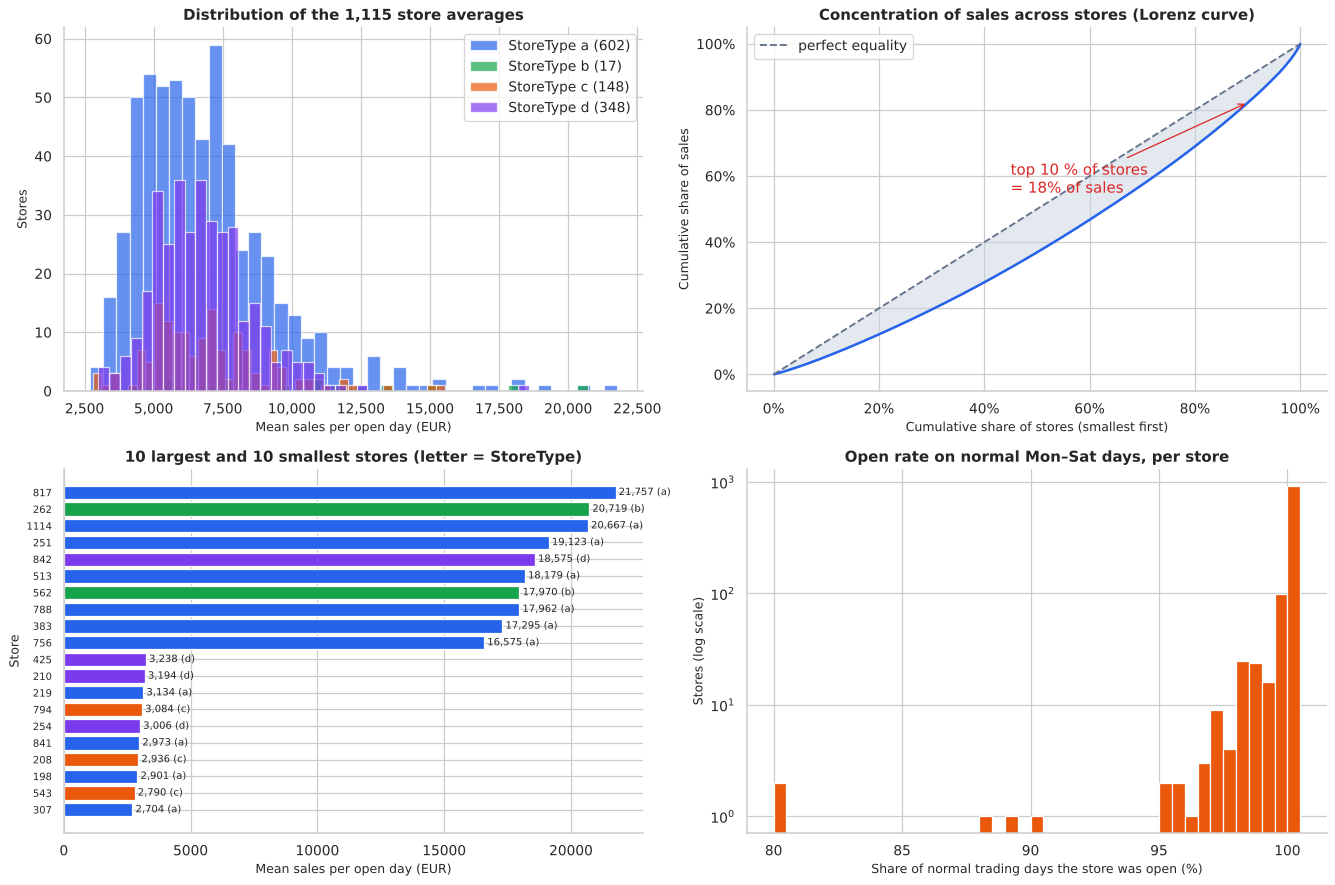

MeanSales           MeanCustomers         SalesPerCustomer      
                mean       std          mean     std             mean   std
StoreType                                                                  
a          6,913.000 2,587.400       792.200 343.800            8.900 1.400
b         10,112.300 4,593.600     1,999.000 859.200            5.100 1.200
c          6,917.900 2,174.200       812.100 285.200            8.600 1.400
d          6,823.900 1,779.700       604.200 158.900           11.300 1.600

In [ ]:
log.info("Section 5.5: store-level analysis")
sl = store_lvl.copy()
tot = op.groupby("Store").Sales.sum().sort_values(ascending=False)
top10_share = tot.head(int(.1 * len(tot))).sum() / tot.sum()
nh_open = train[(train.DayOfWeek <= 6) & (train.StateHoliday == "0")].groupby("Store").Open.mean()
print(f"Store mean sales: median {sl.MeanSales.median():,.0f} | 10th-90th percentile {sl.MeanSales.quantile(.1):,.0f}–{sl.MeanSales.quantile(.9):,.0f} | coefficient of variation {sl.MeanSales.std() / sl.MeanSales.mean():.2f}")
print(f"The top 10 % of the stores generate {top10_share:.1%} of all sales | largest store {sl.MeanSales.idxmax()} ({sl.MeanSales.max():,.0f}) vs smallest {sl.MeanSales.idxmin()} ({sl.MeanSales.min():,.0f})")
print(f"Stores that were closed on more than 3 % of their normal trading days: {int((nh_open < .97).sum())} (min open rate {nh_open.min():.1%})")

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for t, c in zip("abcd", PALETTE):
    axes[0, 0].hist(sl[sl.StoreType == t].MeanSales, bins=40, alpha=.7, color=c, label=f"StoreType {t} ({(sl.StoreType == t).sum()})")
axes[0, 0].set_title("Distribution of the 1,115 store averages"); axes[0, 0].set_xlabel("Mean sales per open day (EUR)"); axes[0, 0].set_ylabel("Stores"); thousands(axes[0, 0], "x"); axes[0, 0].legend()
cs = tot.sort_values().cumsum() / tot.sum(); x = np.arange(1, len(cs) + 1) / len(cs)
axes[0, 1].plot(x, cs.values, color=COLORS["blue"], lw=2); axes[0, 1].plot([0, 1], [0, 1], color=COLORS["grey"], ls="--", label="perfect equality")
axes[0, 1].fill_between(x, cs.values, x, color=COLORS["light"], alpha=.5); axes[0, 1].annotate(f"top 10 % of stores\n= {top10_share:.0%} of sales", (.9, cs.iloc[int(.9 * len(cs))]), xytext=(.45, .55), arrowprops=dict(arrowstyle="->", color=COLORS["red"]), color=COLORS["red"])
percent(axes[0, 1]); percent(axes[0, 1], "x"); axes[0, 1].set_title("Concentration of sales across stores (Lorenz curve)"); axes[0, 1].set_xlabel("Cumulative share of stores (smallest first)"); axes[0, 1].set_ylabel("Cumulative share of sales"); axes[0, 1].legend()
ext = pd.concat([sl.nlargest(10, "MeanSales").assign(grp="Top 10"), sl.nsmallest(10, "MeanSales").assign(grp="Bottom 10")]).sort_values("MeanSales")
cmap = dict(zip("abcd", PALETTE)); axes[1, 0].barh(ext.index.astype(str), ext.MeanSales, color=ext.StoreType.map(cmap))
for y, (v, t) in enumerate(zip(ext.MeanSales, ext.StoreType)): axes[1, 0].text(v, y, f" {v:,.0f} ({t})", va="center", fontsize=8)
axes[1, 0].set_title("10 largest and 10 smallest stores (letter = StoreType)"); axes[1, 0].set_xlabel("Mean sales per open day (EUR)"); axes[1, 0].set_ylabel("Store"); axes[1, 0].tick_params(axis="y", labelsize=8)
axes[1, 1].hist(nh_open * 100, bins=np.arange(80, 100.6, .5), color=COLORS["orange"]); axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Open rate on normal Mon–Sat days, per store"); axes[1, 1].set_xlabel("Share of normal trading days the store was open (%)"); axes[1, 1].set_ylabel("Stores (log scale)")
plt.tight_layout(); plt.show()
display(sl.groupby("StoreType")[["MeanSales", "MeanCustomers", "SalesPerCustomer"]].agg(["mean", "std"]).round(1))

**Interpretation — stores differ a lot in size, but sales are not concentrated in a few giants**
* **Spread:** the median store sells 6,590 per open day; the middle 80 % of the stores lie between 4,527 and 9,677; the largest store (817: 21,757) is **8× the smallest** (307: 2,704). The coefficient of variation is 0.34.
* **Concentration is moderate:** the **top 10 % of the stores generate 17.8 % of the sales** (Lorenz curve close to the diagonal) — a forecast must be accurate for *many* mid-sized stores, not for a handful of big ones. 7 of the 10 largest stores are StoreType `a`, 2 are `b`, 1 is `d`; the 10 smallest are mostly types `a`, `c` and `d`.
* **Types:** `b` stores are larger and far more variable (mean 10,112, std 4,594; customers 1,999) than `a`, `c`, `d` (≈ 6,800–6,900 sales; type `d` has the smallest spread, std 1,780).
* **Open / closed by store:** almost every store is open on > 97 % of its normal trading days (only 13 stores below 97 %, lowest 80.5 %) — those are the temporary refurbishment closures seen in Q7/Q8.
* **Modelling implication:** the store level is the **largest single source of variation** → the `Store` id and store-history features (past average sales/customers) should be very valuable (confirmed in Part 2).

### 5.6 SchoolHoliday impact on sales and customers

**Question.** Do stores sell more (or less) when `SchoolHoliday = 1`? Is the effect the same in every `StoreType`, and does it change when it overlaps with a state holiday?

**How we keep the comparison fair.** School holidays are not spread evenly over the year (they are concentrated in summer, Christmas and Easter), so a plain average would mix the school-holiday effect with *season*, *weekday* and *Promo*. We therefore show (1) the plain comparison and (2) an **adjusted** comparison: lifts are computed inside each `DayOfWeek × Promo` group and then averaged, weighted by the number of school-holiday days. Only open days with sales are used (closed days carry no information about demand).

2026-10-30 07:00:47,164 | INFO     | src.eda | Section 5.6: SchoolHoliday impact


**Plain comparison (open days with sales)**

,sales,customers,spend_per_customer,open_days
No school holiday,"6,897",758,9.48,"680,893"
School holiday,"7,201",783,9.55,"163,445"


Plain lift (school holiday vs not): {'sales': '+4.4%', 'customers': '+3.3%', 'spend_per_customer': '+0.8%'}


Adjusted lift (same weekday and same promo status): {'Sales': '+3.4%', 'Customers': '+2.1%', 'SalesPerCustomer': '+0.9%'}


Stores compared with themselves: 1,115 stores | stores with higher mean sales in school holidays: 82.7% | paired Wilcoxon p = 6.1e-117  (read together with the lift sizes above)


**SchoolHoliday lift by StoreType** (adjusted = same weekday and same promo status)

,stores,days_school_hol,days_no_school_hol,sales_lift_plain,sales_lift_adjusted,customer_lift_adjusted
StoreType,,,,,,
a,602,"88,801","368,241",+5.6%,+2.3%,+0.6%
b,17,"2,878","12,682",-1.2%,-1.9%,-5.1%
c,148,"22,182","90,786",+3.5%,+5.5%,+4.7%
d,348,"49,584","209,184",+3.3%,+4.6%,+3.5%


**SchoolHoliday × StateHoliday (open days with sales)**

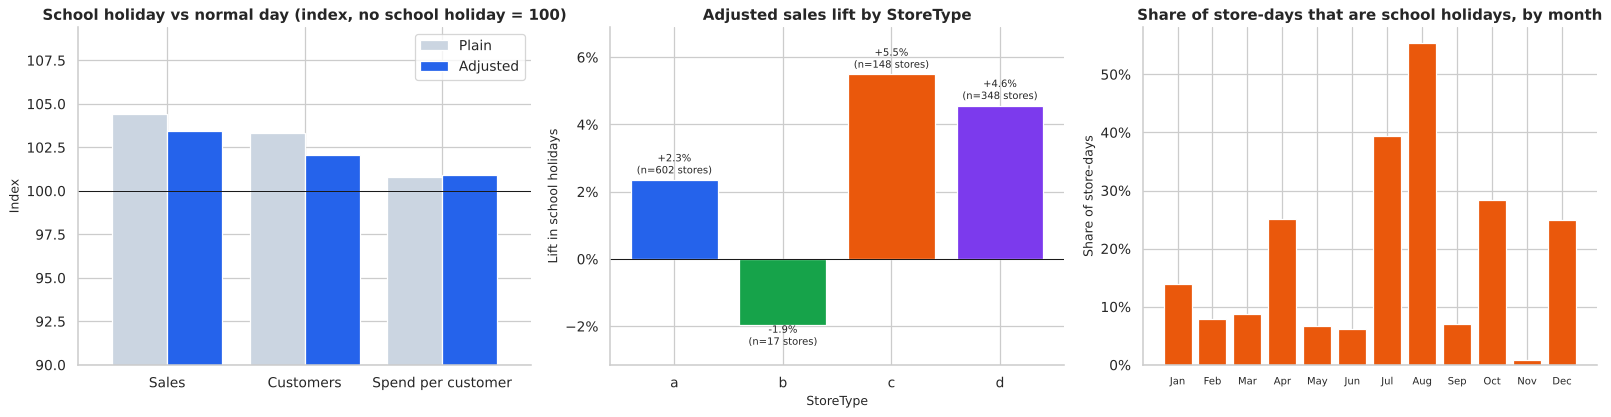

2026-10-30 07:00:48,699 | INFO     | src.visualization.plotting | Saved figure 07_school_holiday.png



Auto-summary: after holding weekday and promo status fixed, a school-holiday day has +3.4% sales, +2.1% customers and +0.9% spend per customer relative to a normal day (plain, unadjusted sales difference: +4.4%).


In [ ]:
log.info("Section 5.6: SchoolHoliday impact")
SH_LABELS = {0: "No school holiday", 1: "School holiday"}

# --- (1) plain comparison: all open days with sales ---------------------------------------------
tab_sh = op.groupby("SchoolHoliday").agg(sales=("Sales", "mean"), customers=("Customers", "mean"),
                                         spend_per_customer=("SalesPerCustomer", "mean"), open_days=("Sales", "size"))
tab_sh.index = [SH_LABELS[i] for i in tab_sh.index]
display(Markdown("**Plain comparison (open days with sales)**"))
display(tab_sh.style.format({"sales": "{:,.0f}", "customers": "{:,.0f}", "spend_per_customer": "{:.2f}", "open_days": "{:,.0f}"}))
plain = tab_sh.loc["School holiday"] / tab_sh.loc["No school holiday"] - 1
print("Plain lift (school holiday vs not):", {k: f"{v:+.1%}" for k, v in plain.items() if k != "open_days"})

# --- (2) adjusted comparison: inside DayOfWeek x Promo groups ----------------------------------
def adjusted_lift(df, value):
    # lift of SchoolHoliday=1 vs 0 inside each DayOfWeek x Promo cell, weighted by # school-holiday days
    cell = df.groupby(["DayOfWeek", "Promo", "SchoolHoliday"]).agg(m=(value, "mean"), n=(value, "size")).unstack("SchoolHoliday").dropna()
    if cell.empty:
        return np.nan
    return float(np.average(cell["m"][1] / cell["m"][0] - 1, weights=cell["n"][1]))

adj = {v: adjusted_lift(op, v) for v in ["Sales", "Customers", "SalesPerCustomer"]}
print("Adjusted lift (same weekday and same promo status):", {k: f"{v:+.1%}" for k, v in adj.items()})

# store-level paired check (each store compared with itself -> removes store-size differences)
st_sh = op.groupby(["Store", "SchoolHoliday"]).Sales.mean().unstack().dropna()
w_sh = stats.wilcoxon(st_sh[1], st_sh[0])
print(f"Stores compared with themselves: {len(st_sh):,} stores | stores with higher mean sales in school holidays: "
      f"{(st_sh[1] > st_sh[0]).mean():.1%} | paired Wilcoxon p = {w_sh.pvalue:.2g}  (read together with the lift sizes above)")

# --- by StoreType -------------------------------------------------------------------------------
rows = []
for t, g in op.groupby("StoreType", observed=True):
    n1, n0 = int((g.SchoolHoliday == 1).sum()), int((g.SchoolHoliday == 0).sum())
    rows.append({"StoreType": t, "stores": g.Store.nunique(), "days_school_hol": n1, "days_no_school_hol": n0,
                 "sales_lift_plain": g[g.SchoolHoliday == 1].Sales.mean() / g[g.SchoolHoliday == 0].Sales.mean() - 1,
                 "sales_lift_adjusted": adjusted_lift(g, "Sales"),
                 "customer_lift_adjusted": adjusted_lift(g, "Customers")})
by_type = pd.DataFrame(rows).set_index("StoreType")
display(Markdown("**SchoolHoliday lift by StoreType** (adjusted = same weekday and same promo status)"))
display(by_type.style.format({"stores": "{:,.0f}", "days_school_hol": "{:,.0f}", "days_no_school_hol": "{:,.0f}", "sales_lift_plain": "{:+.1%}",
                              "sales_lift_adjusted": "{:+.1%}", "customer_lift_adjusted": "{:+.1%}"}))

# --- SchoolHoliday x StateHoliday (open days only; tiny groups are masked) ----------------------
inter = op.groupby(["StateHoliday", "SchoolHoliday"]).agg(open_days=("Sales", "size"), mean_sales=("Sales", "mean"), mean_customers=("Customers", "mean"))
inter.index = pd.MultiIndex.from_tuples([(STATE_HOLIDAY_LABELS.get(a, a), SH_LABELS[b]) for a, b in inter.index], names=["StateHoliday", "SchoolHoliday"])
inter["note"] = np.where(inter.open_days < 100, "n < 100: do not interpret", "")
display(Markdown("**SchoolHoliday × StateHoliday (open days with sales)**"))
display(inter.style.format({"open_days": "{:,.0f}", "mean_sales": "{:,.0f}", "mean_customers": "{:,.0f}"}))

# --- chart -------------------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
idx = pd.DataFrame({"Sales": [1 + plain["sales"], 1 + adj["Sales"]], "Customers": [1 + plain["customers"], 1 + adj["Customers"]],
                    "Spend per customer": [1 + plain["spend_per_customer"], 1 + adj["SalesPerCustomer"]]}, index=["Plain", "Adjusted"]) * 100
idx.T.plot.bar(ax=axes[0], rot=0, color=[COLORS["light"], COLORS["blue"]], width=.8)
axes[0].axhline(100, color="k", lw=.8); axes[0].set_ylim(min(90, idx.values.min() - 3), idx.values.max() + 5)
axes[0].set_title("School holiday vs normal day (index, no school holiday = 100)"); axes[0].set_ylabel("Index"); axes[0].set_xlabel("")
axes[1].bar(by_type.index.astype(str), by_type.sales_lift_adjusted, color=PALETTE[:len(by_type)], label="Sales")
for i, (v, n) in enumerate(zip(by_type.sales_lift_adjusted, by_type.stores)): axes[1].text(i, v + (.002 if v >= 0 else -.006), f"{v:+.1%}\n(n={n} stores)", ha="center", fontsize=8)
axes[1].axhline(0, color="k", lw=.8); percent(axes[1]); axes[1].set_ylim(by_type.sales_lift_adjusted.min() - .012, by_type.sales_lift_adjusted.max() + .014); axes[1].set_title("Adjusted sales lift by StoreType"); axes[1].set_xlabel("StoreType"); axes[1].set_ylabel("Lift in school holidays")
share_m = train.groupby("Month").SchoolHoliday.mean()
axes[2].bar([MONTH_NAMES[m] for m in share_m.index], share_m.values, color=COLORS["orange"])
percent(axes[2]); axes[2].set_title("Share of store-days that are school holidays, by month"); axes[2].set_ylabel("Share of store-days"); axes[2].tick_params(axis="x", labelsize=8)
plt.tight_layout(); fig_sh = fig; plt.show()
save_figure(fig_sh, "07_school_holiday", cfg)

print(f"\nAuto-summary: after holding weekday and promo status fixed, a school-holiday day has {adj['Sales']:+.1%} sales, "
      f"{adj['Customers']:+.1%} customers and {adj['SalesPerCustomer']:+.1%} spend per customer relative to a normal day "
      f"(plain, unadjusted sales difference: {plain['sales']:+.1%}).")

**How to read 5.6 (answer the three questions for the report after running the cell).**
1. *What does the chart show?* Left: school-holiday vs normal-day index for sales, customers and spend per customer (plain vs adjusted). Middle: the adjusted sales lift in each StoreType, with the number of stores. Right: in which months school holidays occur.
2. *What pattern is visible?* Compare the **plain** and **adjusted** bars: if they differ, part of the plain gap is just season/weekday/promo mix (school holidays cluster in summer and around Christmas/Easter). Check whether the sign and size of the lift are the same in all StoreTypes; StoreType `b` has few stores, so treat it with care.
3. *Business implication?* If the adjusted lift is small, `SchoolHoliday` is a **weak** stand-alone driver and should be kept as a cheap binary feature (allowed to interact with `StoreType` and month). If a StoreType shows a clearly different lift, include a `StoreType × SchoolHoliday` interaction in Part 2.

**StateHoliday overlap:** open days on a state holiday are rare (most stores close), so the `StateHoliday × SchoolHoliday` table is only readable where `open_days` is large. Rows marked *n < 100* must not be interpreted.

*Association, not causation:* the table shows how sales differ on school-holiday days after controlling for weekday and promo; it cannot rule out other overlapping factors (region, weather, summer holidays).

**Findings 5.6 (from the run on the real data)**
* **Sales:** +4.4 % on school-holiday days (7,201 vs 6,897) in the plain comparison, but only **+3.4 %** once weekday and promo status are held fixed. **Customers +2.1 %** (adjusted) and spend per customer only +0.9 %. So a school holiday brings slightly more visitors, not bigger baskets.
* **Consistency:** 82.7 % of stores sell more in school holidays than outside them (paired Wilcoxon p ≈ 6e-117). With 1,115 stores and ~840,000 days, p is tiny for almost any difference, so the *size* (+3 %) is what matters: the effect is **real but small** compared with Promo (+39 %).
* **By StoreType (adjusted sales lift):** `c` +5.5 %, `d` +4.6 %, `a` +2.3 %, `b` −1.9 % (only 17 stores, not reliable). The customer lift is +4.7 % (`c`), +3.5 % (`d`), +0.6 % (`a`), −5.1 % (`b`).
* **StateHoliday overlap:** open days on a state holiday are very rare (e.g. 104 public-holiday open days with school holiday; Easter 139; Christmas 71; Easter without school holiday only 6), so no reliable school-holiday effect can be measured on state holidays.
* **Implication:** keep `SchoolHoliday` as a cheap binary feature but do not expect it to be a strong driver; a `StoreType × SchoolHoliday` interaction is worth letting tree models find.

### 5.7 Data-gap analysis — missing dates and incomplete store histories

A **missing row** (a store-day that does not exist in `train.csv`) is different from a **closed day** (`Open = 0`, a row that exists with 0 sales). We must not mix them. Here we build the full calendar `first date … last date` and check, store by store, which days have no row at all. **No missing rows are invented or filled**; the result is only documented (and saved as a small table for Part 2).

2026-10-30 07:00:48,715 | INFO     | src.eda | Section 5.7: data-gap analysis


Calendar: 2013-01-01 → 2015-07-31 = 942 days | days that exist in train for at least one store: 942
Calendar days with NO row for any store: 0
Complete stores (a row on every calendar day): 934 | incomplete stores: 181


**Gap patterns (identical gaps are grouped; `stores` = how many stores share it)**

gap_start,gap_end,gap_days,stores
2014-07-01,2014-12-31,184,180
2013-01-01,2013-01-01,1,1


Largest pattern: 180 stores have no rows from 2014-07-01 to 2014-12-31 (184 days).
Stores whose gap is exactly 2014-07-01 → 2014-12-31: 180  (the documented July–December 2014 issue)
Stores with any OTHER gap: 1  | stores whose history starts after 2013-01-01: 1
Test stores: 856 | gap stores that are also in test: 181 | gap stores NOT in test: 0


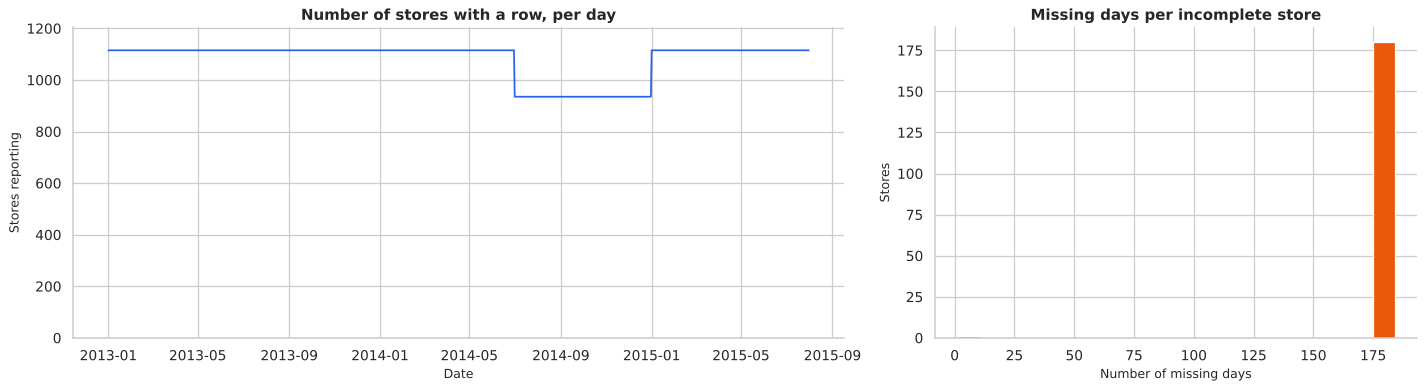

2026-10-30 07:00:49,630 | INFO     | src.visualization.plotting | Saved figure 08_data_gaps.png


2026-10-30 07:00:49,635 | INFO     | src.eda | Data-gap table saved: store_data_gaps.csv (181 gap blocks, 181 stores)


In [ ]:
log.info("Section 5.7: data-gap analysis")
all_days = pd.date_range(train.Date.min(), train.Date.max(), freq="D")
rows_per_store = train.groupby("Store").size()
missing_cnt = (len(all_days) - rows_per_store)
print(f"Calendar: {all_days.min().date()} → {all_days.max().date()} = {len(all_days)} days | days that exist in train for at least one store: {train.Date.nunique()}")
print(f"Calendar days with NO row for any store: {len(all_days.difference(pd.DatetimeIndex(train.Date.unique())))}")
print(f"Complete stores (a row on every calendar day): {int((missing_cnt == 0).sum())} | incomplete stores: {int((missing_cnt > 0).sum())}")

# --- gap blocks per incomplete store (only the incomplete stores are scanned -> cheap) -----------
inc = missing_cnt[missing_cnt > 0].index
sub = train.loc[train.Store.isin(inc), ["Store", "Date"]]
recs = []
for s, g in sub.groupby("Store"):
    miss = all_days.difference(pd.DatetimeIndex(g.Date))
    blk = (pd.Series(miss).diff().dt.days != 1).cumsum()            # consecutive missing days = one block
    for _, b in pd.Series(miss).groupby(blk.values):
        recs.append({"Store": s, "gap_start": b.iloc[0], "gap_end": b.iloc[-1], "gap_days": len(b)})
gaps = pd.DataFrame(recs)
summary = (gaps.groupby(["gap_start", "gap_end", "gap_days"]).agg(stores=("Store", "nunique")).reset_index().sort_values("stores", ascending=False))
display(Markdown("**Gap patterns (identical gaps are grouped; `stores` = how many stores share it)**"))
display(summary.head(10).style.format({"gap_start": "{:%Y-%m-%d}", "gap_end": "{:%Y-%m-%d}"}).hide(axis="index"))

top = summary.iloc[0]
print(f"Largest pattern: {int(top.stores)} stores have no rows from {top.gap_start:%Y-%m-%d} to {top.gap_end:%Y-%m-%d} ({int(top.gap_days)} days).")
jd = (gaps.gap_start == pd.Timestamp("2014-07-01")) & (gaps.gap_end == pd.Timestamp("2014-12-31"))
print(f"Stores whose gap is exactly 2014-07-01 → 2014-12-31: {gaps.loc[jd, 'Store'].nunique()}  (the documented July–December 2014 issue)")
other = gaps[~gaps.Store.isin(gaps.loc[jd, "Store"])]
print(f"Stores with any OTHER gap: {other.Store.nunique()}  | stores whose history starts after {all_days.min().date()}: "
      f"{int((train.groupby('Store').Date.min() > all_days.min()).sum())}")

# --- link to the forecasting target: are the gap stores in the test set? ------------------------
gap_stores = set(gaps.Store)
test_stores = set(test.Store.unique())
print(f"Test stores: {len(test_stores)} | gap stores that are also in test: {len(gap_stores & test_stores)} | "
      f"gap stores NOT in test: {len(gap_stores - test_stores)}")

# --- chart: how many stores report each day ----------------------------------------------------
daily = train.groupby("Date").Store.nunique().reindex(all_days)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(daily.index, daily.values, color=COLORS["blue"], lw=1.4)
axes[0].set_ylim(0, train.Store.nunique() * 1.08); axes[0].set_title("Number of stores with a row, per day"); axes[0].set_ylabel("Stores reporting"); axes[0].set_xlabel("Date")
axes[1].hist(missing_cnt[missing_cnt > 0], bins=20, color=COLORS["orange"])
axes[1].set_title("Missing days per incomplete store"); axes[1].set_xlabel("Number of missing days"); axes[1].set_ylabel("Stores")
plt.tight_layout(); fig_gap = fig; plt.show()
save_figure(fig_gap, "08_data_gaps", cfg)

# --- save the gap table for Part 2 (small CSV, raw data untouched) ----------------------------
gap_path = get_dir(cfg, "processed_dir") / "store_data_gaps.csv"
gaps.to_csv(gap_path, index=False)
log.info("Data-gap table saved: %s (%d gap blocks, %d stores)", gap_path.name, len(gaps), gaps.Store.nunique())

**How to read 5.7.**
1. *What does the chart show?* Left: how many stores have a row on each day (a full line = every store present; a drop = missing rows). Right: how many days are missing in each incomplete store.
2. *What pattern is visible?* The table of gap patterns shows whether the missing days are one shared block (the same stores lose the same dates) or scattered. The line should drop for the July–December 2014 window if the 180-store gap described in the project is present; the printed counts confirm or reject it for this dataset.
3. *Business / modelling implication:*
   * These are **missing records, not zero sales and not closures**; they must **not** be filled with 0 (that would teach a model that those stores stopped selling).
   * Lag and rolling features (e.g. "sales 42 days ago", "last 6 weeks mean") must be built on the **calendar date**, not on row position, otherwise the shift lands on the wrong day for gap stores.
   * For validation, use a time-based hold-out and report the score separately for gap stores and complete stores.
   * For an LSTM, either train per store on continuous segments only, or mask the gap; do not interpolate silently.
   * If a gap store is also in the test set, its recent history (the last weeks before 2015-08-01) is still complete, because the gap ends in 2014; therefore the leak-safe history features of Part 1 remain valid for it.

**Findings 5.7 (from the run on the real data)**
* The calendar 2013-01-01 → 2015-07-31 has 942 days and every day exists for at least one store; the problem is at **store level**: 934 stores are complete, **181 are incomplete**.
* **Confirmed:** **180 stores have no rows from 2014-07-01 to 2014-12-31 (184 days)**. The 181st store (store 988) misses only 2013-01-01 (1 day) and is harmless.
* **Important for modelling:** all 181 incomplete stores are also in the test set (856 stores), i.e. about 21 % of the test stores. Their recent history (Jan–Jul 2015) is complete, so "last 6 weeks" style features still work, **but any "same period last year" feature for the test window (Aug–Sep 2015 → Aug–Sep 2014) is missing for these 180 stores.** Use year-ago features only with a missing-value rule or skip them.
* The gap table is saved to `data/processed/store_data_gaps.csv` for Part 2.

### 5.8 How to read the numbers in this notebook (statistical interpretation guide)

| Term | Simple meaning | How we use it here | Caution |
|---|---|---|---|
| **Correlation (Pearson / Spearman, ρ or r)** | How strongly two columns move together, from −1 to +1. 0 = no linear/ranked link. | Sales vs Customers (Q4), Spearman heat-map (5.3). Spearman is preferred when data are skewed (Sales is right-skewed). | Correlation ≠ causation. Two columns can move together because a third factor (e.g. season or store size) drives both. |
| **Percentage change / lift** | `(new − old) / old`. A promo lift of +39 % means promo days sell 1.39× the non-promo days. | Promo, SchoolHoliday, competitor lift tables. | A lift is only meaningful with a fair comparison group and enough rows (we always show `n`). Percent and euro effects can disagree (small stores: big %, small €). |
| **p-value** | If there were truly *no* difference, how often would we see a difference at least this large just by luck? Small p (< 0.05) = "unlikely to be luck". | Wilcoxon / Mann–Whitney / Kruskal–Wallis / χ² tests where we compare groups. | With ~1 million rows, p-values are almost always tiny, even for useless differences. **Always read the effect size** (lift %, Cramér's V, ρ) next to p. A small p does *not* mean a large or important effect. |
| **Effect size** | How big the difference is, ignoring sample size. | Lift %, Cramér's V (Q1), ρ. | Judge by business meaning (euros, customers), not by p. |
| **Association vs causation** | "Goes together with" vs "is caused by". | Every Answer block. | Rossmann promotions were not randomly assigned (they run chain-wide on set dates), so a promo lift is an **association** that is very likely, but not proven, to be caused by the promo. Only an A/B test proves it. |

**Limitations of this data (observational, not an experiment)**
1. No randomisation: promotions, school holidays, and competitor openings are not assigned at random to stores or days.
2. Confounding: season, weekday, store size and store type overlap with almost every factor (e.g. school holidays fall mostly in summer and Christmas).
3. `Customers` counts visits, not unique people; there is no customer ID, so "new" vs "existing" customers cannot be separated.
4. `store.csv` is a single snapshot: it does not show how `CompetitionDistance`, assortment or store type changed over time.
5. Sales are in euros of turnover; there is no profit, margin or discount-cost information.

*Rule used throughout: we state results as "is associated with" and propose an A/B test where a business decision depends on it. We did not add extra statistical tests beyond those that answer a question asked in the project brief.*

## 6. The 11 required business questions
Common definitions used below: **open day** = `Open == 1` and `Sales > 0`; **Sales index** = a day's sales ÷ the same store's normal sales on the same weekday (so 1.20 = 20 % above that store's usual level — this removes the weekday and store-size effect); **promo lift** = promo-day sales ÷ non-promo-day sales − 1 (weekdays only, per store).

### Q1 — Are the train and test sets distributed alike? Are promotions similarly distributed?

2026-10-30 07:00:49,653 | INFO     | src.eda | Q1: train vs test distribution


,rows,stores,Promo share (all rows),Promo share (open rows),Open share,SchoolHoliday share,StateHoliday share
Train (all),"1,017,209","1,115",38.2%,44.6%,83.0%,17.9%,3.1%
Train (same 856 stores),"773,231",856,38.1%,44.5%,83.0%,17.8%,3.1%
Train 1 Aug–17 Sep 2013,"53,520","1,115",35.4%,41.1%,85.4%,37.5%,0.3%
Train 1 Aug–17 Sep 2014,"44,880",935,39.6%,46.1%,85.6%,43.1%,0.0%
Test (1 Aug–17 Sep 2015),"41,088",856,39.6%,46.3%,85.4%,44.3%,0.4%


Promo share among open rows: train 44.5% vs test 46.3%  (difference +1.7 pp)
Chi-square p-value = 1.4e-10, Cramér's V = 0.008  → effect size is negligible
Test promo share by weekday: {'Mon': 0.57, 'Tue': 0.57, 'Wed': 0.57, 'Thu': 0.57, 'Fri': 0.5, 'Sat': 0.0, 'Sun': 0.0}
Test: do all stores have the same promo on a given date? → True | Train: True


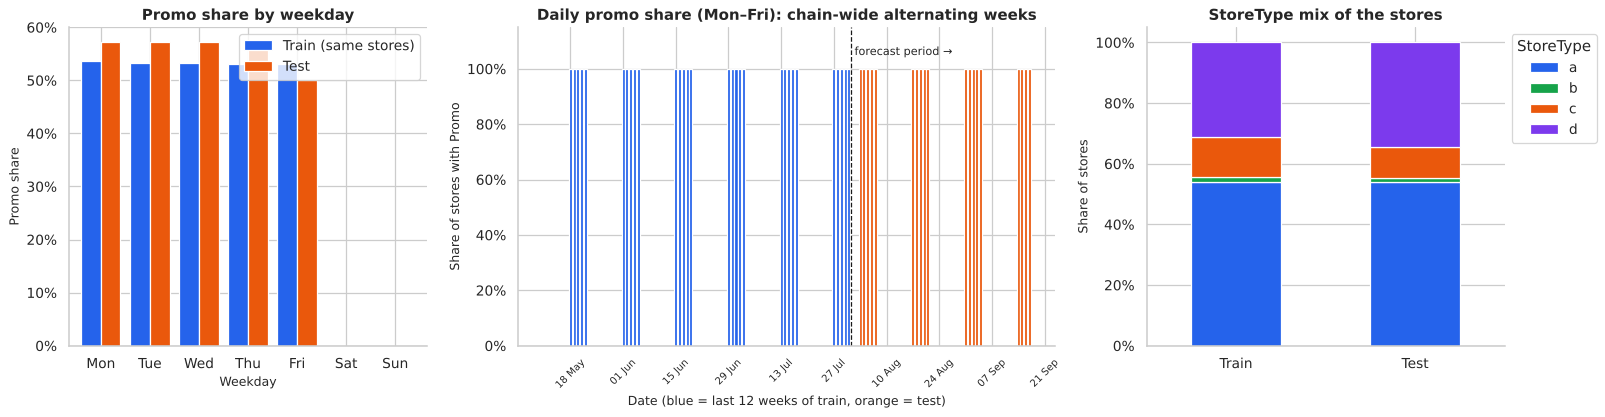

In [ ]:
log.info("Q1: train vs test distribution")
common = test.Store.unique()
tr_c = train[train.Store.isin(common)]                           # same 856 stores as test
md_ = train.Date.dt.month * 100 + train.Date.dt.day
def split_stats(df, name):
    o = df[df.Open == 1]
    return pd.Series({"rows": len(df), "stores": df.Store.nunique(),
                      "Promo share (all rows)": df.Promo.mean(), "Promo share (open rows)": o.Promo.mean(),
                      "Open share": df.Open.mean(), "SchoolHoliday share": df.SchoolHoliday.mean(),
                      "StateHoliday share": (df.StateHoliday != "0").mean()}, name=name)
tab = pd.concat([split_stats(train, "Train (all)"), split_stats(tr_c, "Train (same 856 stores)"),
                 split_stats(train[(train.Year == 2013) & (md_ >= 801) & (md_ <= 917)], "Train 1 Aug–17 Sep 2013"),
                 split_stats(train[(train.Year == 2014) & (md_ >= 801) & (md_ <= 917)], "Train 1 Aug–17 Sep 2014"),
                 split_stats(test, "Test (1 Aug–17 Sep 2015)")], axis=1).T
fmt = {c: "{:.1%}" for c in tab.columns if "share" in c}; fmt.update({"rows": "{:,.0f}", "stores": "{:,.0f}"})
display(tab.style.format(fmt))

# statistical check: is the Promo share among open days different? (large n -> look at the EFFECT size too)
o_tr, o_te = tr_c[tr_c.Open == 1].Promo, test[test.Open == 1].Promo
chi = stats.chi2_contingency(pd.crosstab(np.r_[np.zeros(len(o_tr)), np.ones(len(o_te))], np.r_[o_tr, o_te]))
v = np.sqrt(chi[0] / (len(o_tr) + len(o_te)))
print(f"Promo share among open rows: train {o_tr.mean():.1%} vs test {o_te.mean():.1%}  (difference {100 * (o_te.mean() - o_tr.mean()):+.1f} pp)")
print(f"Chi-square p-value = {chi[1]:.2g}, Cramér's V = {v:.3f}  → effect size is {'negligible' if v < 0.05 else 'small or larger'}")
print("Test promo share by weekday:", test.groupby("DayOfWeek").Promo.mean().round(2).rename(DAY_NAMES).to_dict())
print("Test: do all stores have the same promo on a given date? →", bool((test.groupby("Date").Promo.nunique() == 1).all()),
      "| Train:", bool((train.groupby("Date").Promo.nunique() == 1).all()))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1, 1.5, 1]})
d = pd.DataFrame({"Train (same stores)": tr_c.groupby("DayOfWeek").Promo.mean(), "Test": test.groupby("DayOfWeek").Promo.mean()})
d.index = [DAY_NAMES[i] for i in d.index]; d.plot.bar(ax=axes[0], color=[COLORS["blue"], COLORS["orange"]], rot=0, width=.8)
percent(axes[0]); axes[0].set_title("Promo share by weekday"); axes[0].set_xlabel("Weekday"); axes[0].set_ylabel("Promo share")
recent = pd.concat([train[train.Date >= train.Date.max() - pd.Timedelta(days=83)][["Date", "Promo", "DayOfWeek"]].assign(Split="Train"),
                    test[["Date", "Promo", "DayOfWeek"]].assign(Split="Test")])
dp = recent[recent.DayOfWeek <= 5].groupby(["Date", "Split"]).Promo.mean().reset_index()
axes[1].bar(dp.Date, dp.Promo, width=.8, color=dp.Split.map({"Train": COLORS["blue"], "Test": COLORS["orange"]}))
axes[1].axvline(train.Date.max() + pd.Timedelta(days=0.5), color="k", ls="--", lw=1); axes[1].text(train.Date.max() + pd.Timedelta(days=1.5), 1.05, "forecast period →", fontsize=9)
axes[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b")); axes[1].tick_params(axis="x", labelrotation=45, labelsize=8)
percent(axes[1]); axes[1].set_ylim(0, 1.15); axes[1].set_title("Daily promo share (Mon–Fri): chain-wide alternating weeks")
axes[1].set_xlabel("Date (blue = last 12 weeks of train, orange = test)"); axes[1].set_ylabel("Share of stores with Promo")
mix = pd.DataFrame({"Train": store.StoreType.value_counts(normalize=True), "Test": store[store.Store.isin(common)].StoreType.value_counts(normalize=True)}).sort_index()
mix.T.plot.bar(stacked=True, ax=axes[2], color=PALETTE[:4], rot=0); percent(axes[2]); axes[2].set_title("StoreType mix of the stores")
axes[2].set_xlabel(""); axes[2].set_ylabel("Share of stores"); axes[2].legend(title="StoreType", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

**Answer Q1 — Train and test are very similar, and promotions are similarly distributed.**
* **Promotions:** the share of store-days with a promotion is 38.2 % in train vs 39.6 % in test (among *open* rows 44.5 % in train (the same 856 stores as the test set; 44.6 % if all 1,115 stores are used) vs 46.3 % in test, a +1.7 pp difference; Cramér's V = 0.008 → a statistically "significant" p-value only because of the huge sample, the effect size is negligible). The **weekday pattern is the same** (Mon–Fri only, never at weekends) and, in both files, **all stores run the same promo on the same date** — promotion is a *chain-wide calendar*. The test window sits at the upper end of the seasonal comparison (41.1 % in Aug–Sep 2013, 46.1 % in Aug–Sep 2014, 46.3 % in test) because it simply contains slightly more promo weeks.
* **Other differences are seasonal, not drift:** school-holiday share is 44 % in test vs 18 % overall — but 38–43 % in the same Aug–Sep window of 2013/2014; the open share (85.4 %) equals Aug–Sep 2013/2014 (85.4 %/85.6 %). The test period has **only public holidays (`a`, 180 store-days)** — no Easter, no Christmas.
* **Store coverage:** test contains **856 of the 1,115 stores**; the StoreType mix is close to train (a 54 %, d 34 %, c 10 %, b 1.4 % vs 54 %, 31 %, 13 %, 1.5 %) — type `c` is slightly under-represented, `d` slightly over-represented.
* **Modelling implication:** use the *last 6 weeks* of train as validation (same horizon and season logic as the test), give weight to the seasonally comparable Aug–Sep periods, and remember that the biggest holiday effects (Christmas/Easter) are irrelevant for the test period even though they matter for training stability.

### Q2 — How does sales behaviour differ **before**, **during** and **after** holidays?
Method: for every store-holiday block we look 3 days before the first holiday day, at the holiday days themselves, and 3 days after the last holiday day. Holiday days that are ≤ 3 days apart form ONE block (Good Friday … Easter Monday; 25–26 December), and days that are themselves holidays are excluded from the before/after windows.

2026-10-30 07:00:51,008 | INFO     | src.eda | Q2: sales around holidays


**Sales index of the stores that were open** (1.00 = normal level for that store and weekday)

type,Public holiday,Easter,Christmas
offset,,,
-3,0.99,1.32,1.42
-2,1.04,1.37,1.60
-1,1.14,1.48,0.71
0,1.04,1.01,1.03
1,1.15,0.94,1.05
2,0.98,0.85,1.03
3,1.02,0.85,0.94


**Share of stores that were open**

type,Public holiday,Easter,Christmas
offset,,,
-3,88%,100%,47%
-2,98%,100%,100%
-1,81%,100%,100%
0,3%,2%,2%
1,98%,100%,100%
2,86%,100%,56%
3,55%,100%,47%


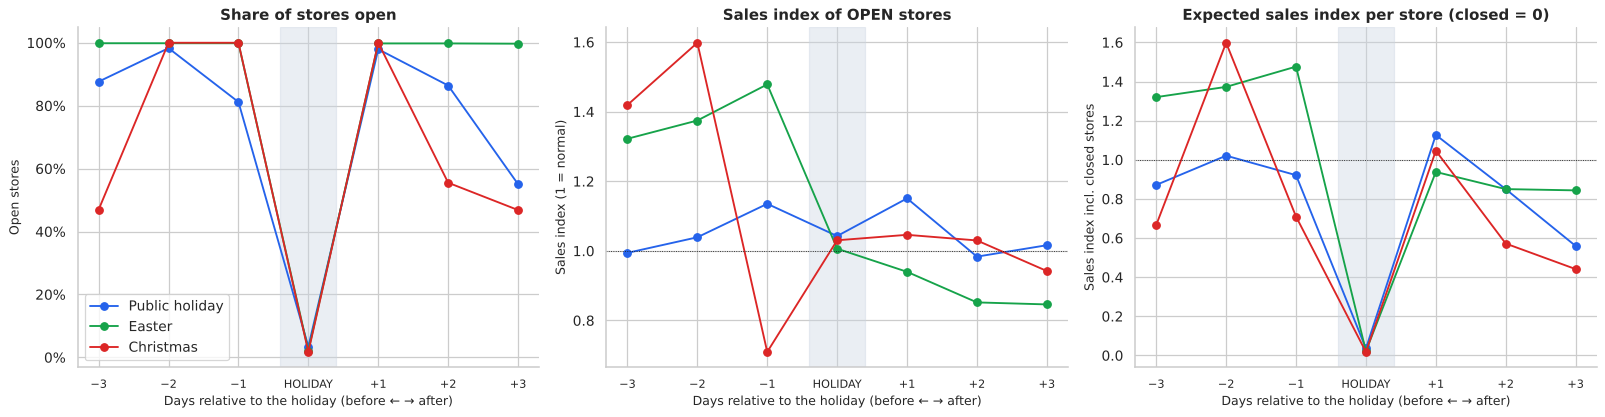

**School-holiday blocks of ≥ 5 days (28,837 blocks)**

,window,open_share,sales_index_open,n
0,before (−7…−1),85.3%,1.048,"192,660"
1,during (first 7 days),85.2%,0.996,"186,964"
2,after (+1…+7),85.4%,0.980,"189,326"


In [ ]:
log.info("Q2: sales around holidays")
normal = train[(train.Open == 1) & (train.Sales > 0) & (train.StateHoliday == "0")]
base = normal.groupby(["Store", "DayOfWeek"]).Sales.mean().rename("BaseSales").reset_index()
ti = train.merge(base, on=["Store", "DayOfWeek"], how="left")
ti["SalesIndex"] = ti.Sales / ti.BaseSales                       # 1.0 = this store's normal level for that weekday
op_i = ti[(ti.Open == 1) & (ti.Sales > 0)].copy()                # reused in Q3

hol = train.loc[train.StateHoliday != "0", ["Store", "Date", "StateHoliday"]].sort_values(["StateHoliday", "Store", "Date"]).reset_index(drop=True)
new_block = hol.groupby(["Store", "StateHoliday"]).Date.diff().dt.days.fillna(99).gt(3)   # holidays <= 3 days apart = ONE block (Good Friday ... Easter Monday)
hol["block"] = new_block.cumsum()
blocks = hol.groupby("block").agg(Store=("Store", "first"), type=("StateHoliday", "first"), start=("Date", "min"), end=("Date", "max"))

idx = ti.set_index(["Store", "Date"])[["Open", "Sales", "SalesIndex", "StateHoliday"]]
ev_rows = []
for off in [-3, -2, -1, 0, 1, 2, 3]:
    if off < 0:   keys = list(zip(blocks.Store, blocks.start + pd.Timedelta(days=off))); types = blocks.type.values
    elif off > 0: keys = list(zip(blocks.Store, blocks.end + pd.Timedelta(days=off)));   types = blocks.type.values
    else:         keys = list(zip(hol.Store, hol.Date));                                  types = hol.StateHoliday.values
    v = idx.reindex(pd.MultiIndex.from_tuples(keys, names=["Store", "Date"])).reset_index(drop=True)
    v["type"] = types; v["offset"] = off
    ev_rows.append(v)
ev = pd.concat(ev_rows).dropna(subset=["Open"])
ev = ev[(ev.offset == 0) | (ev.StateHoliday == "0")]             # before/after windows must be normal days
ev["open_sales"] = (ev.Open == 1) & (ev.Sales > 0)
summ = ev.groupby(["type", "offset"]).agg(open_share=("Open", "mean"), n=("Open", "size"))
summ["sales_index_open"] = ev[ev.open_sales].groupby(["type", "offset"]).SalesIndex.mean()
summ["expected_index_all"] = ev.assign(si=np.where(ev.open_sales, ev.SalesIndex, 0)).groupby(["type", "offset"]).si.mean()
summ = summ.reset_index()
pv = summ.pivot(index="offset", columns="type", values="sales_index_open").rename(columns=STATE_HOLIDAY_LABELS)
po = summ.pivot(index="offset", columns="type", values="open_share").rename(columns=STATE_HOLIDAY_LABELS)
display(Markdown("**Sales index of the stores that were open** (1.00 = normal level for that store and weekday)")); display(pv.style.format("{:.2f}"))
display(Markdown("**Share of stores that were open**")); display(po.style.format("{:.0%}"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
colors = {"a": COLORS["blue"], "b": COLORS["green"], "c": COLORS["red"]}
xt = [-3, -2, -1, 0, 1, 2, 3]; xl = ["−3", "−2", "−1", "HOLIDAY", "+1", "+2", "+3"]
for t, g in summ.groupby("type"):
    axes[0].plot(g.offset, g.open_share, marker="o", color=colors[t], label=STATE_HOLIDAY_LABELS[t])
    axes[1].plot(g.offset, g.sales_index_open, marker="o", color=colors[t], label=STATE_HOLIDAY_LABELS[t])
    axes[2].plot(g.offset, g.expected_index_all, marker="o", color=colors[t], label=STATE_HOLIDAY_LABELS[t])
axes[0].set_title("Share of stores open"); percent(axes[0]); axes[0].set_ylabel("Open stores")
axes[1].set_title("Sales index of OPEN stores"); axes[1].axhline(1, color="k", lw=.7, ls=":"); axes[1].set_ylabel("Sales index (1 = normal)")
axes[2].set_title("Expected sales index per store (closed = 0)"); axes[2].axhline(1, color="k", lw=.7, ls=":"); axes[2].set_ylabel("Sales index incl. closed stores")
for ax in axes:
    ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=9); ax.set_xlabel("Days relative to the holiday (before ← → after)"); ax.axvspan(-.4, .4, color=COLORS["light"], alpha=.4)
axes[0].legend(); plt.tight_layout(); fig_hol = fig; plt.show()

# School holidays: before / during / after the blocks of consecutive school-holiday days
tmp = ti.sort_values(["Store", "Date"]).copy()
tmp["blk"] = tmp.groupby("Store").SchoolHoliday.transform(lambda s: (s != s.shift()).cumsum())
sh = tmp[tmp.SchoolHoliday == 1].groupby(["Store", "blk"]).Date.agg(["min", "max", "size"]).reset_index()
sh = sh[sh["size"] >= 5]
rows = []
ix2 = ti.set_index(["Store", "Date"])
for lab, col, offs in [("before (−7…−1)", "min", range(-7, 0)), ("during (first 7 days)", "min", range(0, 7)), ("after (+1…+7)", "max", range(1, 8))]:
    keys = [(s, d + pd.Timedelta(days=o)) for s, d in zip(sh.Store, sh[col]) for o in offs]
    v = ix2.reindex(pd.MultiIndex.from_tuples(keys)).dropna(subset=["Open"])
    v = v[(v.StateHoliday == "0")]
    rows.append((lab, v.Open.mean(), v[(v.Open == 1) & (v.Sales > 0)].SalesIndex.mean(), len(v)))
sch = pd.DataFrame(rows, columns=["window", "open_share", "sales_index_open", "n"])
display(Markdown(f"**School-holiday blocks of ≥ 5 days ({len(sh):,} blocks)**")); display(sch.style.format({"open_share": "{:.1%}", "sales_index_open": "{:.3f}", "n": "{:,.0f}"}))

**Answer Q2 — sales build up *before* holidays, stores are closed *during* them, and demand falls back *after* big holidays.**
| Holiday | Before (−3 … −1 days) | During | After (+1 … +3 days) |
|---|---|---|---|
| **Public holiday (`a`)** | ≈ normal, then **+14 %** on the day before; only 81–88 % of stores open | **97 % of stores closed**; open ones ≈ +4 % | **+15 %** on the first day after, back to normal afterwards |
| **Easter (`b`)** | **strong build-up: +32 %, +37 %, +48 %** (all stores open) | 98 % closed | **dip: −6 %, −15 %, −15 %** |
| **Christmas (`c`)** | peak **+60 % on 23 Dec** (+42 % on 22 Dec); **24 Dec only 0.71** (short trading day) | 98 % closed | back to ≈ normal (+5 %, +3 %, −6 %) |

* The *expected* sales index per store (right panel, closed stores counted as 0) shows how large the holiday effect is for a forecast: roughly **0 on the day, 1.4–1.6× before Easter/Christmas**, and a 15 % hangover after Easter.
* **School holidays** (blocks of ≥ 5 days, 28,837 blocks): sales index **1.05 in the 7 days before**, ≈ **1.00 during** and **0.98 after**; the share of open stores does not change (≈ 85 %). Once weekday and store level are controlled, school holidays have only a small effect — the raw difference (7,201 vs 6,897) is mostly a seasonal mix effect (Q3).
* **Modelling implication:** `StateHoliday`, `IsBeforeHoliday`, `IsAfterHoliday`, `DaysToNextHoliday`, `DaysSinceLastHoliday` (store-aware) and `Open` are essential; holiday types need to be distinguished (Easter and Christmas behave very differently from ordinary public holidays).

### Q3 — Seasonal purchasing behaviour (Christmas, Easter and other periods)

2026-10-30 07:00:59,804 | INFO     | src.eda | Q3: seasonality


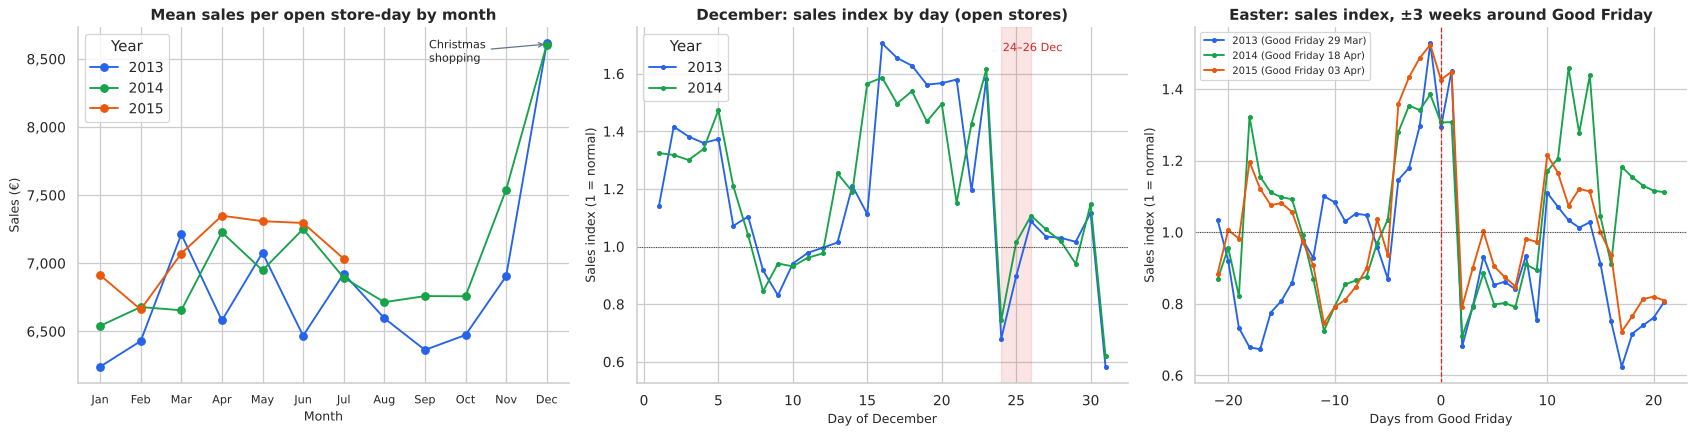

2026-10-30 07:01:00,609 | INFO     | src.visualization.plotting | Saved figure 03_seasonality.png


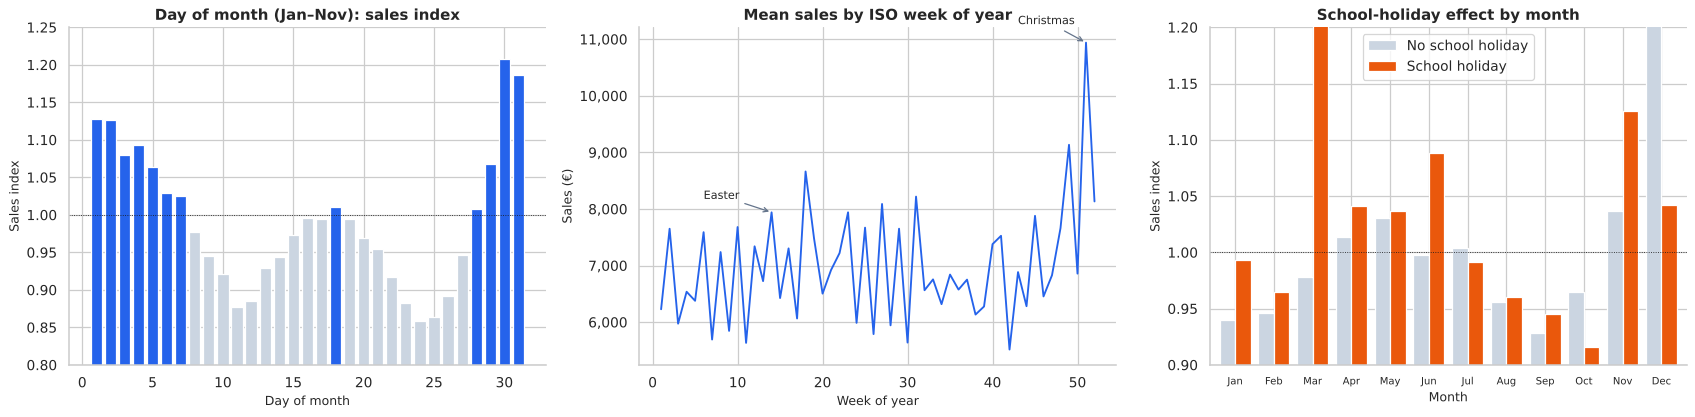

Mean sales per open day by month (all years): {'Jan': 6564, 'Feb': 6589, 'Mar': 6977, 'Apr': 7047, 'May': 7107, 'Jun': 7001, 'Jul': 6954, 'Aug': 6649, 'Sep': 6547, 'Oct': 6603, 'Nov': 7189, 'Dec': 8609}
Year-on-year (same Jan–Jun months): 2013 6663 → 2014 6876 → 2015 7098


In [ ]:
log.info("Q3: seasonality")
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
# (a) month profile per year
mp = op.groupby(["Year", "Month"]).Sales.mean().unstack(0)
for y, c in zip(mp.columns, PALETTE): axes[0].plot(mp.index, mp[y], marker="o", color=c, label=str(y))
axes[0].set_xticks(range(1, 13)); axes[0].set_xticklabels([MONTH_NAMES[m] for m in range(1, 13)], fontsize=9)
axes[0].set_title("Mean sales per open store-day by month"); axes[0].set_ylabel("Sales (€)"); axes[0].set_xlabel("Month"); thousands(axes[0]); axes[0].legend(title="Year")
axes[0].annotate("Christmas\nshopping", (12, mp.loc[12].mean()), xytext=(9.1, mp.loc[12].mean() * .985), arrowprops=dict(arrowstyle="->", color=COLORS["grey"]), fontsize=9)
# (b) December day by day
dec = op_i[op_i.Month == 12].groupby(["Year", "Day"]).SalesIndex.mean().unstack(0)
for y, c in zip(dec.columns, PALETTE): axes[1].plot(dec.index, dec[y], marker=".", color=c, label=str(y))
axes[1].axhline(1, color="k", lw=.7, ls=":"); axes[1].axvspan(24, 26, color=COLORS["red"], alpha=.12)
axes[1].text(24.1, axes[1].get_ylim()[1] * .97, "24–26 Dec", color=COLORS["red"], fontsize=9, va="top")
axes[1].set_title("December: sales index by day (open stores)"); axes[1].set_xlabel("Day of December"); axes[1].set_ylabel("Sales index (1 = normal)"); axes[1].legend(title="Year")
# (c) around Easter, aligned on Good Friday
gf = train[train.StateHoliday == "b"].groupby("Year").Date.min()
dly = op_i.groupby("Date").SalesIndex.mean()
for (y, d0), c in zip(gf.items(), PALETTE):
    w = dly[(dly.index >= d0 - pd.Timedelta(days=21)) & (dly.index <= d0 + pd.Timedelta(days=21))]
    axes[2].plot((w.index - d0).days, w.values, color=c, marker=".", label=f"{y} (Good Friday {d0.strftime('%d %b')})")
axes[2].axhline(1, color="k", lw=.7, ls=":"); axes[2].axvline(0, color=COLORS["red"], ls="--", lw=1)
axes[2].set_title("Easter: sales index, ±3 weeks around Good Friday"); axes[2].set_xlabel("Days from Good Friday"); axes[2].set_ylabel("Sales index (1 = normal)"); axes[2].legend(fontsize=8)
plt.tight_layout(); fig_seas = fig; plt.show()
save_figure(fig_seas, "03_seasonality", cfg)

# other seasonal rhythms: day of month, week of year, summer
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
dm = op_i[op_i.Month != 12].groupby("Day").SalesIndex.mean()
axes[0].bar(dm.index, dm.values, color=np.where(dm.values >= 1, COLORS["blue"], COLORS["light"])); axes[0].axhline(1, color="k", lw=.7, ls=":")
axes[0].set_ylim(.8, 1.25); axes[0].set_title("Day of month (Jan–Nov): sales index"); axes[0].set_xlabel("Day of month"); axes[0].set_ylabel("Sales index")
wy = op.groupby("WeekOfYear").Sales.mean()
axes[1].plot(wy.index, wy.values, color=COLORS["blue"]); axes[1].set_title("Mean sales by ISO week of year"); axes[1].set_xlabel("Week of year"); axes[1].set_ylabel("Sales (€)"); thousands(axes[1])
for lab, wk_ in [("Easter", 14), ("Christmas", 51)]:
    axes[1].annotate(lab, (wk_, wy.loc[wk_]), xytext=(wk_ - 8, wy.loc[wk_] * 1.03), arrowprops=dict(arrowstyle="->", color=COLORS["grey"]), fontsize=9)
sh_i = op_i.groupby([op_i.Month, "SchoolHoliday"]).SalesIndex.mean().unstack(); sh_i.index = [MONTH_NAMES[m] for m in sh_i.index]; sh_i.columns = ["No school holiday", "School holiday"]
sh_i.plot.bar(ax=axes[2], rot=0, color=[COLORS["light"], COLORS["orange"]], width=.8); axes[2].axhline(1, color="k", lw=.7, ls=":")
axes[2].set_ylim(.9, 1.2); axes[2].set_title("School-holiday effect by month"); axes[2].set_ylabel("Sales index"); axes[2].set_xlabel("Month"); axes[2].tick_params(axis="x", labelsize=8)
plt.tight_layout(); plt.show()
print("Mean sales per open day by month (all years):", {MONTH_NAMES[k]: round(v) for k, v in op.groupby("Month").Sales.mean().items()})
print("Year-on-year (same Jan–Jun months): 2013 {:.0f} → 2014 {:.0f} → 2015 {:.0f}".format(*[op[(op.Year == y) & (op.Month <= 6)].Sales.mean() for y in [2013, 2014, 2015]]))

**Answer Q3 — seasonality is dominated by Christmas, with a clear Easter pattern and a monthly pay-day rhythm.**
* **Months:** **December is by far the strongest month (8,609 per open day vs 6,547–7,189 in all other months)**; November (7,189) is second, spring/early summer (Mar–Jun) ≈ 7,000, and the weakest months are Sep (6,547), Jan (6,564) and Feb (6,589). The shape repeats in 2013 and 2014 (December 8,613 and 8,604).
* **December in detail:** a high first week (index 1.3–1.4), a dip around 8–12 December (0.83–1.0), then the **pre-Christmas surge from 15 December (1.4–1.7)**, a short trading day on 24 December (0.68–0.74), closure on 25–26 December and another short day on 31 December (≈ 0.6).
* **Easter:** in all three years the sales index peaks in the 3–4 days before Good Friday (1.3–1.5×) and drops to ≈ 0.7–0.9× right after it (the remaining wiggles come from the alternating promo weeks). Good Friday fell on 29 Mar 2013, 18 Apr 2014 and 3 Apr 2015, and the curve is aligned on it in all three years → the effect belongs to *Easter*, not to a calendar date, so a **moving-holiday feature** (days to / since holiday + holiday type) is needed; a month feature alone cannot capture it.
* **Other rhythms:** the sales index is highest on the **1st–5th (+6 % … +13 %) and 29th–31st (+7 % … +21 %)** and lowest on the 10th–13th and 22nd–26th (−7 % … −14 %) — a pay-day pattern (partly mixed with the promo-week rhythm). ISO weeks 51, 49 and 18 (around 1 May) are the strongest weeks, weeks 42, 11 and 30 the weakest. The school-holiday effect is **not stable across months** (e.g. +26 % in March, but −18 % in December), which again says seasonality dominates.
* **Trend:** the Jan–Jun average grew by ≈ 3 % per year (6,663 → 6,876 → 7,098).
* **Modelling implication:** month, week of year, day of month (beginning/middle/end), days-to-Christmas and the holiday-distance features are all justified; the year (trend) should be handled carefully because the test period lies after the last training year.

### Q4 — What is the relationship between Sales and Customers?

2026-10-30 07:01:01,295 | INFO     | src.eda | Q4: sales vs customers


Pearson r = 0.824 | Spearman rho = 0.832 | R² of a straight line = 0.68
Linear fit: Sales ≈ 2,096 + 6.37 × Customers   (≈ €6.37 per extra customer)


,Pearson r,Customers/day,Sales/day,€ per customer
StoreType,,,,
a,0.900,795.420,"6,925.700",8.850
b,0.870,"2,022.210","10,233.380",5.130
c,0.890,815.540,"6,933.130",8.630
d,0.860,606.350,"6,822.300",11.280


Within a single store (day-to-day): mean r = 0.940 (min 0.48, max 0.98)
Across stores (store averages): r = 0.830


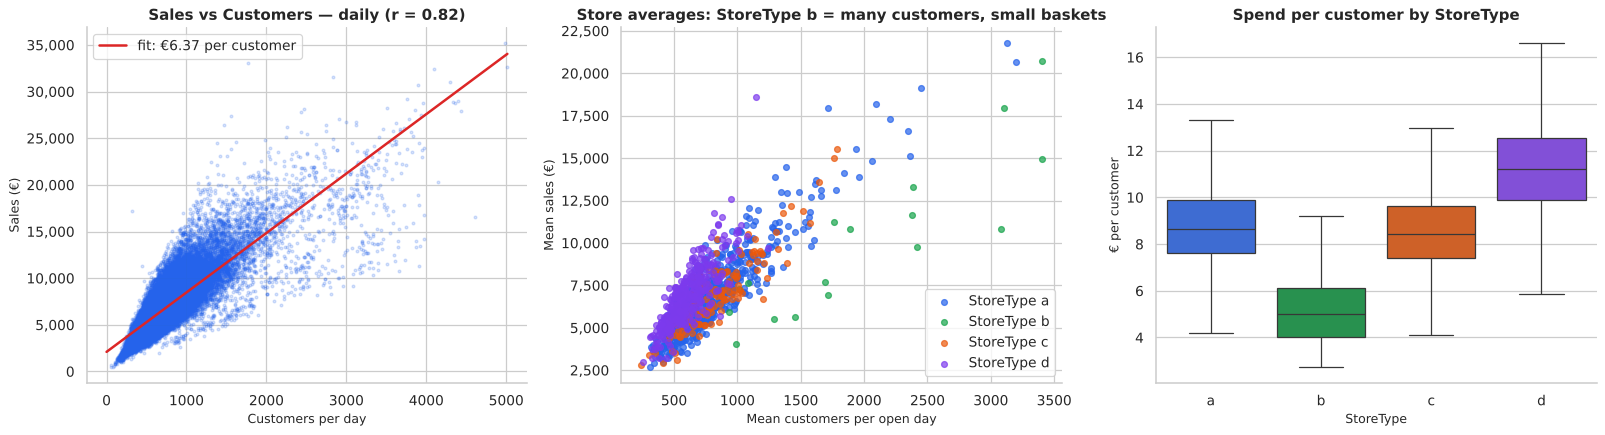

In [ ]:
log.info("Q4: sales vs customers")
r_p = op[["Sales", "Customers"]].corr().iloc[0, 1]; r_s = op[["Sales", "Customers"]].corr(method="spearman").iloc[0, 1]
slope, intercept = np.polyfit(op.Customers, op.Sales, 1)
print(f"Pearson r = {r_p:.3f} | Spearman rho = {r_s:.3f} | R² of a straight line = {r_p ** 2:.2f}")
print(f"Linear fit: Sales ≈ {intercept:,.0f} + {slope:.2f} × Customers   (≈ €{slope:.2f} per extra customer)")
by_t = op.groupby("StoreType").apply(lambda d: pd.Series({"Pearson r": d.Sales.corr(d.Customers), "Customers/day": d.Customers.mean(), "Sales/day": d.Sales.mean(), "€ per customer": d.SalesPerCustomer.mean()}))
within = op.groupby("Store").apply(lambda d: d.Sales.corr(d.Customers))
display(by_t.round(2))
print(f"Within a single store (day-to-day): mean r = {within.mean():.3f} (min {within.min():.2f}, max {within.max():.2f})")
print(f"Across stores (store averages): r = {store_lvl[['MeanSales', 'MeanCustomers']].corr().iloc[0, 1]:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
smp = op.sample(40_000, random_state=SEED)
axes[0].scatter(smp.Customers, smp.Sales, s=5, alpha=.18, color=COLORS["blue"])
xs = np.linspace(0, smp.Customers.max(), 50); axes[0].plot(xs, intercept + slope * xs, color=COLORS["red"], lw=2, label=f"fit: €{slope:.2f} per customer")
axes[0].set_title(f"Sales vs Customers — daily (r = {r_p:.2f})"); axes[0].set_xlabel("Customers per day"); axes[0].set_ylabel("Sales (€)"); thousands(axes[0]); axes[0].legend()
for t, c in zip("abcd", PALETTE):
    g = store_lvl[store_lvl.StoreType == t]; axes[1].scatter(g.MeanCustomers, g.MeanSales, s=22, alpha=.7, color=c, label=f"StoreType {t}")
axes[1].set_title("Store averages: StoreType b = many customers, small baskets"); axes[1].set_xlabel("Mean customers per open day"); axes[1].set_ylabel("Mean sales (€)"); thousands(axes[1]); axes[1].legend()
sns.boxplot(data=op, x="StoreType", y="SalesPerCustomer", hue="StoreType", order=list("abcd"), hue_order=list("abcd"), showfliers=False, palette=PALETTE[:4], legend=False, ax=axes[2])
axes[2].set_title("Spend per customer by StoreType"); axes[2].set_xlabel("StoreType"); axes[2].set_ylabel("€ per customer")
plt.tight_layout(); plt.show()

**Answer Q4 — Sales and Customers are strongly and almost linearly related.**
* Pearson **r = 0.82**, Spearman **ρ = 0.83** (R² = 0.68): customer numbers explain about two thirds of the day-to-day variation in sales; on average each extra customer is worth ≈ **€6.4** (intercept ≈ €2,100).
* Inside a **single store** the day-to-day relation is even tighter (mean r = 0.94, minimum 0.48); across store averages it is 0.83; per StoreType 0.86–0.90.
* The remaining variation is the **basket size**: StoreType `d` earns €11.3 per customer, `a` €8.9, `c` €8.6 and `b` only **€5.1** — type `b` stores attract ≈ 2,000 customers a day with small baskets (middle panel: the orange cloud lies far to the right, not higher).
* **Implication:** footfall is the main driver of sales, but it is a same-day outcome — **not available at forecast time**, so it cannot be a model input. It is, however, a good *second target* (predicted customers for the dashboard), and *historical* store customers are a legitimate, leak-safe feature (computed only from the past, section 4).

### Q5 — How do promotions affect sales? Do they attract more customers? Do they affect existing customers?
Promotions only run Monday–Friday, so the fair comparison is **promo vs non-promo weekdays**. The data has no customer identifier, so *new* and *existing* customers cannot be separated directly. We use two proxies: **Customers** (number of visits → footfall, includes new customers) and **Sales per customer** (spend per visit → how much already-present customers buy).

2026-10-30 07:01:04,359 | INFO     | src.eda | Q5: promotion effect


,Sales,Customers,SalesPerCustomer
Promo,,,
No promo,"5,928.70",705.07,8.83
Promo,"8,228.74",844.48,10.18


Promo uplift: {'Sales': '+38.8%', 'Customers': '+19.8%', 'SalesPerCustomer': '+15.3%'}
Store-level promo lift (1,115 stores):


,Sales,Customers,SalesPerCustomer
mean,+39.9%,+20.9%,+15.3%
25%,+31.2%,+15.9%,+12.6%
50%,+39.5%,+20.4%,+15.2%
75%,+47.6%,+25.2%,+17.8%
min,+1.9%,+1.4%,-0.6%
max,+102.1%,+61.5%,+32.2%


Paired Wilcoxon test (promo vs non-promo store means): p = 5.9e-184;  stores with a positive sales lift: 100.0%
Share of the log-uplift explained by MORE customers: 55%;  by HIGHER spend per customer: 45%


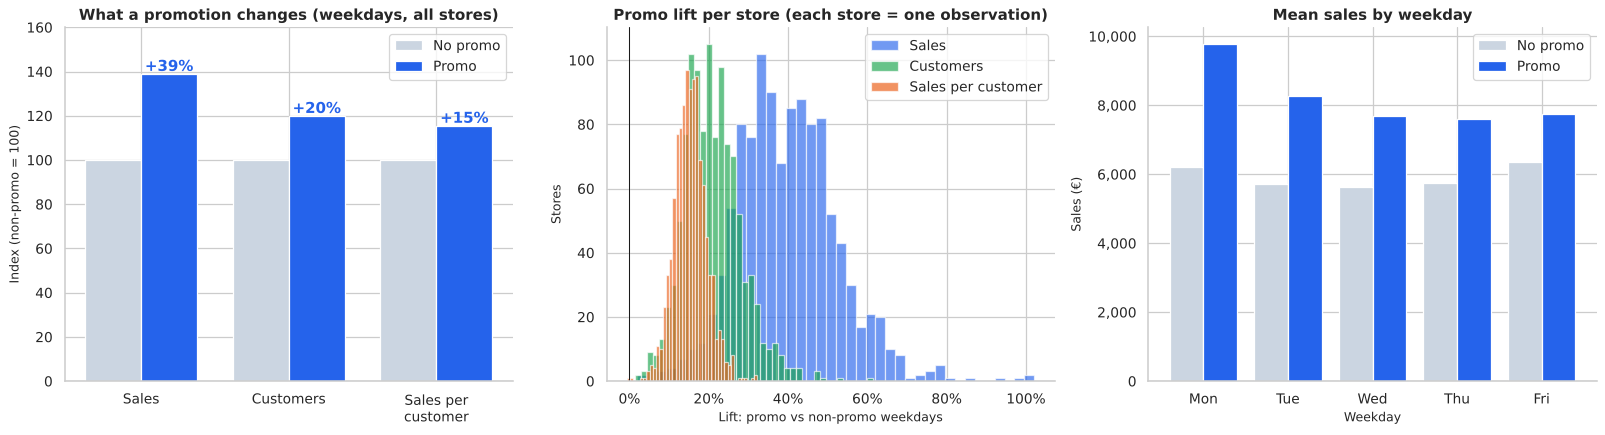

2026-10-30 07:01:05,370 | INFO     | src.visualization.plotting | Saved figure 05_promo_effect.png


,mean_sales,mean_customers,days
1st promo week (previous week had no promo),"8,232",843,"321,441"
2nd consecutive promo week,"8,211",852,"55,434"


Weeks in the data: 135 | promo weeks: 72 | back-to-back promo weeks: 11 | back-to-back NON-promo weeks: 2


In [ ]:
log.info("Q5: promotion effect")
wkd = op[op.DayOfWeek <= 5]
tab = wkd.groupby("Promo")[["Sales", "Customers", "SalesPerCustomer"]].mean()
uplift = tab.loc[1] / tab.loc[0] - 1
display(tab.rename(index={0: "No promo", 1: "Promo"}).style.format("{:,.2f}"))
print("Promo uplift:", {k: f"{v:+.1%}" for k, v in uplift.items()})

ps = wkd.groupby(["Store", "Promo"])[["Sales", "Customers", "SalesPerCustomer"]].mean().unstack()
lift = pd.DataFrame({m: ps[m][1] / ps[m][0] - 1 for m in ["Sales", "Customers", "SalesPerCustomer"]})
print("Store-level promo lift (1,115 stores):"); display(lift.describe().loc[["mean", "25%", "50%", "75%", "min", "max"]].map(lambda v: f"{v:+.1%}"))
w = stats.wilcoxon(ps["Sales"][1], ps["Sales"][0])
print(f"Paired Wilcoxon test (promo vs non-promo store means): p = {w.pvalue:.2g};  stores with a positive sales lift: {(lift.Sales > 0).mean():.1%}")
share_cust = np.log(1 + uplift["Customers"]) / np.log(1 + uplift["Sales"])
print(f"Share of the log-uplift explained by MORE customers: {share_cust:.0%};  by HIGHER spend per customer: {1 - share_cust:.0%}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
x = np.arange(3); h = .38
rel = tab / tab.loc[0]                                 # indexed to non-promo = 100
axes[0].bar(x - h / 2, rel.loc[0] * 100, h, color=COLORS["light"], label="No promo"); axes[0].bar(x + h / 2, rel.loc[1] * 100, h, color=COLORS["blue"], label="Promo")
for i, v in enumerate(rel.loc[1] * 100): axes[0].text(i + h / 2, v + 1.5, f"+{v - 100:.0f}%", ha="center", fontweight="bold", color=COLORS["blue"])
axes[0].set_xticks(x); axes[0].set_xticklabels(["Sales", "Customers", "Sales per\ncustomer"]); axes[0].set_ylim(0, 160); axes[0].set_ylabel("Index (non-promo = 100)")
axes[0].set_title("What a promotion changes (weekdays, all stores)"); axes[0].legend(loc="upper right")
for c, col in zip([COLORS["blue"], COLORS["green"], COLORS["orange"]], ["Sales", "Customers", "SalesPerCustomer"]):
    axes[1].hist(lift[col], bins=40, alpha=.65, color=c, label=col.replace("SalesPerCustomer", "Sales per customer"))
axes[1].axvline(0, color="k", lw=.8); percent(axes[1], "x"); axes[1].set_title("Promo lift per store (each store = one observation)"); axes[1].set_xlabel("Lift: promo vs non-promo weekdays"); axes[1].set_ylabel("Stores"); axes[1].legend()
pw = wkd.groupby(["DayOfWeek", "Promo"]).Sales.mean().unstack(); pw.index = [DAY_NAMES[i] for i in pw.index]; pw.columns = ["No promo", "Promo"]
pw.plot.bar(ax=axes[2], rot=0, color=[COLORS["light"], COLORS["blue"]], width=.8); thousands(axes[2]); axes[2].set_title("Mean sales by weekday"); axes[2].set_xlabel("Weekday"); axes[2].set_ylabel("Sales (€)")
plt.tight_layout(); fig_promo = fig; plt.show()
save_figure(fig_promo, "05_promo_effect", cfg)

# Do repeated promotions wear out? first vs consecutive promo week
wkly = train[train.DayOfWeek <= 5].assign(wk=lambda d: d.Date.dt.to_period("W")).groupby("wk").Promo.max()
w2 = wkd.assign(wk=wkd.Date.dt.to_period("W")); w2["prev_week_promo"] = w2.wk.map(wkly.shift(1))
fat = w2[w2.Promo == 1].groupby("prev_week_promo").agg(mean_sales=("Sales", "mean"), mean_customers=("Customers", "mean"), days=("Sales", "size"))
fat.index = ["1st promo week (previous week had no promo)", "2nd consecutive promo week"]; display(fat.style.format("{:,.0f}"))
print(f"Weeks in the data: {len(wkly)} | promo weeks: {int(wkly.sum())} | back-to-back promo weeks: {int(((wkly == 1) & (wkly.shift(1) == 1)).sum())} | back-to-back NON-promo weeks: {int(((wkly == 0) & (wkly.shift(1) == 0)).sum())}")

**Answer Q5 — promotions raise sales by ≈ 39 %, by attracting more customers *and* by raising spend per customer.**
* **Sales:** +38.8 % on promo weekdays (8,229 vs 5,929). All **1,115 stores** show a positive lift (median +39.5 %, middle half +31 % … +48 %; minimum +1.9 %, maximum +102 %).
* **Do promotions attract more customers? Yes:** +19.8 % customers (845 vs 705) — about **55 %** of the (log) uplift comes from extra visits.
* **Do they affect existing customers? Yes, they spend more per visit:** +15.3 % sales per customer (€10.18 vs €8.83), about **45 %** of the uplift. *Caveat:* the data has no customer ID, so "new" vs "existing" customers cannot be separated; "visits" (Customers) includes both, "spend per visit" is the best available proxy for the behaviour of the customers who would have come anyway.
* **Wear-out:** a second consecutive promo week sells as well as the first (8,211 vs 8,232) — but back-to-back promo weeks are very rare (11 of 135 weeks), so there is **too little evidence** to rule out fatigue.
* **Where in the week:** the lift is strongest early in the week (Mon +57 % … Fri +22 %, see interactions).
* *Caveat:* the data show sales lift, **not profit** — discount cost and margin are unknown.

#### Q5-B — Promotion lift by StoreType (sales lift, customer lift, spend lift, with sample counts)

Q5 above gives the chain-wide effect and Q6 ranks stores. This table adds, **per StoreType**, the *sales lift* **and** the *customer lift* together with the sample sizes, so that small groups are not over-interpreted. Lifts are computed on promo weekdays (Mon–Fri) vs non-promo weekdays (open days with sales). The store-level 95 % interval treats each **store** as one observation (not each day), which is the honest unit because days of the same store are not independent.

2026-10-30 07:01:05,948 | INFO     | src.eda | Q5-B: StoreType-wise promotion lift


,stores,promo_days,non_promo_days,sales_lift,customer_lift,spend_lift,store_mean_lift,ci95_low,ci95_high,reliability
StoreType,,,,,,,,,,
a,602,"204,510","173,322",+37.7%,+19.4%,+15.2%,+38.7%,+37.7%,+39.7%,ok
b,17,"5,938","5,192",+20.0%,+8.8%,+9.6%,+19.6%,+13.5%,+25.7%,small group (< 30 stores)
c,148,"50,733","42,867",+39.5%,+20.1%,+16.0%,+40.9%,+38.7%,+43.0%,ok
d,348,"115,694","98,437",+42.2%,+22.9%,+15.4%,+42.7%,+41.5%,+44.0%,ok


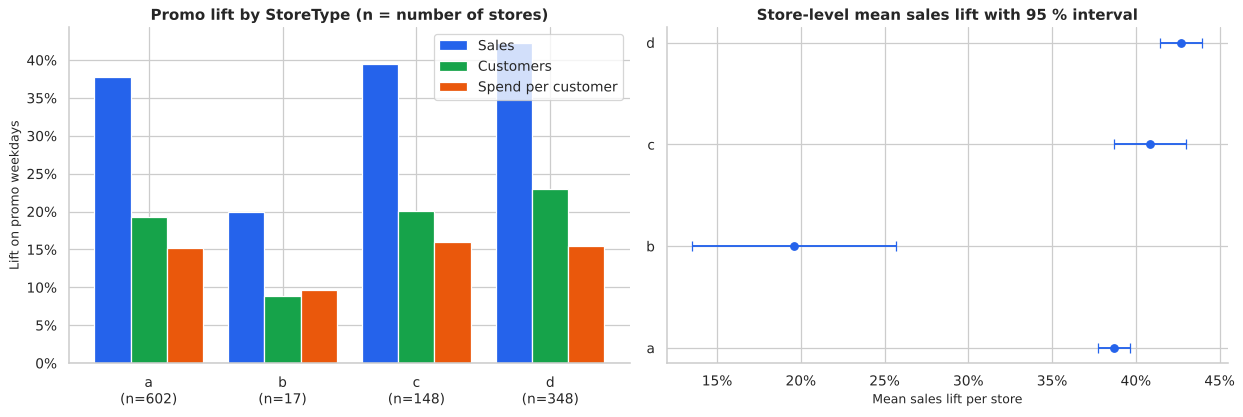

2026-10-30 07:01:06,588 | INFO     | src.visualization.plotting | Saved figure 05b_promo_by_storetype.png


Among groups with ≥ 30 stores the highest sales lift is StoreType d (+42.2%) and the lowest is a (+37.7%). Small groups (read with caution): ['b']


In [ ]:
log.info("Q5-B: StoreType-wise promotion lift")
MIN_STORES = 30                                    # groups with fewer stores are flagged, not ranked
wk = op[op.DayOfWeek <= 5]
pooled = wk.groupby(["StoreType", "Promo"], observed=True).agg(sales=("Sales", "mean"), customers=("Customers", "mean"),
                                                              spend=("SalesPerCustomer", "mean"), days=("Sales", "size")).unstack("Promo")
st_means = wk.groupby(["Store", "Promo"])[["Sales", "Customers", "SalesPerCustomer"]].mean().unstack("Promo")
st_lift = pd.DataFrame({k: st_means[k][1] / st_means[k][0] - 1 for k in ["Sales", "Customers", "SalesPerCustomer"]}).dropna()
st_lift = st_lift.join(store.set_index("Store")["StoreType"])

out_rows = []
for t, g in st_lift.groupby("StoreType", observed=True):
    n = len(g); se = g.Sales.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    out_rows.append({"StoreType": t, "stores": n,
                "promo_days": int(pooled.loc[t, ("days", 1)]), "non_promo_days": int(pooled.loc[t, ("days", 0)]),
                "sales_lift": pooled.loc[t, ("sales", 1)] / pooled.loc[t, ("sales", 0)] - 1,
                "customer_lift": pooled.loc[t, ("customers", 1)] / pooled.loc[t, ("customers", 0)] - 1,
                "spend_lift": pooled.loc[t, ("spend", 1)] / pooled.loc[t, ("spend", 0)] - 1,
                "store_mean_lift": g.Sales.mean(), "ci95_low": g.Sales.mean() - 1.96 * se, "ci95_high": g.Sales.mean() + 1.96 * se,
                "reliability": "ok" if n >= MIN_STORES else f"small group (< {MIN_STORES} stores)"})
lift_type = pd.DataFrame(out_rows).set_index("StoreType")
display(lift_type.style.format({"stores": "{:,.0f}", "promo_days": "{:,.0f}", "non_promo_days": "{:,.0f}", "sales_lift": "{:+.1%}",
                                "customer_lift": "{:+.1%}", "spend_lift": "{:+.1%}", "store_mean_lift": "{:+.1%}",
                                "ci95_low": "{:+.1%}", "ci95_high": "{:+.1%}"}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
x = np.arange(len(lift_type)); h = .27
axes[0].bar(x - h, lift_type.sales_lift, h, color=COLORS["blue"], label="Sales")
axes[0].bar(x, lift_type.customer_lift, h, color=COLORS["green"], label="Customers")
axes[0].bar(x + h, lift_type.spend_lift, h, color=COLORS["orange"], label="Spend per customer")
axes[0].set_xticks(x); axes[0].set_xticklabels([f"{t}\n(n={n})" for t, n in zip(lift_type.index, lift_type.stores)])
percent(axes[0]); axes[0].set_title("Promo lift by StoreType (n = number of stores)"); axes[0].set_ylabel("Lift on promo weekdays"); axes[0].legend()
axes[1].errorbar(lift_type.store_mean_lift, x, xerr=[lift_type.store_mean_lift - lift_type.ci95_low, lift_type.ci95_high - lift_type.store_mean_lift],
                 fmt="o", color=COLORS["blue"], capsize=4)
axes[1].set_yticks(x); axes[1].set_yticklabels(lift_type.index); percent(axes[1], "x")
axes[1].set_title("Store-level mean sales lift with 95 % interval"); axes[1].set_xlabel("Mean sales lift per store")
plt.tight_layout(); fig_b = fig; plt.show()
save_figure(fig_b, "05b_promo_by_storetype", cfg)

small = lift_type.index[lift_type.stores < MIN_STORES].tolist()
best, worst = lift_type[lift_type.stores >= MIN_STORES].sales_lift.idxmax(), lift_type[lift_type.stores >= MIN_STORES].sales_lift.idxmin()
print(f"Among groups with ≥ {MIN_STORES} stores the highest sales lift is StoreType {best} ({lift_type.loc[best, 'sales_lift']:+.1%}) "
      f"and the lowest is {worst} ({lift_type.loc[worst, 'sales_lift']:+.1%}). Small groups (read with caution): {small}")

**How to read Q5-B.**
* *What does the chart show?* For each StoreType, how much sales, customers and spend per customer rise on promo weekdays; the right panel shows the average store-level lift with a 95 % interval (a wide interval = uncertain).
* *What pattern is visible?* Compare the three bars: whether the sales lift is driven more by **extra customers** or by **higher spend per customer** can differ by StoreType. Groups marked *small group* (few stores) can look extreme by chance; their intervals are wide, so they are shown but **not ranked**.
* *Business implication?* Promotion budgets should be tested first where the lift is clearly high *and* the group is large enough; in a group with a low lift, test fewer or different promotions. Remember the lift is **association** (promotions were chain-wide, not randomised) and measures **sales, not profit**.

**Findings Q5-B (from the run on the real data)**

| StoreType | stores | sales lift | customer lift | spend lift | note |
|---|---|---|---|---|---|
| `a` | 602 | +37.7 % | +19.4 % | +15.2 % | reliable (95 % interval of store means 37.7–39.7 %) |
| `b` | 17 | +20.0 % | +8.8 % | +9.6 % | **small group**, wide interval (13.5–25.7 %) |
| `c` | 148 | +39.5 % | +20.1 % | +16.0 % | reliable |
| `d` | 348 | +42.2 % | +22.9 % | +15.4 % | reliable, highest lift |

* Every StoreType gains from promotions; the **weakest response is `b`** (+20 %), consistent with Q6, but with only 17 stores it is a hypothesis to test, not a proven rule.
* Among the reliable groups `d` (+42 %) is a few points above `a` (+38 %); the difference is real but modest. In all types roughly half of the sales lift comes from extra customers and half from higher spend per customer.
* Association only: promotions were chain-wide and not randomised.

### Q6 — Could promotions be deployed more effectively? Where do they work best / worst?
We measure the **promo lift per store** (promo vs non-promo weekdays) and compare it across store groups. A low lift means the promotion buys little extra sales; a high lift means the store reacts strongly.

2026-10-30 07:01:06,615 | INFO     | src.eda | Q6: promotion effectiveness


segment,group,stores,mean_lift,median_lift,extra_sales_per_promo_day
StoreType,a,602,38.7%,37.0%,"€2,265"
StoreType,b,17,19.6%,13.6%,"€1,857"
StoreType,c,148,40.9%,40.5%,"€2,265"
StoreType,d,348,42.7%,42.2%,"€2,371"
Assortment,Basic,593,42.1%,41.8%,"€2,287"
Assortment,Extended,513,38.0%,36.6%,"€2,322"
Assortment,Extra,9,11.1%,11.4%,€916
Promo2,Not participating,544,36.7%,35.5%,"€2,256"
Promo2,Participating,571,43.1%,42.3%,"€2,325"
StoreSize,small stores,372,43.0%,42.4%,"€1,733"


Kruskal-Wallis, lift differs between StoreTypes?  p = 3.7e-11
Spearman(store size, lift) = -0.217 | Promo2 vs non-Promo2 lift p = 1.4e-16


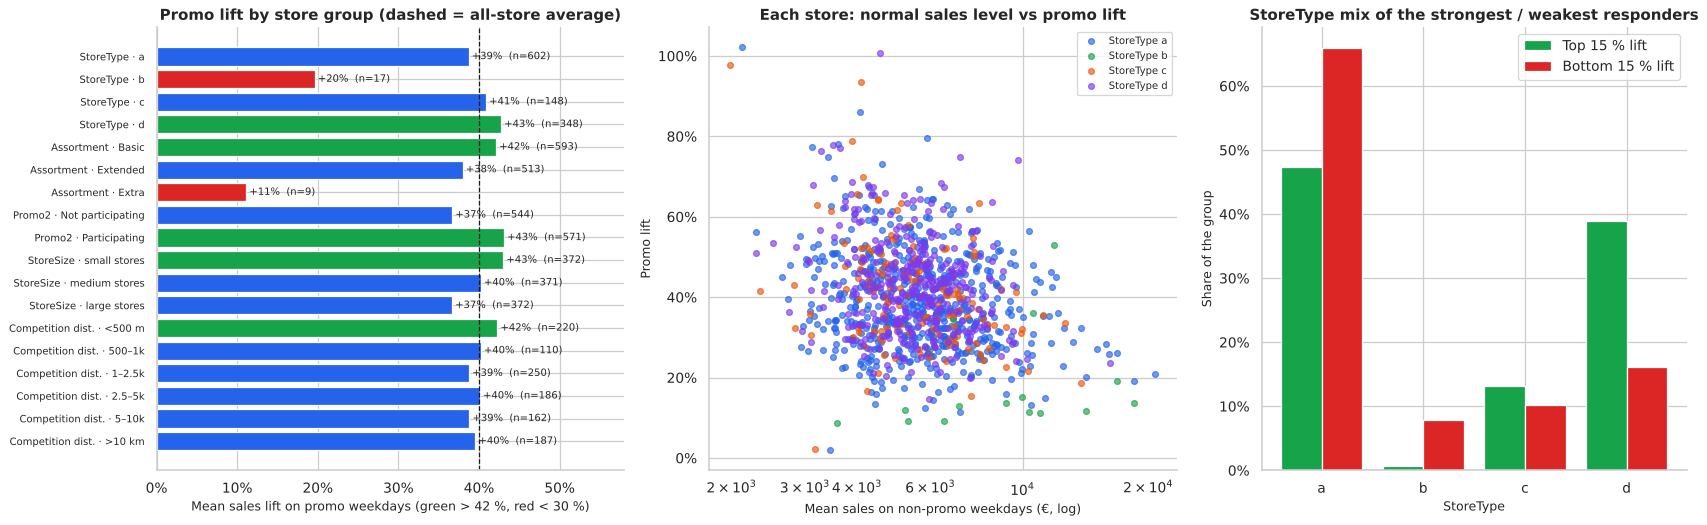

2026-10-30 07:01:07,695 | INFO     | src.visualization.plotting | Saved figure 06_promo_effectiveness.png


**10 stores with the weakest promo response**

,lift,lift_customers,lift_basket,base_sales,extra_sales_per_promo_day,StoreType,Assortment,Promo2
Store,,,,,,,,
789,1.9%,2.5%,-0.6%,"3,456",67,a,Extended,Not participating
794,2.3%,1.4%,0.9%,"3,170",73,c,Extended,Not participating
274,8.7%,2.9%,5.7%,"3,580",312,b,Extra,Participating
948,9.3%,5.4%,3.1%,"6,471",601,b,Extra,Not participating
353,9.3%,4.2%,4.5%,"5,306",494,b,Extra,Participating
259,11.2%,4.8%,5.7%,"10,983","1,229",b,Extra,Not participating
769,11.4%,6.3%,4.3%,"10,345","1,177",b,Extra,Participating
760,11.4%,4.5%,6.6%,"7,052",807,a,Basic,Not participating
733,11.6%,5.2%,5.9%,"14,192","1,652",b,Extra,Not participating


**10 stores with the strongest promo response**

,lift,lift_customers,lift_basket,base_sales,extra_sales_per_promo_day,StoreType,Assortment,Promo2
Store,,,,,,,,
198,102.1%,52.5%,31.5%,"2,125","2,170",a,Basic,Participating
693,100.8%,61.5%,23.7%,"4,536","4,572",d,Basic,Participating
543,97.6%,48.8%,32.2%,"1,987","1,939",c,Basic,Not participating
636,93.5%,47.0%,30.6%,"4,086","3,820",c,Basic,Participating
575,86.2%,47.3%,25.2%,"4,075","3,511",a,Basic,Participating
552,79.6%,38.0%,29.3%,"5,881","4,684",a,Basic,Participating
21,78.8%,43.0%,24.8%,"3,897","3,072",c,Extended,Participating
977,78.0%,40.5%,25.7%,"3,596","2,806",a,Basic,Participating
793,77.8%,43.3%,23.3%,"3,497","2,719",d,Basic,Not participating


Stores with promo lift < 20 %: 40 | > 60 %: 71 | share of stores whose lift is within 30–50 %: 60%


In [ ]:
log.info("Q6: promotion effectiveness")
L = pd.DataFrame({"lift": lift.Sales, "lift_customers": lift.Customers, "lift_basket": lift.SalesPerCustomer,
                  "base_sales": ps["Sales"][0], "promo_sales": ps["Sales"][1]}).join(store.set_index("Store")[["StoreType", "Assortment", "Promo2", "CompetitionDistance"]])
L["extra_sales_per_promo_day"] = L.promo_sales - L.base_sales
L["Assortment"] = L.Assortment.map(ASSORTMENT_LABELS); L["Promo2"] = L.Promo2.map(PROMO2_LABELS)
L["StoreSize"] = pd.qcut(L.base_sales, 3, labels=["small stores", "medium stores", "large stores"])
L["CompetitionDistance_band"] = pd.cut(L.CompetitionDistance, [0, 500, 1000, 2500, 5000, 10000, 1e6], labels=["<500 m", "500–1k", "1–2.5k", "2.5–5k", "5–10k", ">10 km"])

segs = ["StoreType", "Assortment", "Promo2", "StoreSize", "CompetitionDistance_band"]
parts = []
for sg in segs:
    g = (L.groupby(sg, observed=True).agg(stores=("lift", "size"), mean_lift=("lift", "mean"), median_lift=("lift", "median"),
                                          extra_sales_per_promo_day=("extra_sales_per_promo_day", "mean"))
         .reset_index().rename(columns={sg: "group"}))
    g.insert(0, "segment", sg); parts.append(g)
tbl = pd.concat(parts, ignore_index=True); tbl["group"] = tbl["group"].astype(str)
display(tbl.style.format({"mean_lift": "{:.1%}", "median_lift": "{:.1%}", "extra_sales_per_promo_day": "€{:,.0f}"}).hide(axis="index"))
print("Kruskal-Wallis, lift differs between StoreTypes?  p =", f"{stats.kruskal(*[g.lift.values for _, g in L.groupby('StoreType')]).pvalue:.2g}")
print("Spearman(store size, lift) =", round(stats.spearmanr(L.base_sales, L.lift)[0], 3), "| Promo2 vs non-Promo2 lift p =", f"{stats.mannwhitneyu(L[L.Promo2 == 'Participating'].lift, L[L.Promo2 != 'Participating'].lift).pvalue:.2g}")

fig, axes = plt.subplots(1, 3, figsize=(19, 6), gridspec_kw={"width_ratios": [1.1, 1.1, 1]})
plot_tbl = tbl.copy(); plot_tbl["label"] = plot_tbl.segment.str.replace("_band", "").str.replace("CompetitionDistance", "Competition dist.") + " · " + plot_tbl.group
plot_tbl = plot_tbl.iloc[::-1]
cols = plot_tbl.mean_lift.apply(lambda v: COLORS["red"] if v < .30 else (COLORS["green"] if v > .42 else COLORS["blue"]))
axes[0].barh(plot_tbl.label, plot_tbl.mean_lift, color=cols); axes[0].axvline(L.lift.mean(), color="k", ls="--", lw=1)
for y, (v, n) in enumerate(zip(plot_tbl.mean_lift, plot_tbl.stores)): axes[0].text(v + .004, y, f"{v:+.0%}  (n={n})", va="center", fontsize=8)
percent(axes[0], "x"); axes[0].set_xlim(0, .58); axes[0].set_title("Promo lift by store group (dashed = all-store average)"); axes[0].set_xlabel("Mean sales lift on promo weekdays (green > 42 %, red < 30 %)"); axes[0].tick_params(axis="y", labelsize=8)
for t, c in zip("abcd", PALETTE):
    g = L[L.StoreType == t]; axes[1].scatter(g.base_sales, g.lift, s=22, alpha=.65, color=c, label=f"StoreType {t}")
axes[1].set_xscale("log"); percent(axes[1]); axes[1].set_title("Each store: normal sales level vs promo lift"); axes[1].set_xlabel("Mean sales on non-promo weekdays (€, log)"); axes[1].set_ylabel("Promo lift"); axes[1].legend(fontsize=8)
for lab, g, c in [("Top 15 % lift", L.nlargest(int(.15 * len(L)), "lift"), COLORS["green"]), ("Bottom 15 % lift", L.nsmallest(int(.15 * len(L)), "lift"), COLORS["red"])]:
    mix = g.StoreType.value_counts(normalize=True).reindex(list("abcd")).fillna(0)
    axes[2].bar(np.arange(4) + (0 if "Top" in lab else .4), mix.values, .4, color=c, label=lab)
axes[2].set_xticks(np.arange(4) + .2); axes[2].set_xticklabels(list("abcd")); percent(axes[2]); axes[2].set_title("StoreType mix of the strongest / weakest responders"); axes[2].set_xlabel("StoreType"); axes[2].set_ylabel("Share of the group"); axes[2].legend()
plt.tight_layout(); fig_seg = fig; plt.show()
save_figure(fig_seg, "06_promo_effectiveness", cfg)

cols = ["lift", "lift_customers", "lift_basket", "base_sales", "extra_sales_per_promo_day", "StoreType", "Assortment", "Promo2"]
display(Markdown("**10 stores with the weakest promo response**")); display(L.nsmallest(10, "lift")[cols].style.format({"lift": "{:.1%}", "lift_customers": "{:.1%}", "lift_basket": "{:.1%}", "base_sales": "{:,.0f}", "extra_sales_per_promo_day": "{:,.0f}"}))
display(Markdown("**10 stores with the strongest promo response**")); display(L.nlargest(10, "lift")[cols].style.format({"lift": "{:.1%}", "lift_customers": "{:.1%}", "lift_basket": "{:.1%}", "base_sales": "{:,.0f}", "extra_sales_per_promo_day": "{:,.0f}"}))
print(f"Stores with promo lift < 20 %: {(L.lift < .2).sum()} | > 60 %: {(L.lift > .6).sum()} | share of stores whose lift is within 30–50 %: {L.lift.between(.3, .5).mean():.0%}")

**Answer Q6 — yes, the effect of promotions differs a lot between stores; blanket promotions are not equally effective everywhere.**
* **Typical store:** 60 % of the stores have a lift between 30 % and 50 %. But **40 stores gain less than 20 %** while **71 stores gain more than 60 %**.
* **Weak responders (consider fewer / different promotions, test first):** StoreType **`b`** (mean lift +20 %, 17 stores) and **Extra assortment** (+11 %, 9 stores — the same big, high-footfall stores; a promo day adds only ≈ €900 on average for Extra assortment, ≈ €1,860 for type `b`) plus a few isolated stores (e.g. 789, 794 with ≈ +2 %). In the bottom 15 %, type `b` is over-represented.
* **Strong responders:** StoreType **`d` (+43 %)**, **small stores (+43 % vs +37 % for the largest third; ρ(size, lift) = −0.22)**, **Promo2 participants (+43 % vs +37 %, p < 0.001)**, basic assortment (+42 %). Stores 198, 693, 543, 636 and 575 gain 86–102 %.
* **Not a driver:** competition distance — lift is 39–42 % in every distance band.
* **Two ways to read "effective":** in **percent**, small stores respond most; in **euros per promo day**, large stores gain most (≈ +€2,900 vs +€1,700 for small stores). A promotion budget should be steered by *margin per extra euro*, which this dataset does not contain.
* **Recommendation (hypotheses to validate with an A/B test, because promotions are chain-wide and observational):** (1) reduce or replace promotions in StoreType `b` / Extra-assortment stores; (2) prefer promo days early in the week (Mon–Thu) over Friday; (3) keep promotions for the high-lift groups (type `d`, small stores, Promo2 stores).

### Q7 — Customer behaviour when stores are **open** vs **closed** (and around closures)
A closed day has 0 customers by definition, so the interesting questions are: *when* are stores closed, and *how do customers behave right before and after closures*?

2026-10-30 07:01:07,741 | INFO     | src.eda | Q7: open / closed behaviour


Customers on closed days → max = 0 | Sales on closed days → max = 0


,closed store-days,share
reason,,
Sunday,"140,830",81.5%
State holiday,"30,140",17.4%
Other (e.g. refurbishment),"1,847",1.1%


'Other' closures: 1,847 store-days in 189 stores. Stores open on Sundays: 33


Closures of ≥ 7 consecutive days: 85 episodes in 82 stores (median 14 days, longest 185 days)


week,-4,-3,-2,-1,0,1,2,3,4,5,6,7,8
mean,1.02,1.00,1.06,0.93,1.50,1.24,1.14,1.12,1.15,1.15,1.13,1.15,1.15
median,1.01,0.99,1.02,0.97,1.34,1.16,1.04,1.04,1.04,1.05,1.04,1.04,1.04
count,75.00,75.00,75.00,79.00,79.00,79.00,78.00,78.00,78.00,77.00,77.00,77.00,77.00


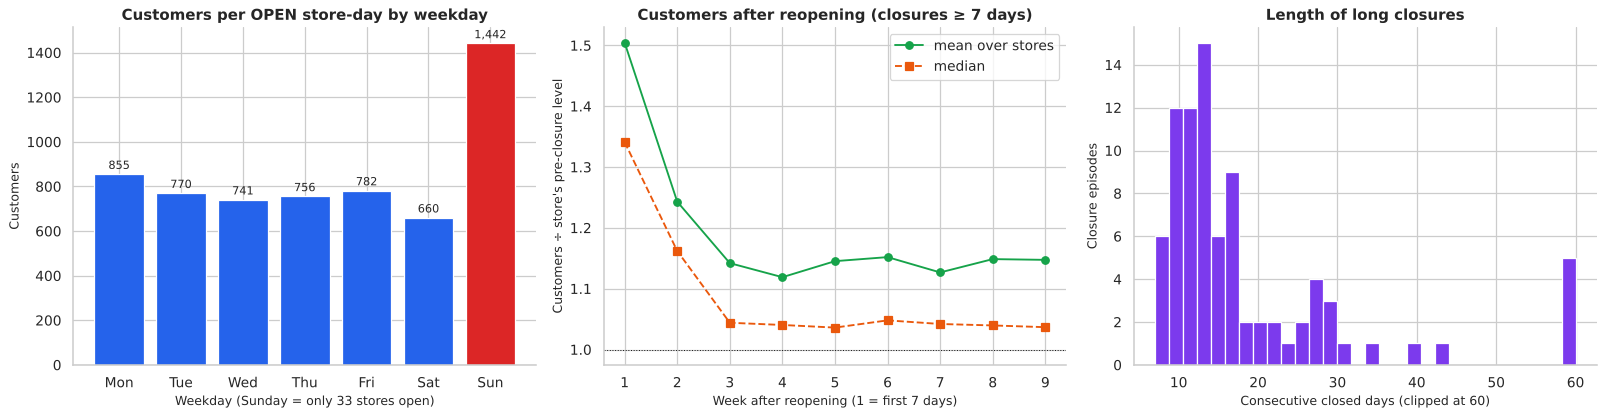

Customers on the day after a non-Sunday closure: 819 vs 742 on other days (excluding Mondays) → +10.4%
Monday (after the Sunday closure): 855 customers vs Tuesday–Friday average 762 → +12.3%
Data gap (rows missing, NOT Open = 0): 180 stores have no rows between 2014-07-01 and 2014-12-31


In [ ]:
log.info("Q7: open / closed behaviour")
closed = train[train.Open == 0].copy()
closed["reason"] = np.where(closed.StateHoliday != "0", "State holiday", np.where(closed.DayOfWeek == 7, "Sunday", "Other (e.g. refurbishment)"))
print("Customers on closed days → max =", closed.Customers.max(), "| Sales on closed days → max =", closed.Sales.max())
display(closed.reason.value_counts().to_frame("closed store-days").assign(share=lambda d: d["closed store-days"] / len(closed)).style.format({"closed store-days": "{:,.0f}", "share": "{:.1%}"}))
oth = closed[closed.reason.str.startswith("Other")]
print(f"'Other' closures: {len(oth):,} store-days in {oth.Store.nunique()} stores. Stores open on Sundays: {train[(train.DayOfWeek == 7) & (train.Open == 1)].Store.nunique()}")

# closure episodes: runs of consecutive closed days per store
t = train.sort_values(["Store", "Date"]).copy()
t["run"] = (t.Open != t.groupby("Store").Open.shift()).groupby(t.Store).cumsum()
runs = t.groupby(["Store", "run"]).agg(open=("Open", "first"), start=("Date", "min"), end=("Date", "max"), n=("Date", "size")).reset_index()
long_cl = runs[(runs.open == 0) & (runs.n >= 7)]
print(f"Closures of ≥ 7 consecutive days: {len(long_cl)} episodes in {long_cl.Store.nunique()} stores (median {long_cl.n.median():.0f} days, longest {long_cl.n.max()} days)")

by_store = {s: g for s, g in train[train.Open == 1].groupby("Store")}
rows = []
for r in long_cl.itertuples():
    g = by_store.get(r.Store)
    if g is None: continue
    pre = g[(g.Date < r.start) & (g.Date >= r.start - pd.Timedelta(days=28))].Customers.mean()
    if not pre > 0: continue
    for wk_ in range(-4, 9):
        a = r.end + pd.Timedelta(days=1 + 7 * wk_) if wk_ >= 0 else r.start + pd.Timedelta(days=7 * wk_)
        win = g[(g.Date >= a) & (g.Date < a + pd.Timedelta(days=7))]
        if len(win) >= 3: rows.append((r.Store, wk_, win.Customers.mean() / pre))
ev = pd.DataFrame(rows, columns=["Store", "week", "ratio"]); curve = ev.groupby("week").ratio.agg(["mean", "median", "count"])
display(curve.T.style.format("{:.2f}"))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
cpd = op.groupby("DayOfWeek").Customers.mean(); axes[0].bar([DAY_NAMES[d] for d in cpd.index], cpd.values, color=[COLORS["red"] if d == 7 else COLORS["blue"] for d in cpd.index]); label_bars(axes[0])
axes[0].set_title("Customers per OPEN store-day by weekday"); axes[0].set_ylabel("Customers"); axes[0].set_xlabel("Weekday (Sunday = only 33 stores open)")
post_w = curve.loc[0:]
axes[1].plot(post_w.index + 1, post_w["mean"], marker="o", color=COLORS["green"], label="mean over stores")
axes[1].plot(post_w.index + 1, post_w["median"], marker="s", color=COLORS["orange"], ls="--", label="median")
axes[1].axhline(1, color="k", lw=.8, ls=":"); axes[1].set_title("Customers after reopening (closures ≥ 7 days)"); axes[1].set_xlabel("Week after reopening (1 = first 7 days)"); axes[1].set_ylabel("Customers ÷ store's pre-closure level"); axes[1].legend()
axes[2].hist(long_cl.n.clip(upper=60), bins=30, color=COLORS["purple"]); axes[2].set_title("Length of long closures"); axes[2].set_xlabel("Consecutive closed days (clipped at 60)"); axes[2].set_ylabel("Closure episodes")
plt.tight_layout(); plt.show()

# day after a (non-Sunday) closure vs a normal day
t["prev_closed"] = (t.groupby("Store").Open.shift() == 0) & (t.groupby("Store").DayOfWeek.shift() != 7) & (t.DayOfWeek != 1)
a_ = t[(t.Open == 1) & (t.Sales > 0)]
print(f"Customers on the day after a non-Sunday closure: {a_[a_.prev_closed].Customers.mean():,.0f} vs {a_[~a_.prev_closed & (a_.DayOfWeek != 1)].Customers.mean():,.0f} on other days (excluding Mondays) → {a_[a_.prev_closed].Customers.mean() / a_[~a_.prev_closed & (a_.DayOfWeek != 1)].Customers.mean() - 1:+.1%}")
print(f"Monday (after the Sunday closure): {cpd.loc[1]:,.0f} customers vs Tuesday–Friday average {cpd.loc[2:5].mean():,.0f} → {cpd.loc[1] / cpd.loc[2:5].mean() - 1:+.1%}")
gap = train.groupby("Store").size(); print(f"Data gap (rows missing, NOT Open = 0): {int((gap < 800).sum())} stores have no rows between 2014-07-01 and 2014-12-31")

**Answer Q7 — closed stores have no customers by definition; the informative part is *why* stores close and how customers react afterwards.**
* **Closures:** 172,817 closed store-days (17 %): **81.5 % Sundays**, **17.4 % state holidays**, and **1.1 % "other"** (1,847 store-days in 189 stores — temporary closures such as refurbishment). Sales and customers are always exactly 0 when closed.
* **Sundays:** only 33 stores open on Sundays (17 of them StoreType `b`); they serve ≈ 1,440 customers on a Sunday.
* **After long closures (≥ 7 days; 85 episodes in 82 stores, median 14 days, longest 185 days) customers come back strongly:** in the first week after reopening customers are **+50 % (mean) / +34 % (median)** above the store's pre-closure level, +24 % / +16 % in week 2, and settle ≈ +12–15 % (mean) / +4 % (median) above the old level in the following weeks. Just before a closure customers dip slightly (0.93 in the last week).
* **Short closures:** the day after a non-Sunday closure has **+10 % more customers** (819 vs 742) and Monday (after the Sunday closure) **+12 %** more than Tue–Fri (855 vs 762) → demand is largely *postponed*, not lost.
* **Data gap ≠ closure:** 180 stores have no rows between July and December 2014 (no `Open = 0` flag) — missing data, not closed stores.
* **Implication:** the day after any closure and the first weeks after reopening need their own features (`DaysSinceLastHoliday`, a "days since last closure" feature is a good Part 2 addition); forecasts for `Open = 0` days are exactly 0.

### Q8 — Which stores are open on all weekdays? How does that affect weekend sales?
**Definition.** A store is *open all weekdays* if it was open on **every** non-holiday Monday–Friday it has data for. Stores with temporary closures (e.g. refurbishment) or regular weekday closures fall in the other group.

2026-10-30 07:01:11,430 | INFO     | src.eda | Q8: stores open all weekdays


Stores open on EVERY non-holiday weekday: 927 of 1115 (83.1%) | not always open: 188
Open rate of the 'not always open' stores: {'min': 0.805, '50%': 0.995, 'max': 0.998}


,stores,weekday_sales,saturday_sales,sunday_sales,sunday_stores,sat_to_weekday
AllWeekdaysOpen,,,,,,
Closed on some weekdays,188,"7,265","5,756","8,528",7,0.78
Open all weekdays,927,"7,131","5,915","6,932",26,0.83


Saturday sales, store means: Mann-Whitney p = 0.19 (≥ 0.05 → no clear difference)
Share of Saturdays the store is open → {'other': '98.6%', 'all weekdays': '99.7%'}
Stores that open on Sundays: 33 (open all weekdays: 26) | StoreTypes: {'b': 17, 'a': 13, 'd': 3}


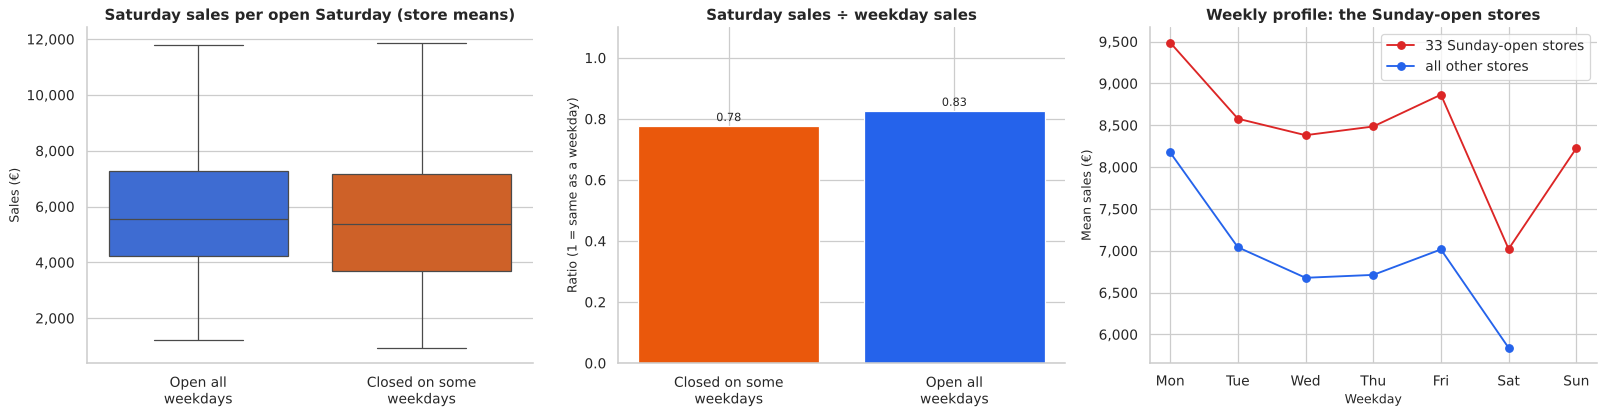

In [ ]:
log.info("Q8: stores open all weekdays")
nh = train[(train.DayOfWeek <= 5) & (train.StateHoliday == "0")]
open_rate = nh.groupby("Store").Open.mean()
all_open = open_rate[open_rate == 1].index
print(f"Stores open on EVERY non-holiday weekday: {len(all_open)} of {len(open_rate)} ({len(all_open) / len(open_rate):.1%}) | not always open: {len(open_rate) - len(all_open)}")
print("Open rate of the 'not always open' stores:", open_rate[open_rate < 1].describe().round(3)[["min", "50%", "max"]].to_dict())
op["AllWeekdaysOpen"] = op.Store.isin(all_open); op["Group"] = np.where(op.AllWeekdaysOpen, "Open all weekdays", "Closed on some weekdays")
store_lvl["AllWeekdaysOpen"] = store_lvl.index.isin(all_open)

kind = np.select([op.DayOfWeek <= 5, op.DayOfWeek == 6], ["weekday", "Saturday"], "Sunday")
sk = op.assign(kind=kind).groupby(["Store", "kind"]).Sales.mean().unstack()
sk["AllWeekdaysOpen"] = sk.index.isin(all_open); sk["sat_to_weekday"] = sk.Saturday / sk.weekday
summ = sk.groupby("AllWeekdaysOpen").agg(stores=("weekday", "size"), weekday_sales=("weekday", "mean"), saturday_sales=("Saturday", "mean"), sunday_sales=("Sunday", "mean"),
                                         sunday_stores=("Sunday", "count"), sat_to_weekday=("sat_to_weekday", "mean"))
display(summ.rename(index={True: "Open all weekdays", False: "Closed on some weekdays"}).style.format({"weekday_sales": "{:,.0f}", "saturday_sales": "{:,.0f}", "sunday_sales": "{:,.0f}", "sat_to_weekday": "{:.2f}"}))
mw = stats.mannwhitneyu(sk[sk.AllWeekdaysOpen].Saturday.dropna(), sk[~sk.AllWeekdaysOpen].Saturday.dropna())
print(f"Saturday sales, store means: Mann-Whitney p = {mw.pvalue:.2f} (≥ 0.05 → no clear difference)")
sat_open = train[train.DayOfWeek == 6].groupby(train.Store.isin(all_open)).Open.mean()
print("Share of Saturdays the store is open →", {("all weekdays" if k else "other"): f"{v:.1%}" for k, v in sat_open.items()})
sun_st = train[(train.DayOfWeek == 7) & (train.Open == 1)].Store.unique()
print(f"Stores that open on Sundays: {len(sun_st)} (open all weekdays: {len(set(sun_st) & set(all_open))}) | StoreTypes: {store[store.Store.isin(sun_st)].StoreType.value_counts().to_dict()}")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
sns.boxplot(data=sk.reset_index().assign(Group=lambda d: np.where(d.AllWeekdaysOpen, "Open all\nweekdays", "Closed on some\nweekdays")), x="Group", y="Saturday", hue="Group", showfliers=False, palette=[COLORS["blue"], COLORS["orange"]], legend=False, ax=axes[0])
axes[0].set_title("Saturday sales per open Saturday (store means)"); axes[0].set_xlabel(""); axes[0].set_ylabel("Sales (€)"); thousands(axes[0])
r = sk.groupby("AllWeekdaysOpen").sat_to_weekday.mean(); axes[1].bar(["Closed on some\nweekdays", "Open all\nweekdays"], [r[False], r[True]], color=[COLORS["orange"], COLORS["blue"]]); label_bars(axes[1], "{:.2f}")
axes[1].set_title("Saturday sales ÷ weekday sales"); axes[1].set_ylabel("Ratio (1 = same as a weekday)"); axes[1].set_ylim(0, 1.1)
ss = op[op.Store.isin(sun_st)].groupby("DayOfWeek").Sales.mean(); sn = op[~op.Store.isin(sun_st)].groupby("DayOfWeek").Sales.mean()
axes[2].plot([DAY_NAMES[d] for d in ss.index], ss.values, marker="o", color=COLORS["red"], label=f"{len(sun_st)} Sunday-open stores"); axes[2].plot([DAY_NAMES[d] for d in sn.index[:6]], sn.values[:6], marker="o", color=COLORS["blue"], label="all other stores")
thousands(axes[2]); axes[2].set_title("Weekly profile: the Sunday-open stores"); axes[2].set_ylabel("Mean sales (€)"); axes[2].set_xlabel("Weekday"); axes[2].legend()
plt.tight_layout(); plt.show()

**Answer Q8 — 927 stores (83 %) are open on every non-holiday weekday; being open all weekdays does *not* noticeably change weekend sales.**
* **Stores open all weekdays:** 927 of 1,115; the other 188 had at least one weekday closure (open rate 80.5 %–99.8 %, median 99.5 % — mostly short refurbishment closures).
* **Saturday:** stores open all weekdays sell 5,915 on Saturdays vs 5,756 for the others (+2.8 %); the store-level difference is **not statistically significant (Mann-Whitney p = 0.19)**. Saturday is ≈ **17–22 % weaker than a weekday** in both groups (ratio 0.83 vs 0.78), and nearly all stores open on Saturdays (99.7 % vs 98.6 % of Saturdays).
* **Sunday:** the weekend is shaped by the **Sunday-trading policy**, not by weekday opening: only 33 stores open on Sundays (26 of them also open every weekday; 17 are StoreType `b`). Their Sunday sales (≈ 8,200) are comparable to their weekday level (≈ 8,800) and far above Saturday.
* **Implication:** `AllWeekdaysOpen` is not a strong feature; the **day-level `Open` flag** and the *Sunday-open* store group (≈ StoreType `b`) matter more.

### Q9 — Effect of assortment type (`a` = basic, `b` = extra, `c` = extended) on sales

2026-10-30 07:01:12,656 | INFO     | src.eda | Q9: assortment


,stores,store_days,sales,customers,sales_per_customer
AssortmentLabel,,,,,
Basic,593,"444,875","6,622",748,9.13
Extra,9,"8,209","8,643","2,068",4.16
Extended,513,"391,254","7,301",752,10.02


**Number of stores per StoreType × Assortment** (assortment is not independent of store type)

Assortment,Basic,Extra,Extended
StoreType,,,
a,381,0,221
b,7,9,1
c,77,0,71
d,128,0,220


Kruskal-Wallis on store mean sales across the 3 assortments: p = 1.5e-07


**Like-for-like: basic vs extended inside the same StoreType**

,basic stores,extended stores,basic mean sales,extended mean sales,extended vs basic,Mann-Whitney p
StoreType,,,,,,
a,381,221,"6,527","7,578",+16.1%,0.000
c,77,71,"6,833","7,010",+2.6%,0.736
d,128,220,"6,424","7,056",+9.8%,0.002


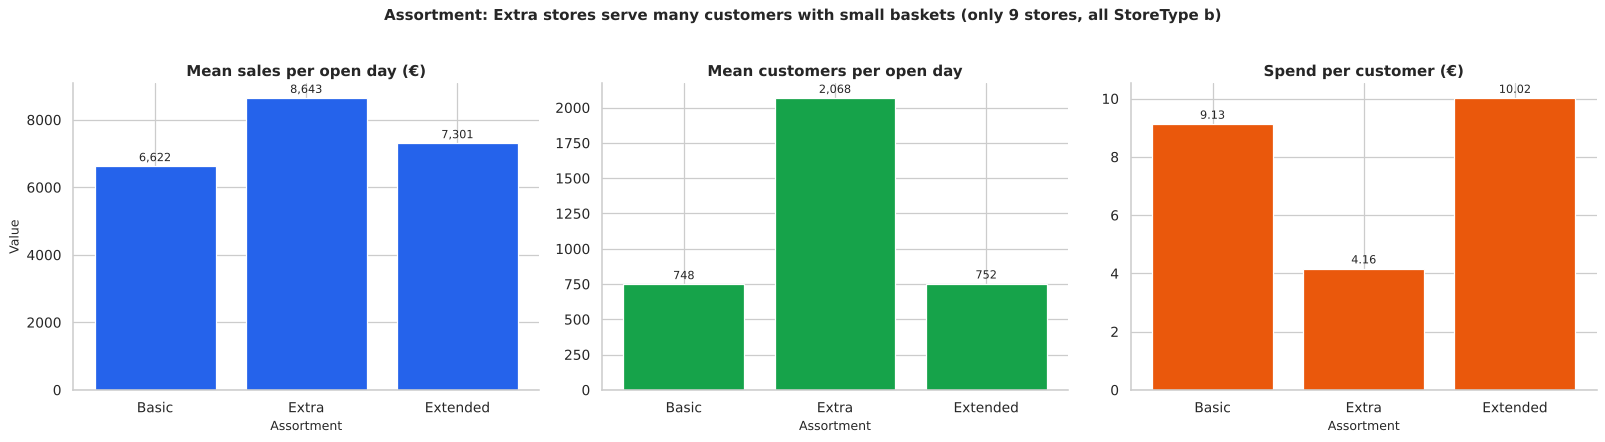

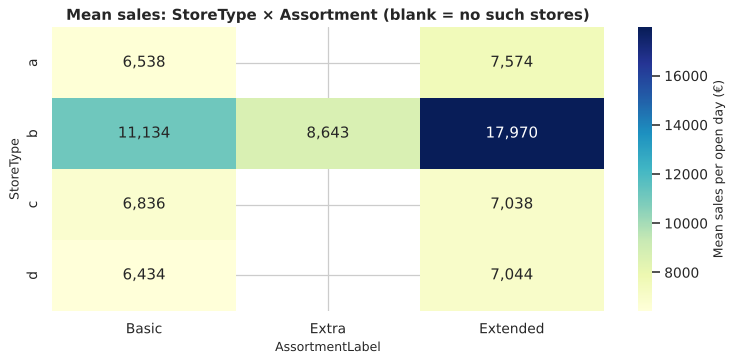

In [ ]:
log.info("Q9: assortment")
op["AssortmentLabel"] = op.Assortment.map(ASSORTMENT_LABELS)
ta = op.groupby("AssortmentLabel").agg(stores=("Store", "nunique"), store_days=("Sales", "size"), sales=("Sales", "mean"), customers=("Customers", "mean"), sales_per_customer=("SalesPerCustomer", "mean")).reindex(["Basic", "Extra", "Extended"])
display(ta.style.format({"store_days": "{:,.0f}", "sales": "{:,.0f}", "customers": "{:,.0f}", "sales_per_customer": "{:.2f}"}))
cross = store.groupby(["StoreType", "Assortment"]).size().unstack(fill_value=0).rename(columns=ASSORTMENT_LABELS)
display(Markdown("**Number of stores per StoreType × Assortment** (assortment is not independent of store type)")); display(cross)

sm = store_lvl.assign(AssortmentLabel=store_lvl.Assortment.map(ASSORTMENT_LABELS))
kw = stats.kruskal(*[g.MeanSales.values for _, g in sm.groupby("AssortmentLabel")])
print(f"Kruskal-Wallis on store mean sales across the 3 assortments: p = {kw.pvalue:.2g}")
within = []
for t in "acd":
    g = sm[sm.StoreType == t]; b_, e_ = g[g.Assortment == "a"].MeanSales, g[g.Assortment == "c"].MeanSales
    within.append({"StoreType": t, "basic stores": len(b_), "extended stores": len(e_), "basic mean sales": b_.mean(), "extended mean sales": e_.mean(),
                   "extended vs basic": e_.mean() / b_.mean() - 1, "Mann-Whitney p": stats.mannwhitneyu(b_, e_).pvalue})
display(Markdown("**Like-for-like: basic vs extended inside the same StoreType**")); display(pd.DataFrame(within).set_index("StoreType").style.format({"basic mean sales": "{:,.0f}", "extended mean sales": "{:,.0f}", "extended vs basic": "{:+.1%}", "Mann-Whitney p": "{:.3f}"}))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
for ax, col, title, f, c in zip(axes, ["sales", "customers", "sales_per_customer"], ["Mean sales per open day (€)", "Mean customers per open day", "Spend per customer (€)"], ["{:,.0f}", "{:,.0f}", "{:.2f}"], [COLORS["blue"], COLORS["green"], COLORS["orange"]]):
    ax.bar(ta.index, ta[col], color=c); label_bars(ax, f); ax.set_title(title); ax.set_xlabel("Assortment")
axes[0].set_ylabel("Value")
plt.suptitle("Assortment: Extra stores serve many customers with small baskets (only 9 stores, all StoreType b)", y=1.02, fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
hm = op.groupby(["StoreType", "AssortmentLabel"]).Sales.mean().unstack()[["Basic", "Extra", "Extended"]]
sns.heatmap(hm, annot=True, fmt=",.0f", cmap="YlGnBu", cbar_kws={"label": "Mean sales per open day (€)"}, ax=ax); ax.set_title("Mean sales: StoreType × Assortment (blank = no such stores)"); ax.set_ylabel("StoreType")
plt.tight_layout(); plt.show()

**Answer Q9 — a broader assortment goes together with higher sales, but the effect depends on the store type and the "extra" group is too small to generalise.**
* **Raw averages (per open day):** Basic **6,622** · Extended **7,301** · Extra **8,643** (Kruskal-Wallis on store means p = 1.5·10⁻⁷). The three groups sell in different ways: **Extra** stores have ≈ 2,070 customers but only **€4.16** per customer; Basic €9.13; Extended **€10.02**.
* **Careful — assortment is confounded with StoreType:** all 9 extra-assortment stores are type `b` (the big, high-footfall type); basic and extended are spread over `a`, `c`, `d`.
* **Like-for-like (same StoreType):** extended vs basic is **+16.1 % in type `a` (p < 0.001)**, **+9.8 % in type `d` (p = 0.002)** and only +2.6 % in type `c` (p = 0.74, not significant). Extended stores have the *same* number of customers as basic ones (752 vs 748) but a **~10 % larger basket** → a wider assortment raises spend per visit, not footfall.
* **Conclusion:** *extended > basic* by roughly **+10 %** for types `a` and `d`; no clear gain in type `c`; **no conclusion possible for "extra"** beyond "it is a high-traffic, small-basket store type" (n = 9).

### Q10 — How does `CompetitionDistance` affect sales? What happens in city centres / areas with close competition?
There is **no explicit city-centre field**. Close competition is the natural proxy: shops in busy centres have competitors only a few hundred metres away. We use distance bands (store-level averages, so every store counts once) and test whether the pattern is confounded by `StoreType`.

2026-10-30 07:01:13,367 | INFO     | src.eda | Q10: competition distance


Spearman(distance, Sales             ) = -0.028  (p = 0.35)
Spearman(distance, Customers         ) = -0.279  (p = 2.3e-21)
Spearman(distance, Sales per customer) = +0.476  (p = 3e-64)


,stores,sales,customers,sales_per_customer
band,,,,
<500 m,220,"7,583",960,8.10
500 m–1 km,110,"6,643",816,8.82
1–2.5 km,250,"6,817",741,9.49
2.5–5 km,186,"6,785",702,9.72
5–10 km,162,"6,725",626,10.88
>10 km,187,"6,832",657,10.43


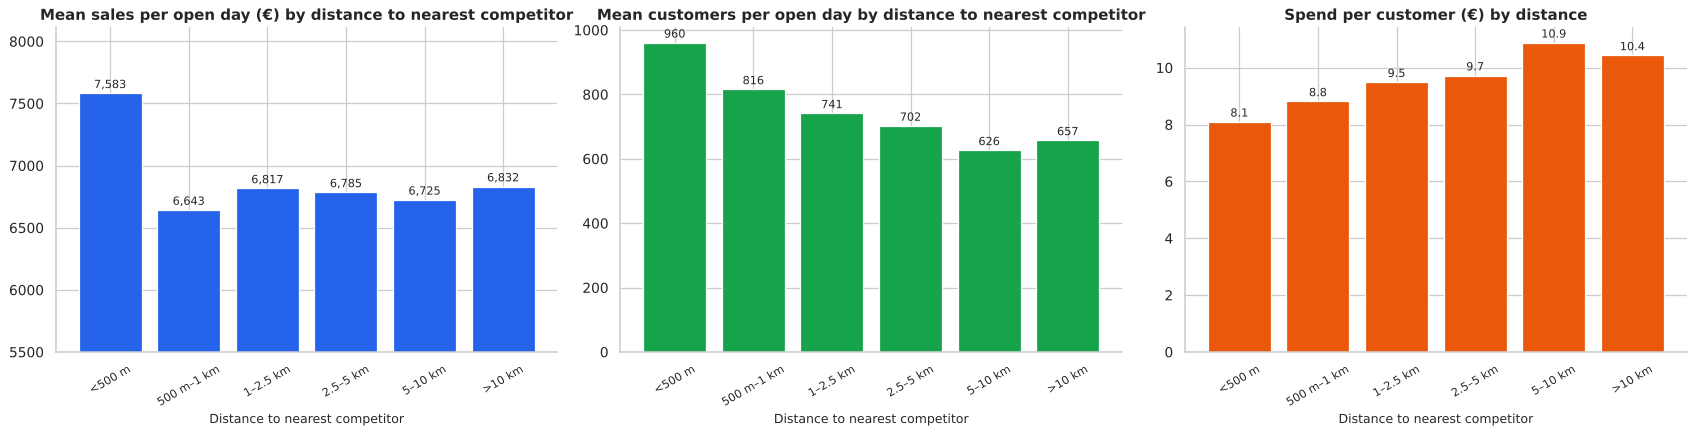

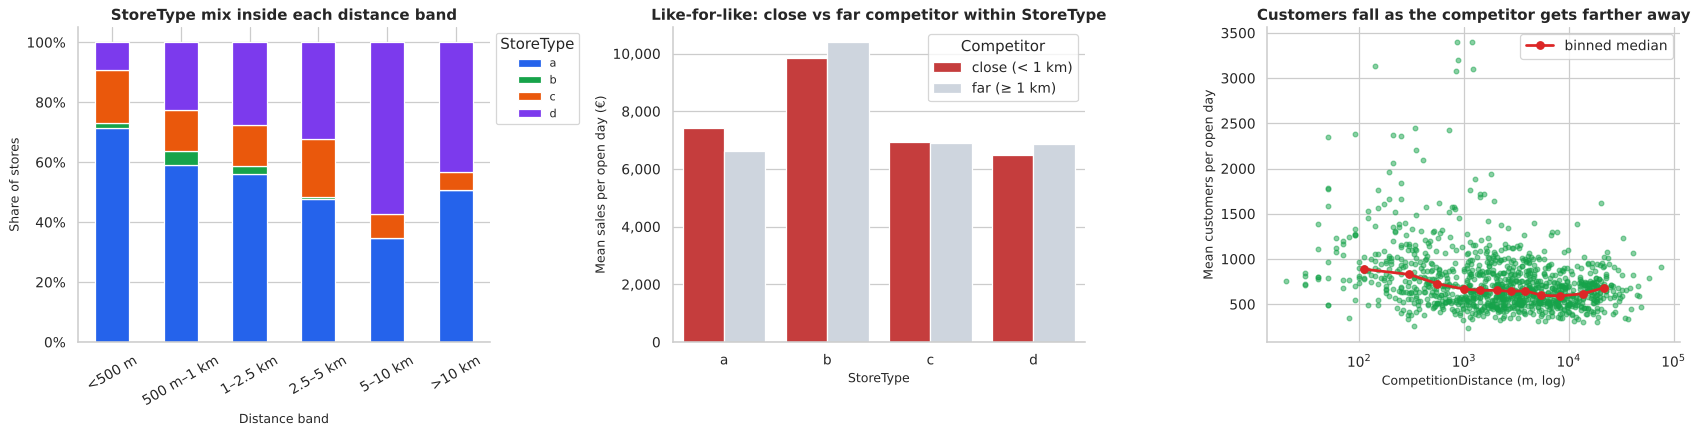

**Like-for-like table (store means)**

Competitor,close (< 1 km),far (≥ 1 km),close (< 1 km) (n),far (≥ 1 km) (n)
StoreType,,,,
a,"7,423","6,620",220,382
b,"9,863","10,393",9,8
c,"6,927","6,913",54,94
d,"6,468","6,877",45,303


Close-competition stores (<1 km): 328 of 1115; their StoreType mix: {'a': 0.67, 'c': 0.16, 'd': 0.14, 'b': 0.03}


In [ ]:
log.info("Q10: competition distance")
sd = store_lvl.copy(); sd["LogDist"] = np.log1p(sd.CompetitionDistance)
sd["band"] = pd.cut(sd.CompetitionDistance, [0, 500, 1000, 2500, 5000, 10000, 1e6], labels=["<500 m", "500 m–1 km", "1–2.5 km", "2.5–5 km", "5–10 km", ">10 km"])
for m_, nm in [("MeanSales", "Sales"), ("MeanCustomers", "Customers"), ("SalesPerCustomer", "Sales per customer")]:
    rs, ps_ = stats.spearmanr(sd.CompetitionDistance, sd[m_]); print(f"Spearman(distance, {nm:<18}) = {rs:+.3f}  (p = {ps_:.2g})")
bt = sd.groupby("band", observed=True).agg(stores=("MeanSales", "size"), sales=("MeanSales", "mean"), customers=("MeanCustomers", "mean"), sales_per_customer=("SalesPerCustomer", "mean"))
display(bt.style.format({"sales": "{:,.0f}", "customers": "{:,.0f}", "sales_per_customer": "{:.2f}"}))
mixb = pd.crosstab(sd.band, sd.StoreType, normalize="index")

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
for ax, col, ttl, f, c in zip(axes[:2], ["sales", "customers"], ["Mean sales per open day (€)", "Mean customers per open day"], ["{:,.0f}", "{:,.0f}"], [COLORS["blue"], COLORS["green"]]):
    ax.bar(bt.index.astype(str), bt[col], color=c); label_bars(ax, f); ax.set_title(ttl + " by distance to nearest competitor"); ax.set_xlabel("Distance to nearest competitor"); ax.tick_params(axis="x", labelrotation=30, labelsize=9)
axes[0].set_ylim(5500, bt.sales.max() * 1.07)
ax = axes[2]; ax.bar(bt.index.astype(str), bt.sales_per_customer, color=COLORS["orange"]); label_bars(ax, "{:.1f}"); ax.set_title("Spend per customer (€) by distance"); ax.set_xlabel("Distance to nearest competitor"); ax.tick_params(axis="x", labelrotation=30, labelsize=9)
plt.tight_layout(); fig_comp = fig; plt.show()

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
mixb.plot.bar(stacked=True, ax=axes[0], color=PALETTE[:4], rot=30); percent(axes[0]); axes[0].set_title("StoreType mix inside each distance band"); axes[0].set_xlabel("Distance band"); axes[0].set_ylabel("Share of stores"); axes[0].legend(title="StoreType", loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=9)
sd["Competitor"] = np.where(sd.CompetitionDistance < 1000, "close (< 1 km)", "far (≥ 1 km)")
within = sd.groupby(["StoreType", "Competitor"]).MeanSales.agg(["mean", "size"]).reset_index()
sns.barplot(data=within, x="StoreType", y="mean", hue="Competitor", order=list("abcd"), hue_order=["close (< 1 km)", "far (≥ 1 km)"], palette=[COLORS["red"], COLORS["light"]], ax=axes[1])
axes[1].set_title("Like-for-like: close vs far competitor within StoreType"); axes[1].set_ylabel("Mean sales per open day (€)"); thousands(axes[1])
for p, (_, rr) in zip(axes[1].patches, within.sort_values(["Competitor", "StoreType"], ascending=[True, True]).iterrows()): pass
axes[2].scatter(sd.CompetitionDistance, sd.MeanCustomers, s=14, alpha=.5, color=COLORS["green"]); axes[2].set_xscale("log")
bins = pd.qcut(np.log10(sd.CompetitionDistance), 12); mb = sd.groupby(bins, observed=True).agg(x=("CompetitionDistance", "median"), y=("MeanCustomers", "median"))
axes[2].plot(mb.x, mb.y, color=COLORS["red"], lw=2.2, marker="o", label="binned median"); axes[2].set_title("Customers fall as the competitor gets farther away"); axes[2].set_xlabel("CompetitionDistance (m, log)"); axes[2].set_ylabel("Mean customers per open day"); axes[2].legend()
plt.tight_layout(); plt.show()
display(Markdown("**Like-for-like table (store means)**")); display(within.pivot(index="StoreType", columns="Competitor", values="mean").join(within.pivot(index="StoreType", columns="Competitor", values="size"), rsuffix=" (n)").style.format("{:,.0f}"))
print(f"Close-competition stores (<1 km): {int((sd.CompetitionDistance < 1000).sum())} of {len(sd)}; their StoreType mix: {sd[sd.CompetitionDistance < 1000].StoreType.value_counts(normalize=True).round(2).to_dict()}")

**Answer Q10 — distance to the nearest competitor barely changes *average sales*, but it changes *who comes and how much they spend*.**
* **Overall:** Spearman(distance, mean sales) = **−0.03 (p = 0.35)** — essentially none. But **customers fall with distance (ρ = −0.28)** and **spend per customer rises (ρ = +0.48)**: stores with a competitor < 500 m away serve **960 customers/day at €8.10**, stores > 10 km away **657 customers at €10.43**.
* **City-centre / close-competition situation (proxy: competitor < 1 km; 328 stores = 29 %):** these are mostly StoreType `a` (67 %); they combine **high footfall with smaller baskets**. Like-for-like inside StoreType `a`, close-competition stores sell **+12 %** more (7,423 vs 6,620); in type `c` there is no difference (6,927 vs 6,913), in type `d` close stores sell **−6 %** less (6,468 vs 6,877); type `b` has too few stores (9 vs 8).
* **How to read it:** competitors open where people are (busy streets, city centres), so a nearby competitor is a *marker of a high-traffic location* rather than a cause of higher sales; the harm of a competitor appears when one **newly opens** next to an existing store (Q11).
* **Implication:** use `CompetitionDistance` on a log scale, **together with StoreType**, and predict *customers* and *sales* separately.

### Q11 — New / re-opened competitors: stores whose competition information is missing and later becomes available
**What the data can and cannot show.** `store.csv` is a single snapshot — `CompetitionDistance` has no time dimension, so a literal "NA → later a value" transition **cannot be observed**. What *is* available is the competitor's **opening month/year**: competitors that opened *inside* the observation window (Jan 2013 – Jul 2015) were "new" to those stores, and we can compare the store's sales before and after. For stores with a missing distance, we check what else is known.

2026-10-30 07:01:14,385 | INFO     | src.eda | Q11: new / re-opened competitors


,stores
Stores with NO competition distance,3
…of which also no opening date,3
Stores with distance but UNKNOWN opening date,351
Stores with a known opening date,761
…opened BEFORE the data starts (Jan 2013),570
…opened INSIDE the data window (new competitor),188
…opening date AFTER the last training day,3


Stores without distance: [[291, 'd'], [622, 'a'], [879, 'd']] (test store 622 is one of them → its 'Open' also had to be imputed)


**Sales / customers in the 91 days after a competitor opens vs the 91 days before — relative to 924 control stores** (treated stores: 141)

,real opening,placebo (180 days earlier),stores,share with a decline
metric,,,,
Customers,-5.9%,-0.9%,141,84%
Sales,-7.5%,-0.7%,141,87%


Wilcoxon (real openings, Sales): p = 1.7e-18 | placebo p = 0.012


,mean,size
group,,
close (< 1 km),-12.5%,39
far (≥ 1 km),-5.6%,102


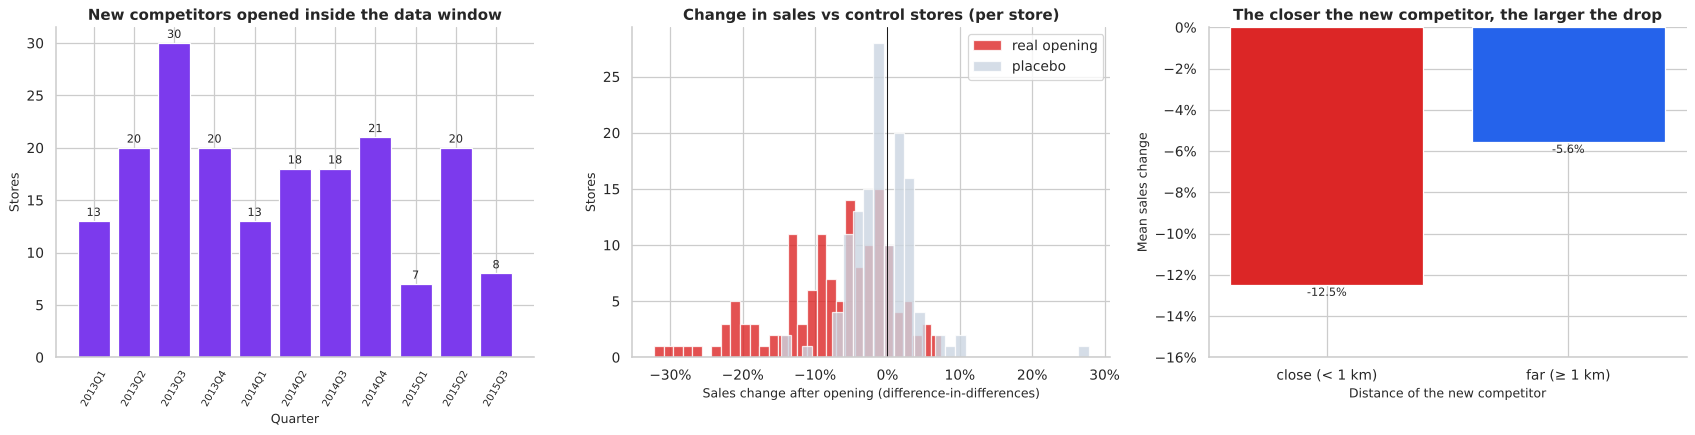

2026-10-30 07:01:21,188 | INFO     | src.visualization.plotting | Saved figure 11_new_competitors.png


PosixPath('/home/claude/project_6/reports/figures/11_new_competitors.png')

In [ ]:
log.info("Q11: new / re-opened competitors")
w0, w1 = train.Date.min(), train.Date.max()
st = store.copy()
facts = pd.Series({
    "Stores with NO competition distance": int((st.CompetitionDistanceMissing == 1).sum()),
    "…of which also no opening date": int(((st.CompetitionDistanceMissing == 1) & (st.CompetitionOpenDateKnown == 0)).sum()),
    "Stores with distance but UNKNOWN opening date": int(((st.CompetitionDistanceMissing == 0) & (st.CompetitionOpenDateKnown == 0)).sum()),
    "Stores with a known opening date": int(st.CompetitionOpenDateKnown.sum()),
    "…opened BEFORE the data starts (Jan 2013)": int((st.CompetitionOpenSinceDate <= w0).sum()),
    "…opened INSIDE the data window (new competitor)": int(((st.CompetitionOpenSinceDate > w0) & (st.CompetitionOpenSinceDate <= w1)).sum()),
    "…opening date AFTER the last training day": int((st.CompetitionOpenSinceDate > w1).sum())}, name="stores")
display(facts.to_frame())
print("Stores without distance:", st.loc[st.CompetitionDistanceMissing == 1, ["Store", "StoreType"]].values.tolist(), "(test store 622 is one of them → its 'Open' also had to be imputed)")

# event study: sales 91 days after the opening vs 91 days before, relative to control stores in the SAME calendar windows
P = {"Sales": op.pivot_table(index="Date", columns="Store", values="Sales"), "Customers": op.pivot_table(index="Date", columns="Store", values="Customers")}
treated = st[(st.CompetitionOpenSinceDate >= w0 + pd.Timedelta(days=91)) & (st.CompetitionOpenSinceDate <= w1 - pd.Timedelta(days=91))]
control = st[(st.CompetitionDistanceMissing == 0) & ((st.CompetitionOpenDateKnown == 0) | (st.CompetitionOpenSinceDate <= w0) | (st.CompetitionOpenSinceDate > w1))].Store.tolist()
def event_study(shift_days=0):
    out = []
    for r in treated.itertuples():
        d = r.CompetitionOpenSinceDate - pd.Timedelta(days=shift_days)
        pre, post = (d - pd.Timedelta(days=91), d - pd.Timedelta(days=1)), (d, d + pd.Timedelta(days=90))
        for m_ in ["Sales", "Customers"]:
            M = P[m_]; s_pre, s_post = M.loc[pre[0]:pre[1], r.Store].mean(), M.loc[post[0]:post[1], r.Store].mean()
            c_ratio = (M.loc[post[0]:post[1], control].mean() / M.loc[pre[0]:pre[1], control].mean()).mean()
            if np.isfinite(s_pre) and np.isfinite(s_post) and s_pre > 0: out.append((r.Store, m_, s_post / s_pre, c_ratio, (s_post / s_pre) / c_ratio - 1, r.CompetitionDistance, r.StoreType))
    return pd.DataFrame(out, columns=["Store", "metric", "treated_ratio", "control_ratio", "did", "dist", "StoreType"])
es = event_study(0); placebo = event_study(180)           # placebo: pretend the competitor opened 180 days earlier
res_tab = pd.DataFrame({"real opening": es.groupby("metric").did.mean(), "placebo (180 days earlier)": placebo.groupby("metric").did.mean(),
                        "stores": es.groupby("metric").size(), "share with a decline": es.groupby("metric").did.apply(lambda x: (x < 0).mean())})
display(Markdown(f"**Sales / customers in the 91 days after a competitor opens vs the 91 days before — relative to {len(control)} control stores** (treated stores: {es.Store.nunique()})"))
display(res_tab.style.format({"real opening": "{:+.1%}", "placebo (180 days earlier)": "{:+.1%}", "share with a decline": "{:.0%}"}))
sales_es = es[es.metric == "Sales"]
print("Wilcoxon (real openings, Sales): p =", f"{stats.wilcoxon(sales_es.did).pvalue:.2g}", "| placebo p =", f"{stats.wilcoxon(placebo[placebo.metric == 'Sales'].did).pvalue:.2g}")
near = sales_es.assign(group=np.where(sales_es.dist < 1000, "close (< 1 km)", "far (≥ 1 km)")).groupby("group").did.agg(["mean", "size"]); display(near.style.format({"mean": "{:+.1%}"}))

fig, axes = plt.subplots(1, 3, figsize=(19, 5))
q = st[(st.CompetitionOpenSinceDate > w0) & (st.CompetitionOpenSinceDate <= w1)].CompetitionOpenSinceDate.dt.to_period("Q").value_counts().sort_index()
axes[0].bar(q.index.astype(str), q.values, color=COLORS["purple"]); label_bars(axes[0]); axes[0].set_title("New competitors opened inside the data window"); axes[0].set_xlabel("Quarter"); axes[0].set_ylabel("Stores"); axes[0].tick_params(axis="x", labelrotation=60, labelsize=8)
axes[1].hist(sales_es.did, bins=30, color=COLORS["red"], alpha=.8, label="real opening"); axes[1].hist(placebo[placebo.metric == "Sales"].did, bins=30, color=COLORS["light"], alpha=.8, label="placebo")
axes[1].axvline(0, color="k", lw=.8); percent(axes[1], "x"); axes[1].set_title("Change in sales vs control stores (per store)"); axes[1].set_xlabel("Sales change after opening (difference-in-differences)"); axes[1].set_ylabel("Stores"); axes[1].legend()
axes[2].bar(near.index, near["mean"], color=[COLORS["red"], COLORS["blue"]]); percent(axes[2]); label_bars(axes[2], "{:+.1%}"); axes[2].set_ylim(-0.16, 0); axes[2].set_title("The closer the new competitor, the larger the drop"); axes[2].set_ylabel("Mean sales change"); axes[2].set_xlabel("Distance of the new competitor")
plt.tight_layout(); fig_new = fig; plt.show()
save_figure(fig_new, "11_new_competitors", cfg)

**Answer Q11 — a new competitor costs a store roughly 5–8 % of sales for the following three months; the closer the competitor, the larger the loss.**
* **What the data allows:** `store.csv` is a single snapshot, so a literal "missing → later available" change is **not observable**. The 3 stores without a competition distance (291, 622, 879) also have **no opening date** → most likely no known competitor; 351 more stores have a distance but **no opening date** (competitor present, start unknown). The *openings* are observable: **570** competitors opened before 2013, **188 inside the data window** (13–30 per quarter) and **3 on 1 August 2015 — the first day of the test period** (stores 688, 1020, 1072; `CompetitionActive` is 0 in train and switches to 1 at the forecast start).
* **Event study:** for 141 stores whose competitor opened inside the window (≥ 91 days of data on both sides), sales in the 91 days **after** the opening are **7.5 % lower** than in the 91 days before, relative to 924 control stores in the same calendar windows (customers **−5.9 %**); **87 %** of the stores decline. A **placebo test** (pretending the competitor opened 180 days earlier) gives only −0.7 %, so the drop coincides with the opening.
* **Distance matters:** close competitors (< 1 km, 39 stores) cost **−12.5 %**, farther ones (102 stores) **−5.6 %**.
* **Business implications:** (1) monitor competitor openings and treat the first ~3 months as a risk window; (2) use targeted promotions / assortment for exposed stores; (3) a *re-opened* competitor is plausible for the stores whose information is incomplete — worth confirming with the business; (4) in modelling, use `CompetitionOpenMonths` and `CompetitionActive` (already built) — two test stores (1020, 1072) get a new competitor on the first forecast day, so their forecast should be checked against the −5…−8 % pattern.
* *Limitations:* opening dates are approximate (month level); no store/week fixed effects; effect on a few stores per quarter, not causal proof.

## 7. EDA summary

### Key findings (data)
1. **Data quality is good:** no duplicates, no negative values, `DayOfWeek` consistent with `Date`. Real issues: 54 open-but-zero-sales days, 11 missing `Open` values in test (store 622), structural gaps in `store.csv` (544 non-Promo2 stores; 354 unknown competitor opening dates, 3 unknown distances) and a **data gap: 180 stores have no rows in Jul–Dec 2014**.
2. **Train/test are consistent:** promotions are chain-wide, Mon–Fri only, and similarly distributed (46.3 % in test vs 44.5 % in train for the same 856 stores; 44.6 % for all 1,115 stores — both numbers are correct, they use different train populations); test = 856 stores, 48 days (6.9 weeks), only public holidays.
3. **Sales is right-skewed** (log makes it symmetric); **Customers explains most of Sales (ρ = 0.83)** but is unknown in the future.
4. **Outliers are calendar-driven** (13.6 % of December days) → flagged, not removed.

### Business insights
| Area | Insight |
|---|---|
| **Customers** | Footfall drives sales (≈ €6.4 per extra customer). StoreType `b` = 2,000 customers/day but €5 baskets; `d` = fewer customers, €11 baskets. |
| **Promotions** | **+39 % sales** (+20 % customers, +15 % spend per customer); all stores gain, but lift ranges from +2 % to +102 %. Weakest: StoreType `b` / Extra assortment (+11–20 %); strongest: type `d`, small stores, Promo2 stores. Monday promos (+57 %) beat Friday (+22 %). |
| **Holidays** | Stores are closed on 97–98 % of state holidays. Sales build up **before** Easter (+32…+48 %) and Christmas (+42…+60 %) and dip **after** Easter (−15 %). |
| **Seasonality** | December +26 % vs the other months' average; pay-day rhythm inside the month (days 1–5 and 29–31 strongest); ≈ +3 % yearly growth. |
| **Competition** | Distance does not change average sales but changes the mix (closer = more customers, smaller baskets). **A new competitor costs ≈ 5–8 % of sales for 3 months (−12.5 % if < 1 km).** |
| **Stores** | 83 % of the stores open every weekday; only 33 stores open on Sundays (≈ type `b`). Extended assortment sells ≈ +10 % more than basic in types `a`, `d` (bigger baskets). After a long closure customers return +50 % in week 1. |

### Modelling implications (for Part 2 — ML and LSTM)
* **Target:** train regressors only on `Open == 1 & Sales > 0`; predict **0 for `Open == 0`**. Consider `log1p(Sales)` and a relative-error metric (**RMSPE** is the natural choice for this dataset, to be justified in Part 2).
* **Validation:** use the **last 42 days** as a time-based hold-out (never random K-fold); recompute store-history statistics per split (`history_features.py`).
* **Features to keep:** `Promo`, `DayOfWeek`, `Open`, `StateHoliday` (+ the 4 holiday-distance features), `Month`/`WeekOfYear`/`DayOfMonth` parts, `DaysToChristmas`, `StoreType`, `Assortment`, competition features and `Promo2Active`. Allow interactions (Promo × weekday, StoreType × Promo).
* **Do NOT use as features:** `Customers`, `SalesOutlier`, `CustomersOutlier`, `OpenZeroSales`, `ClosedWithSales` (leakage/diagnostic).
* **Customers as a second target** for the dashboard; per-store history (`StoreMeanSales`, `StoreMeanCustomers`, spend per customer) is a strong leak-safe feature (r = 0.77 with sales in the last 6 weeks).
* **LSTM:** time series are per store (or aggregated); keep the 2014 gap (180 stores) in mind — do not fill with zeros; the series has a weekly rhythm (period 7), a promo alternation (period 14) and strong yearly peaks.
* **Scaling:** trees need none; use `StandardScaler` for distance-based or linear models and for neural-network inputs; the LSTM part needs MinMax to (−1, 1) fitted on the training window only.
* **Known limitations:** holiday distance is capped at 30 days and mostly unknown near the end of the data; competitor opening dates are month-level approximations; no profit / margin information.

### Interim presentation (3–5 slides)
The slide-by-slide content lives in `reports/interim_presentation_content.md`; the figures it uses were saved to `reports/figures/` by this notebook.

## 8. Outputs of Part 1 (for Part 2)

In [ ]:
out_dir = get_dir(cfg, "processed_dir")
rows = [(p.name, f"{p.stat().st_size / 1e6:.2f} MB") for p in sorted(out_dir.glob("*")) if p.name != ".gitkeep"]
display(pd.DataFrame(rows, columns=["file in data/processed/", "size"]))
print("Figures saved for the interim presentation:", sorted(p.name for p in get_dir(cfg, "figures_dir").glob("*.png")))

# Part 2 only needs these three lines:
tr_p = pd.read_parquet(out_dir / cfg["processed_files"]["train"]); te_p = pd.read_parquet(out_dir / cfg["processed_files"]["test"])
print(f"train_processed: {tr_p.shape} | test_processed: {te_p.shape} | features in manifest: "
      f"{len(manifest['numeric_features']) + len(manifest['binary_features']) + len(manifest['categorical_features'])}")
log.info("EDA notebook finished")

,file in data/processed/,size
0,cleaning_report.json,0.00 MB
1,feature_manifest.json,0.00 MB
2,holiday_calendar.csv,0.59 MB
3,store_data_gaps.csv,0.01 MB
4,store_processed.csv,0.07 MB
5,test_processed.parquet,0.38 MB
6,train_processed.parquet,8.50 MB


Figures saved for the interim presentation: ['01_time_series_overview.png', '03_seasonality.png', '05_promo_effect.png', '05b_promo_by_storetype.png', '06_promo_effectiveness.png', '07_school_holiday.png', '08_data_gaps.png', '11_new_competitors.png']


train_processed: (1017209, 50) | test_processed: (41088, 46) | features in manifest: 36
2026-10-30 07:01:21,509 | INFO     | src.eda | EDA notebook finished


### Part 1 checklist
| Requirement | Where |
|---|---|
| Clean modular structure, configurable paths, logging | `config/config.yaml`, `src/utils/`, `logs/project.log` |
| Dataset loading (CSV/XLSX), missing-file error | `src/data/loader.py` |
| Data inspection + quality summary | section 1–2, `src/data/inspection.py` |
| Missing-value handling | section 2–3, `src/data/cleaning.py` |
| Outlier detection + handling | section 3, `src/data/outliers.py` |
| Date features, holiday-distance features, promo / competition features | section 4, `src/features/` |
| No leakage (manifest, history stats cut-off) | section 4, `feature_manifest.json` |
| EDA: univariate, bivariate, multivariate, correlations, interactions | section 5 (incl. 5.4 Promo2 / PromoInterval, 5.5 store-level) |
| **All 11 questions** | section 6 (Q1 … Q11) |
| Insights, modelling implications | section 7 |
| Processed data saved separately from raw data | `data/processed/` |
| SchoolHoliday impact (sales, customers, by StoreType, × StateHoliday) | section 5.6 |
| StoreType-wise promotion lift with sample counts | Q5-B (after Q5) |
| Data-gap analysis (missing dates, incomplete stores) | section 5.7, `data/processed/store_data_gaps.csv` |
| Statistical interpretation guide (correlation, lift, p-value, causation) | section 5.8 |
